In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_49.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_90.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_77.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_66.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_54.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_42.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_81.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_72.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Data Extraction

In [3]:
## train_csv
train_df=pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv")

In [4]:
train_df

,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0
...,...,...
764,audio_390.wav,5.0
765,audio_766.wav,4.5
766,audio_571.wav,2.0
767,audio_393.wav,4.5


In [5]:
train_df.head()

,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


In [6]:
#test_dataframe_info
test_df=pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv")
print(test_df.shape)
print(test_df.info)
print(test_df.head())

(216, 2)
<bound method DataFrame.info of           filename  label
0    audio_128.wav     -1
1    audio_156.wav     -1
2     audio_19.wav     -1
3    audio_108.wav     -1
4    audio_206.wav     -1
..             ...    ...
211  audio_184.wav     -1
212   audio_24.wav     -1
213  audio_140.wav     -1
214  audio_165.wav     -1
215  audio_170.wav     -1

[216 rows x 2 columns]>
        filename  label
0  audio_128.wav     -1
1  audio_156.wav     -1
2   audio_19.wav     -1
3  audio_108.wav     -1
4  audio_206.wav     -1


In [7]:
## train_df_info
train_df.isnull().sum()
print(train_df.info)
train_df.describe


<bound method DataFrame.info of           filename  label
0    audio_192.wav    3.0
1    audio_436.wav    3.0
2    audio_447.wav    3.5
3    audio_126.wav    2.0
4     audio_61.wav    2.0
..             ...    ...
764  audio_390.wav    5.0
765  audio_766.wav    4.5
766  audio_571.wav    2.0
767  audio_393.wav    4.5
768  audio_691.wav    4.0

[769 rows x 2 columns]>


<bound method NDFrame.describe of           filename  label
0    audio_192.wav    3.0
1    audio_436.wav    3.0
2    audio_447.wav    3.5
3    audio_126.wav    2.0
4     audio_61.wav    2.0
..             ...    ...
764  audio_390.wav    5.0
765  audio_766.wav    4.5
766  audio_571.wav    2.0
767  audio_393.wav    4.5
768  audio_691.wav    4.0

[769 rows x 2 columns]>

In [8]:
## extracting the audio files
import os
TRAIN_AUDIO_DIR = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train"

train_df["audio_path"] = train_df["filename"].apply(
    lambda x: os.path.join(TRAIN_AUDIO_DIR, x)
)


train_df["audio_path"].apply(os.path.exists).value_counts()
train_df.head()

,filename,label,audio_path
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...


In [9]:
## loading the audio files
import librosa

audio, sr = librosa.load(
    train_df.loc[0, "audio_path"],
    sr=None
)

print("Sampling rate:", sr)
print("Audio shape:", audio.shape)
print("Duration:", len(audio) / sr, "seconds")

Sampling rate: 16000
Audio shape: (968134,)
Duration: 60.508375 seconds


In [10]:
## analyzing audio durations
import librosa

def get_audio_duration(path):
    audio, sr = librosa.load(path, sr=None)
    return len(audio) / sr


train_df["duration"] = train_df["audio_path"].apply(get_audio_duration)

In [11]:
train_df[["filename", "label", "duration"]]

,filename,label,duration
0,audio_192.wav,3.0,60.508375
1,audio_436.wav,3.0,60.074688
2,audio_447.wav,3.5,60.074688
3,audio_126.wav,2.0,45.060000
4,audio_61.wav,2.0,45.300000
...,...,...,...
764,audio_390.wav,5.0,60.074688
765,audio_766.wav,4.5,60.074688
766,audio_571.wav,2.0,49.450688
767,audio_393.wav,4.5,60.010688


In [12]:
train_df.head()

,filename,label,audio_path,duration
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000


# Exploratory Data Analysis(EDA)

In [13]:
## Statistical Understanding
train_df["duration"].describe()

count    769.000000
mean      55.781067
std        7.908964
min       20.060000
25%       54.186687
50%       60.074688
75%       60.074688
max       61.040000
Name: duration, dtype: float64

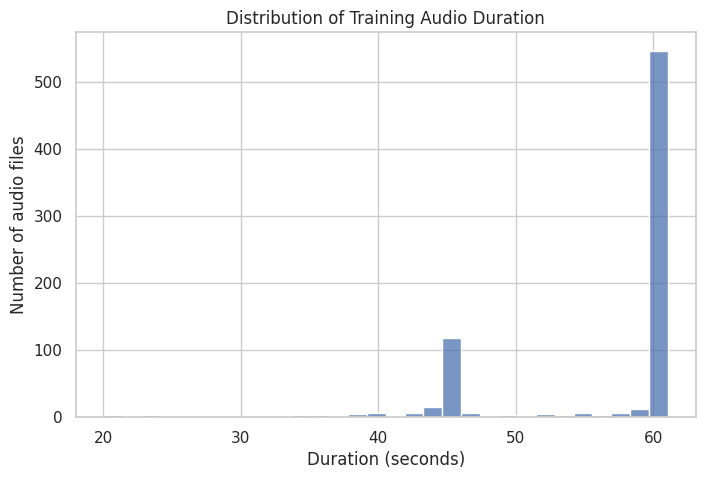

In [14]:
## Durations Distribution
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))


sns.histplot(data=train_df, x="duration", bins=30)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of audio files")
plt.title("Distribution of Training Audio Duration")

plt.show()

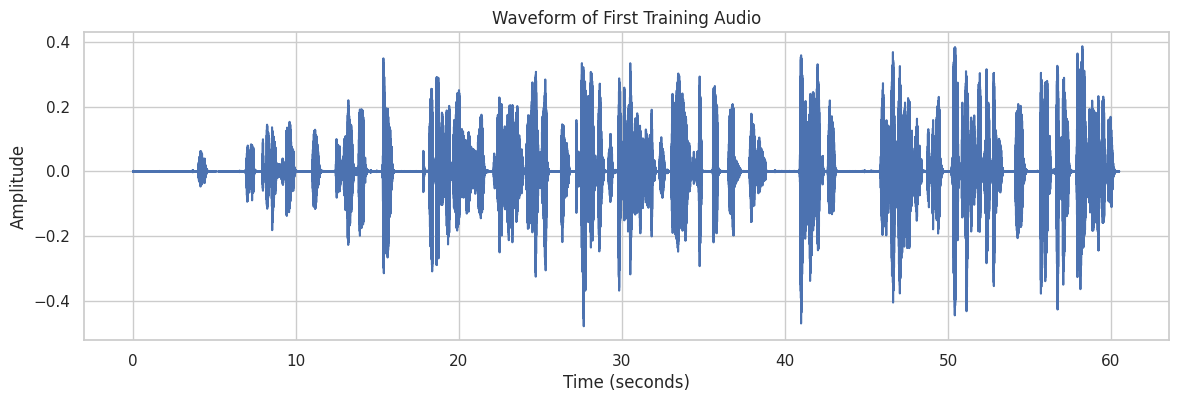

In [15]:
#creating time axis for signal plotting
import numpy as np

time = np.arange(len(audio)) / sr

## signal plotting
plt.figure(figsize=(14, 4))

plt.plot(time, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Waveform of First Training Audio")

plt.show()

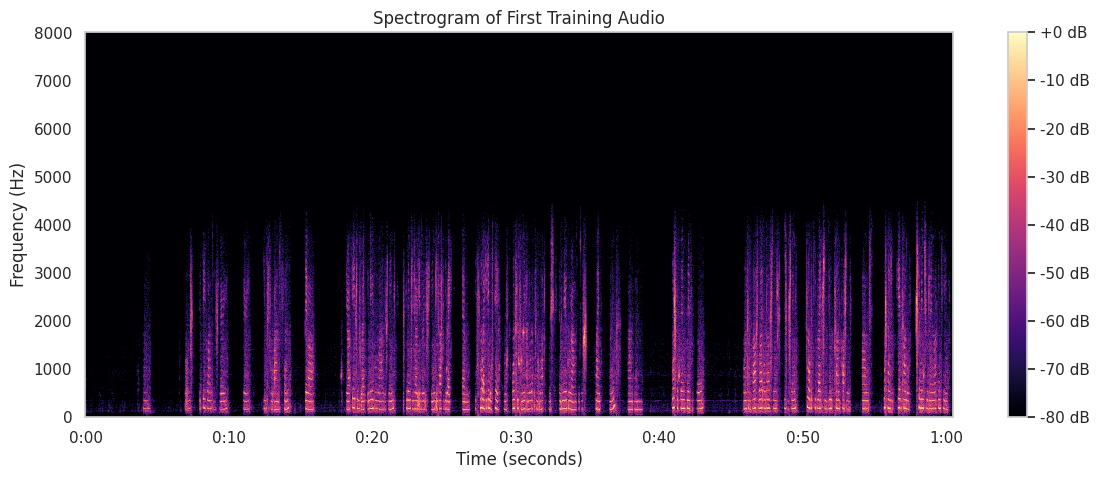

In [16]:
## inspecting the spectrogram
import librosa.display

## transforming 1D audio to 2D spectrogram
D = librosa.stft(audio)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

## spectrogram plotting
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")

plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram of First Training Audio")

plt.show()

# Transcription of Audio

In [17]:
## installing whisper
!apt-get update && !apt-get install -y ffmpeg
!pip install -U openai-whisper

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:6 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:10 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,886 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:12 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,545 kB]
Get:13 http://archive.ubuntu.com/ubuntu

In [18]:
## loading the whisper model
import torch
import whisper

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load model onto the selected device
model = whisper.load_model("base", device=device)

Using device: cuda


100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 318MiB/s]


In [19]:
## importing the whisper model
import whisper
model = whisper.load_model("base")

In [20]:
## transcribing one audio file
train_df.loc[0, "audio_path"]
result = model.transcribe(
    str(train_df.loc[0, "audio_path"])
)

## whisper results in dictionary format
result.keys()
transcript=result["text"]
print(transcript)
print("Detected language:", result["language"])
result["segments"][:3]

 Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.
Detected language: en


[{'id': 0,
  'seek': 0,
  'start': 0.0,
  'end': 15.280000000000001,
  'text': ' Well, this petite land is very, very beautiful and fun.',
  'tokens': [50364,
   1042,
   11,
   341,
   18319,
   2117,
   307,
   588,
   11,
   588,
   2238,
   293,
   1019,
   13,
   51128],
  'temperature': 0.0,
  'avg_logprob': -0.768155269133739,
  'compression_ratio': 1.3177570093457944,
  'no_speech_prob': 0.44321829080581665},
 {'id': 1,
  'seek': 0,
  'start': 15.280000000000001,
  'end': 21.72,
  'text': ' There are fleets like the navy around the swing.',
  'tokens': [51128,
   821,
   366,
   7025,
   1385,
   411,
   264,
   31319,
   926,
   264,
   11173,
   13,
   51450],
  'temperature': 0.0,
  'avg_logprob': -0.768155269133739,
  'compression_ratio': 1.3177570093457944,
  'no_speech_prob': 0.44321829080581665},
 {'id': 2,
  'seek': 0,
  'start': 21.72,
  'end': 24.32,
  'text': ' The swing usually enjoys this swing.',
  'tokens': [51450, 440, 11173, 2673, 29750, 341, 11173, 13, 51580],

In [21]:
## Evaluating the transcription
print("Ground Truth Grammar Score:", train_df.loc[0, "label"])
print("\nTranscript:")
print(result["text"])
print("\nDetected Language:", result["language"])

Ground Truth Grammar Score: 3.0

Transcript:
 Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.

Detected Language: en


In [22]:
## segment of speech analysis
for segment in result["segments"][:10]:
    print(
        f"{segment['start']:.2f}s - "
        f"{segment['end']:.2f}s : "
        f"{segment['text'].strip()}"
    )

0.00s - 15.28s : Well, this petite land is very, very beautiful and fun.
15.28s - 21.72s : There are fleets like the navy around the swing.
21.72s - 24.32s : The swing usually enjoys this swing.
24.32s - 29.00s : It has to be like, it's more like a game of play.
29.00s - 31.40s : Because once it's in it and the other thing,
31.40s - 34.32s : we'll have to finish and the miracle round,
34.32s - 37.72s : which is fine for me.
37.72s - 46.88s : And most of them play for some parts.
46.88s - 50.20s : Why others use these swings?
50.20s - 55.60s : Some of the people like to do sound classes.


In [23]:
## word analysis
transcript = result["text"].strip()

words = transcript.split()

print("Number of words:", len(words))
print("Number of characters:", len(transcript))

Number of words: 91
Number of characters: 478


## Calculating the Speaking Rate

          
          Speaking Rate =   Number of Words
                           ------------------
                          Duration in Minutes

In [24]:
## Calculating the Speaking rate  (A flurency Feature)
duration = len(audio) / sr
duration_minutes = duration / 60

word_count = len(words)

words_per_minute = word_count / duration_minutes

print(f"Duration: {duration:.2f} seconds")
print(f"Words: {word_count}")
print(f"Speaking rate: {words_per_minute:.2f} words/minute")

Duration: 60.51 seconds
Words: 91
Speaking rate: 90.24 words/minute


In [25]:
## empty Check
if not transcript:
    print("Warning: Empty transcript")
else:
    print("Transcript successfully extracted.")

Transcript successfully extracted.


## Transcribing all the files

In [26]:

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

## explicity mentioning the device to use
model = whisper.load_model("base", device=device)

Device: cuda


In [27]:
## Transcription Function
def transcribe_audio(audio_path):
    result = model.transcribe(
        str(audio_path),
        language="en",
        fp16=(device == "cuda")
    )
    
    return result["text"].strip()

In [28]:
train_df

,filename,label,audio_path,duration
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000
...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688


In [29]:
test_transcript = transcribe_audio(
    train_df.loc[0, "audio_path"]
)

print(test_transcript)

Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.


In [30]:
## applying function to all the audio files
train_df["transcript"] = train_df["audio_path"].apply(
    transcribe_audio
)

In [31]:
## loading and stroing the transciption in csv files
TRANSCRIPT_PATH = "/kaggle/working/train_transcripts.csv"

train_df.to_csv(
    TRANSCRIPT_PATH,
    index=False
)

print(f"Saved transcripts to: {TRANSCRIPT_PATH}")

Saved transcripts to: /kaggle/working/train_transcripts.csv


In [32]:
saved_df = pd.read_csv(TRANSCRIPT_PATH)

print("Rows:", len(saved_df))
print("Columns:", saved_df.columns.tolist())

display(
    saved_df[["filename", "label", "transcript"]].head()
)

Rows: 769
Columns: ['filename', 'label', 'audio_path', 'duration', 'transcript']


,filename,label,transcript
0,audio_192.wav,3.0,"Well, this petite land is very, very beautiful..."
1,audio_436.wav,3.0,"To see no of a school playground, our playgrou..."
2,audio_447.wav,3.5,I favorite place to visit is the beach. I love...
3,audio_126.wav,2.0,"Once upon a time, we, with five friends, went ..."
4,audio_61.wav,2.0,"Well, when I was a child, I remember I went to..."


In [33]:
### checking for emtpy transcripts
empty_transcripts = train_df["transcript"].isna() | (
    train_df["transcript"].str.strip() == ""
)

print("Empty transcripts:", empty_transcripts.sum())

Empty transcripts: 6


In [34]:
## chekcing short transcripts
train_df["word_count"] = train_df["transcript"].str.split().str.len()

train_df["word_count"].describe()

count    769.000000
mean      98.382315
std       28.624491
min        0.000000
25%       81.000000
50%       99.000000
75%      120.000000
max      165.000000
Name: word_count, dtype: float64

In [35]:
## finding the empty transcipts
empty_mask = train_df["transcript"].fillna("").str.strip().eq("")

empty_df = train_df.loc[
    empty_mask,
    ["filename", "label", "audio_path", "duration"]
]

print("Empty transcripts:", len(empty_df))

display(empty_df)

Empty transcripts: 6


,filename,label,audio_path,duration
41,audio_5069.wav,0.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
338,audio_5038.wav,0.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
374,audio_5058.wav,0.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
458,audio_5049.wav,0.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
485,audio_5042.wav,0.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688
501,audio_5060.wav,0.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688


In [36]:
## chekcing is audio valid for the empty transcripts
for _, row in empty_df.iterrows():
    audio, sr = librosa.load(row["audio_path"], sr=None)

    rms = np.sqrt(np.mean(audio ** 2))

    print(
        f"{row['filename']} | "
        f"Duration: {len(audio)/sr:.2f}s | "
        f"RMS: {rms:.6f}"
    )

audio_5069.wav | Duration: 60.07s | RMS: 0.114312
audio_5038.wav | Duration: 60.07s | RMS: 0.141381
audio_5058.wav | Duration: 60.07s | RMS: 0.090123
audio_5049.wav | Duration: 60.07s | RMS: 0.138181
audio_5042.wav | Duration: 60.07s | RMS: 0.120877
audio_5060.wav | Duration: 60.07s | RMS: 0.135908


In [37]:
## removing the empty transcipts

model_df = train_df[
    train_df["transcript"].fillna("").str.strip() != ""
].copy()

print("Original samples:", len(train_df))
print("Samples with transcripts:", len(model_df))
print("Removed samples:", len(train_df) - len(model_df))

Original samples: 769
Samples with transcripts: 763
Removed samples: 6


In [38]:
## adding word and sentence count features
model_df["word_count"] = (
    model_df["transcript"]
    .str.split()
    .str.len()
)

## character count
model_df["char_count"] = model_df["transcript"].str.len()

## inspection
model_df[
    ["filename", "label", "word_count", "char_count", "transcript"]
].head()

## description
model_df[["word_count", "char_count"]].describe()

,word_count,char_count
count,763.000000,763.000000
mean,99.155963,524.366972
std,27.367875,145.821869
min,4.000000,25.000000
25%,81.000000,426.500000
50%,99.000000,526.000000
75%,120.500000,631.000000
max,165.000000,951.000000


In [39]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369
...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599


## Sentence Segmentation

In [40]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [41]:
from nltk.tokenize import sent_tokenize

## testing on one transcipt
text = model_df.iloc[0]["transcript"]

sentences = sent_tokenize(text)

print("Transcript:")
print(text)

print("\nSentences:")
for sentence in sentences:
    print("-", sentence)

print("\nNumber of sentences:", len(sentences))

Transcript:
Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.

Sentences:
- Well, this petite land is very, very beautiful and fun.
- There are fleets like the navy around the swing.
- The swing usually enjoys this swing.
- It has to be like, it's more like a game of play.
- Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me.
- And most of them play for some parts.
- Why others use these swings?
- Some of the people like to do sound classes.
- Most times, here the sound of stringent children, lasting kids.


In [42]:
## counting sentences after tokenization
def count_sentences(text):
    return len(sent_tokenize(text))

In [43]:
## adding the sentence count feature

model_df["sentence_count"] = model_df["transcript"].apply(
    count_sentences
)

model_df[["transcript", "sentence_count"]].head()

,transcript,sentence_count
0,"Well, this petite land is very, very beautiful...",9
1,"To see no of a school playground, our playgrou...",5
2,I favorite place to visit is the beach. I love...,12
3,"Once upon a time, we, with five friends, went ...",2
4,"Well, when I was a child, I remember I went to...",5


## Calculating the Average Sentence Length for Understanding the Speaker's Ability to form a longer sentence.It helps in providing a signal to the model but not necessarily the main factor for grammmer detection beacause longer sentence can have gramatical errors

          Average Sentence Length= Total Words
                                  -------------
                                 Number of Sentences

In [44]:
## function for the average sentence length
def average_sentence_length(text):
    sentences = sent_tokenize(text)

    if len(sentences) == 0:
        return 0

    word_counts = [
        len(sentence.split())
        for sentence in sentences
    ]

    return np.mean(word_counts)

model_df["avg_sentence_length"] = model_df["transcript"].apply(
    average_sentence_length
)

In [45]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count,sentence_count,avg_sentence_length
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478,9,10.111111
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619,5,23.200000
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743,12,12.500000
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464,2,49.500000
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369,5,14.800000
...,...,...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730,7,18.714286
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463,6,16.000000
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442,3,27.333333
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599,8,14.875000


In [46]:
## max sentence length
def max_sentence_length(text):
    sentences = sent_tokenize(text)

    if not sentences:
        return 0

    return max(
        len(sentence.split())
        for sentence in sentences
    )

model_df["max_sentence_length"] = model_df["transcript"].apply(
    max_sentence_length
)

In [47]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count,sentence_count,avg_sentence_length,max_sentence_length
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478,9,10.111111,22
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619,5,23.200000,42
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743,12,12.500000,19
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464,2,49.500000,89
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369,5,14.800000,29
...,...,...,...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730,7,18.714286,32
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463,6,16.000000,32
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442,3,27.333333,44
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599,8,14.875000,28


In [48]:
## Volcabulary Diversity Calculation
def vocabulary_diversity(text):
    words = text.lower().split()

    if not words:
        return 0

    unique_words = set(words)

    return len(unique_words) / len(words)


model_df["vocabulary_diversity"] = model_df["transcript"].apply(
    vocabulary_diversity
)

In [49]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count,sentence_count,avg_sentence_length,max_sentence_length,vocabulary_diversity
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478,9,10.111111,22,0.725275
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619,5,23.200000,42,0.500000
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743,12,12.500000,19,0.533333
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464,2,49.500000,89,0.494949
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369,5,14.800000,29,0.635135
...,...,...,...,...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730,7,18.714286,32,0.648855
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463,6,16.000000,32,0.572917
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442,3,27.333333,44,0.573171
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599,8,14.875000,28,0.571429


## Repeatation Ratio
### Repeating words frequently indicates the inability to speak properly
         Repeatation_Ratio=1-Unique_Words
                             -----------
                             Total Words


In [50]:
## Calculating Repeating Words
def repetition_ratio(text):
    words = text.lower().split()

    if not words:
        return 0

    unique_words = set(words)

    return 1 - (len(unique_words) / len(words))

model_df["repetition_ratio"] = model_df["transcript"].apply(
    repetition_ratio
)

In [51]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count,sentence_count,avg_sentence_length,max_sentence_length,vocabulary_diversity,repetition_ratio
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478,9,10.111111,22,0.725275,0.274725
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619,5,23.200000,42,0.500000,0.500000
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743,12,12.500000,19,0.533333,0.466667
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464,2,49.500000,89,0.494949,0.505051
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369,5,14.800000,29,0.635135,0.364865
...,...,...,...,...,...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730,7,18.714286,32,0.648855,0.351145
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463,6,16.000000,32,0.572917,0.427083
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442,3,27.333333,44,0.573171,0.426829
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599,8,14.875000,28,0.571429,0.428571


In [52]:
feature_columns = [
    "word_count",
    "char_count",
    "sentence_count",
    "avg_sentence_length",
    "max_sentence_length",
    "vocabulary_diversity",
    "repetition_ratio"
]

model_df[feature_columns].head()
model_df[feature_columns].describe()

,word_count,char_count,sentence_count,avg_sentence_length,max_sentence_length,vocabulary_diversity,repetition_ratio
count,763.000000,763.000000,763.000000,763.000000,763.000000,763.000000,763.000000
mean,99.155963,524.366972,6.399738,21.119701,32.558322,0.635357,0.364643
std,27.367875,145.821869,3.424683,18.644242,19.923481,0.095890,0.095890
min,4.000000,25.000000,1.000000,1.437500,4.000000,0.252874,0.000000
25%,81.000000,426.500000,4.000000,12.375000,21.000000,0.581395,0.306742
50%,99.000000,526.000000,6.000000,16.500000,28.000000,0.630000,0.370000
75%,120.500000,631.000000,8.000000,21.291667,36.000000,0.693258,0.418605
max,165.000000,951.000000,32.000000,151.000000,151.000000,1.000000,0.747126


## Pearson Correaltion with Grammer Score

In [53]:
correlation = model_df[
    feature_columns + ["label"]
].corr()["label"].sort_values(ascending=False)

correlation

label                   1.000000
char_count              0.381217
word_count              0.303984
vocabulary_diversity    0.213237
sentence_count          0.037094
max_sentence_length     0.017956
avg_sentence_length    -0.060539
repetition_ratio       -0.213237
Name: label, dtype: float64

## Part of Speech Feature Extraction

In [54]:
import spacy

print(spacy.__version__)


3.8.16


In [55]:
nlp = spacy.load("en_core_web_sm")

In [56]:
## testing pos tagging with one transcript
text = model_df.iloc[0]["transcript"]

doc = nlp(text)

for token in doc:
    print(token.text, "→", token.pos_)

Well → INTJ
, → PUNCT
this → DET
petite → ADJ
land → NOUN
is → AUX
very → ADV
, → PUNCT
very → ADV
beautiful → ADJ
and → CCONJ
fun → ADJ
. → PUNCT
There → PRON
are → VERB
fleets → NOUN
like → ADP
the → DET
navy → NOUN
around → ADP
the → DET
swing → NOUN
. → PUNCT
The → DET
swing → NOUN
usually → ADV
enjoys → VERB
this → DET
swing → NOUN
. → PUNCT
It → PRON
has → VERB
to → PART
be → AUX
like → ADP
, → PUNCT
it → PRON
's → AUX
more → ADV
like → ADP
a → DET
game → NOUN
of → ADP
play → NOUN
. → PUNCT
Because → SCONJ
once → SCONJ
it → PRON
's → AUX
in → ADP
it → PRON
and → CCONJ
the → DET
other → ADJ
thing → NOUN
, → PUNCT
we → PRON
'll → AUX
have → VERB
to → PART
finish → VERB
and → CCONJ
the → DET
miracle → NOUN
round → NOUN
, → PUNCT
which → PRON
is → AUX
fine → ADJ
for → ADP
me → PRON
. → PUNCT
And → CCONJ
most → ADJ
of → ADP
them → PRON
play → VERB
for → ADP
some → DET
parts → NOUN
. → PUNCT
Why → SCONJ
others → NOUN
use → VERB
these → DET
swings → NOUN
? → PUNCT
Some → PRON
of → ADP
t

In [57]:
## calculating taggings
from collections import Counter

def get_pos_counts(text):
    doc = nlp(text)
    
    pos_counts = Counter(token.pos_ for token in doc)
    
    return pos_counts

pos_counts = get_pos_counts(model_df.iloc[0]["transcript"])

print(pos_counts)

Counter({'NOUN': 21, 'PUNCT': 16, 'DET': 12, 'ADP': 11, 'PRON': 10, 'ADJ': 9, 'VERB': 9, 'AUX': 6, 'ADV': 5, 'CCONJ': 4, 'PART': 3, 'SCONJ': 3, 'INTJ': 1})


In [58]:
## extracting pos categories
POS_TAGS = [
    "NOUN",
    "VERB",
    "ADJ",
    "ADV",
    "PRON",
    "DET",
    "ADP",
    "CCONJ",
    "SCONJ",
    "AUX"
]
def extract_pos_features(text):
    doc = nlp(text)
    counts = Counter(token.pos_ for token in doc)
    
    return {
        f"pos_{tag.lower()}": counts.get(tag, 0)
        for tag in POS_TAGS
    }

extract_pos_features(model_df.iloc[0]["transcript"])

{'pos_noun': 21,
 'pos_verb': 9,
 'pos_adj': 9,
 'pos_adv': 5,
 'pos_pron': 10,
 'pos_det': 12,
 'pos_adp': 11,
 'pos_cconj': 4,
 'pos_sconj': 3,
 'pos_aux': 6}

In [59]:
## applyinf pos tag extraction 
pos_features = model_df["transcript"].apply(
    extract_pos_features
)

pos_features_df = pd.DataFrame(
    pos_features.tolist(),
    index=model_df.index
)

In [60]:
model_df = pd.concat(
    [model_df, pos_features_df],
    axis=1
)

In [61]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count,sentence_count,avg_sentence_length,max_sentence_length,...,pos_noun,pos_verb,pos_adj,pos_adv,pos_pron,pos_det,pos_adp,pos_cconj,pos_sconj,pos_aux
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478,9,10.111111,22,...,21,9,9,5,10,12,11,4,3,6
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619,5,23.200000,42,...,30,16,10,7,12,16,10,7,0,3
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743,12,12.500000,19,...,39,23,8,5,15,23,14,5,2,8
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464,2,49.500000,89,...,20,13,2,4,16,15,18,5,2,0
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369,5,14.800000,29,...,17,13,3,3,11,9,8,1,2,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730,7,18.714286,32,...,23,18,4,14,26,9,13,5,6,15
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463,6,16.000000,32,...,19,12,6,7,20,11,6,7,3,5
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442,3,27.333333,44,...,10,4,8,8,8,9,6,5,3,7
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599,8,14.875000,28,...,15,19,9,7,31,7,5,10,3,12


In [62]:
## counting counjunctions
def count_conjunctions(text):
    doc = nlp(text)
    
    return sum(
        token.pos_ in {"CCONJ", "SCONJ"}
        for token in doc
    )

model_df["conjunction_count"] = model_df["transcript"].apply(
    count_conjunctions
)

In [63]:
## auxillary count
def count_auxiliaries(text):
    doc = nlp(text)
    
    return sum(
        token.pos_ == "AUX"
        for token in doc
    )

model_df["auxiliary_count"] = model_df["transcript"].apply(
    count_auxiliaries
)

## grammactical error calcualtion

In [64]:
!pip install -q transformers sentencepiece

In [65]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
GRAMMAR_MODEL = "vennify/t5-base-grammar-correction"

tokenizer = AutoTokenizer.from_pretrained(GRAMMAR_MODEL)

grammar_model = AutoModelForSeq2SeqLM.from_pretrained(
    GRAMMAR_MODEL
)

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  892MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

In [66]:
import torch

grammar_device = "cuda" if torch.cuda.is_available() else "cpu"

grammar_model = grammar_model.to(grammar_device)

print("Grammar model device:", grammar_device)

Grammar model device: cuda


In [67]:
## testing the grammer model to one transcript
text = model_df.iloc[0]["transcript"]

print(text)  

Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.


In [68]:
def correct_grammar(text):
    input_text = "grammar: " + text

    inputs = tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(grammar_device)

    outputs = grammar_model.generate(
        **inputs,
        max_length=512
    )

    corrected_text = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return corrected_text

In [69]:
corrected_text = correct_grammar(text)

print("Original:")
print(text)

print("\nCorrected:")
print(corrected_text)

Original:
Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.

Corrected:
Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts.


In [70]:
## for proper numerical representation we are using simple correlation ratio
def correction_ratio(original, corrected):
    original_words = original.lower().split()
    corrected_words = corrected.lower().split()

    if not original_words:
        return 0.0

    max_length = max(
        len(original_words),
        len(corrected_words)
    )

    changes = sum(
        1
        for i in range(max_length)
        if (
            i >= len(original_words)
            or i >= len(corrected_words)
            or original_words[i] != corrected_words[i]
        )
    )

    return changes / len(original_words)

ratio = correction_ratio(
    text,
    corrected_text
)

print("Correction ratio:", ratio)

Correction ratio: 0.26373626373626374


In [71]:
original_words = text.split()
corrected_words = corrected_text.split()

print("Original words:", len(original_words))
print("Corrected words:", len(corrected_words))
print("Correction ratio:", ratio)

Original words: 91
Corrected words: 67
Correction ratio: 0.26373626373626374


In [72]:
## extraxting features from all the samples
def get_grammar_features(text):
    if not text or not text.strip():
        return {
            "corrected_text": "",
            "original_word_count": 0,
            "corrected_word_count": 0,
            "word_count_difference": 0,
            "correction_ratio": 0.0
        }

    corrected_text = correct_grammar(text)

    original_words = text.lower().split()
    corrected_words = corrected_text.lower().split()

    original_count = len(original_words)
    corrected_count = len(corrected_words)

    if original_count == 0:
        correction_ratio = 0.0
    else:
        max_length = max(original_count, corrected_count)

        changes = sum(
            1
            for i in range(max_length)
            if (
                i >= original_count
                or i >= corrected_count
                or original_words[i] != corrected_words[i]
            )
        )

        correction_ratio = changes / original_count

    return {
        "corrected_text": corrected_text,
        "original_word_count": original_count,
        "corrected_word_count": corrected_count,
        "word_count_difference": corrected_count - original_count,
        "correction_ratio": correction_ratio
    }

In [73]:
sample_features = get_grammar_features(
    model_df.iloc[0]["transcript"]
)

sample_features

{'corrected_text': "Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts.",
 'original_word_count': 91,
 'corrected_word_count': 67,
 'word_count_difference': -24,
 'correction_ratio': 0.26373626373626374}

In [74]:
from tqdm.auto import tqdm

tqdm.pandas()

grammar_features = model_df["transcript"].progress_apply(
    get_grammar_features
)

  0%|          | 0/763 [00:00<?, ?it/s]

In [75]:
grammar_features_df = pd.DataFrame(
    grammar_features.tolist(),
    index=model_df.index
)
grammar_features_df.head()

,corrected_text,original_word_count,corrected_word_count,word_count_difference,correction_ratio
0,"Well, this petite land is very, very beautiful...",91,67,-24,0.263736
1,"To see no of a school playground, our playgrou...",116,94,-22,0.853448
2,I love the sound of the waves crashing against...,150,84,-66,0.980000
3,"Once upon a time, we went on a tube, went on a...",99,76,-23,0.939394
4,"Well, when I was a child, I remember I went to...",74,70,-4,0.500000


In [76]:
model_df = pd.concat(
    [model_df, grammar_features_df],
    axis=1
)

In [77]:
model_df

,filename,label,audio_path,duration,transcript,word_count,char_count,sentence_count,avg_sentence_length,max_sentence_length,...,pos_cconj,pos_sconj,pos_aux,conjunction_count,auxiliary_count,corrected_text,original_word_count,corrected_word_count,word_count_difference,correction_ratio
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,"Well, this petite land is very, very beautiful...",91,478,9,10.111111,22,...,4,3,6,7,6,"Well, this petite land is very, very beautiful...",91,67,-24,0.263736
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"To see no of a school playground, our playgrou...",116,619,5,23.200000,42,...,7,0,3,7,3,"To see no of a school playground, our playgrou...",116,94,-22,0.853448
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,I favorite place to visit is the beach. I love...,150,743,12,12.500000,19,...,5,2,8,7,8,I love the sound of the waves crashing against...,150,84,-66,0.980000
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,"Once upon a time, we, with five friends, went ...",99,464,2,49.500000,89,...,5,2,0,7,0,"Once upon a time, we went on a tube, went on a...",99,76,-23,0.939394
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,"Well, when I was a child, I remember I went to...",74,369,5,14.800000,29,...,1,2,5,3,5,"Well, when I was a child, I remember I went to...",74,70,-4,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764,audio_390.wav,5.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,"Right now I am focused on getting my PhD, my d...",131,730,7,18.714286,32,...,5,6,15,11,15,"Right now I am focused on getting my PhD, my d...",131,90,-41,0.824427
765,audio_766.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,What I enjoy the most about my hobby now is to...,96,463,6,16.000000,32,...,7,3,5,10,5,What I enjoy the most about my hobby now is to...,96,95,-1,0.020833
766,audio_571.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,49.450688,"Yes, I like to visit Dwarka because Dwarka is ...",82,442,3,27.333333,44,...,5,3,7,8,7,"Yes, I like to visit Dwarka because Dwarka is ...",82,70,-12,0.195122
767,audio_393.wav,4.5,/kaggle/input/competitions/shl-hiring-assessme...,60.010688,My goal in life is currently to reach the high...,119,599,8,14.875000,28,...,10,3,12,13,12,My goal in life is currently to reach the high...,119,95,-24,0.722689


In [78]:
GRAMMAR_FEATURE_PATH = "/kaggle/working/grammar_features.csv"

model_df.to_csv(
    GRAMMAR_FEATURE_PATH,
    index=False
)

print(f"Saved to: {GRAMMAR_FEATURE_PATH}")

Saved to: /kaggle/working/grammar_features.csv


In [79]:
model_df[
    [
        "original_word_count",
        "corrected_word_count",
        "word_count_difference",
        "correction_ratio"
    ]
].describe()

,original_word_count,corrected_word_count,word_count_difference,correction_ratio
count,763.000000,763.000000,763.000000,763.000000
mean,99.155963,78.121887,-21.034076,0.553414
std,27.367875,17.299950,17.998072,0.296299
min,4.000000,4.000000,-77.000000,0.000000
25%,81.000000,67.500000,-34.000000,0.309849
50%,99.000000,82.000000,-18.000000,0.578313
75%,120.500000,91.000000,-5.000000,0.812966
max,165.000000,109.000000,12.000000,1.000000


In [80]:
grammar_columns = [
    "original_word_count",
    "corrected_word_count",
    "word_count_difference",
    "correction_ratio"
]

model_df[
    grammar_columns + ["label"]
].corr()["label"].sort_values(ascending=False)

label                    1.000000
original_word_count      0.303984
corrected_word_count     0.217429
correction_ratio        -0.048103
word_count_difference   -0.253242
Name: label, dtype: float64

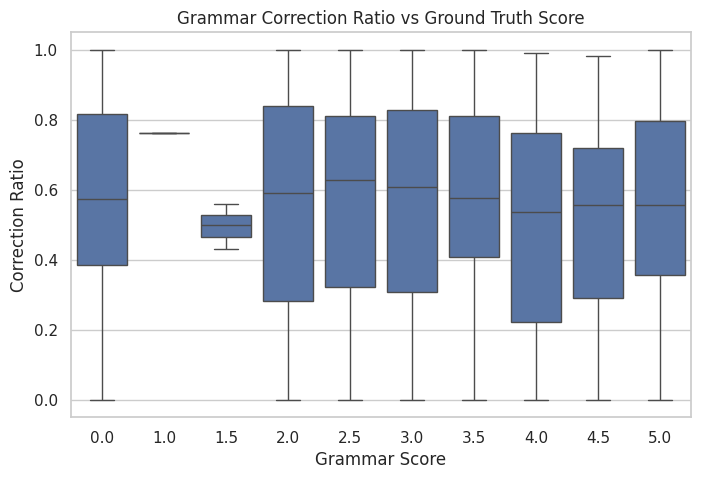

In [81]:
## visualizing correction ratio vs label
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=model_df,
    x="label",
    y="correction_ratio"
)

plt.xlabel("Grammar Score")
plt.ylabel("Correction Ratio")
plt.title("Grammar Correction Ratio vs Ground Truth Score")

plt.show()

## adding sentence transformers for meaningful sentence detection


In [82]:
!pip install -q sentence-transformers

In [83]:
## loading the model
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)
print("Embedding model loaded.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded.


In [84]:
## testing one transcript
sample_text = model_df.iloc[0]["transcript"]

sample_embedding = embedding_model.encode(
    sample_text
)

print("Embedding shape:", sample_embedding.shape)

Embedding shape: (384,)


In [85]:
## geneating embeddings for all the samples
transcripts = model_df["transcript"].tolist()

embeddings = embedding_model.encode(
    transcripts,
    batch_size=32,
    show_progress_bar=True
)

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

In [86]:
## checking the result of embedding transformer
print("Embedding matrix shape:", embeddings.shape)

Embedding matrix shape: (763, 384)


In [87]:
## saving the embeddings
EMBEDDING_PATH = "/kaggle/working/text_embeddings.npy"

np.save(
    EMBEDDING_PATH,
    embeddings
)

print(f"Saved embeddings to: {EMBEDDING_PATH}")

Saved embeddings to: /kaggle/working/text_embeddings.npy


In [88]:
loaded_embeddings = np.load(EMBEDDING_PATH)

print("Loaded shape:", loaded_embeddings.shape)

Loaded shape: (763, 384)


## adding audio features like pitch ,energy,pauses

In [89]:
model_df["duration"].describe()

count    763.000000
mean      55.747303
std        7.930823
min       20.060000
25%       53.544000
50%       60.074688
75%       60.074688
max       61.040000
Name: duration, dtype: float64

In [90]:
## calculating the high energy region
audio, sr = librosa.load(
    model_df.iloc[0]["audio_path"],
    sr=None
)

intervals = librosa.effects.split(
    audio,
    top_db=30
)

print(intervals[:10])

[[ 64000  72192]
 [111104 119808]
 [126464 129024]
 [130560 148480]
 [149504 158720]
 [175616 183808]
 [198656 217600]
 [221184 229376]
 [244736 255488]
 [284160 286720]]


In [91]:
## calculating speech duration
speech_duration = sum(
    end - start
    for start, end in intervals
) / sr

print("Speech duration:", speech_duration)
print("Total duration:", len(audio) / sr)

Speech duration: 35.168
Total duration: 60.508375


## Silence Ratio
### I am calculating this beacuse in 60s duration there may be only 30s for speech rest is jsut silence and nothing.
##    Therefore,
           Silence_Ratio=Total_Duration-Speech_Duration
                         ------------------------------
                                Total Duration

In [92]:
total_duration = len(audio) / sr

silence_ratio = (
    total_duration - speech_duration
) / total_duration

print("Silence ratio:", silence_ratio)

Silence ratio: 0.41879120039168133


## Speaking Rate
      WPM=       Number_of_Words
          ---------------------------
          Speech Duration in Minutes

In [93]:
word_count = len(
    model_df.iloc[0]["transcript"].split()
)

speech_minutes = speech_duration / 60

wpm = word_count / speech_minutes

print("Words:", word_count)
print("Speech duration:", speech_duration)
print("Speaking rate:", wpm)

Words: 91
Speech duration: 35.168
Speaking rate: 155.2547770700637


In [94]:
## function for audio_features
def extract_audio_features(path, transcript):
    audio, sr = librosa.load(
        path,
        sr=None
    )

    total_duration = len(audio) / sr

    intervals = librosa.effects.split(
        audio,
        top_db=30
    )

    speech_duration = sum(
        end - start
        for start, end in intervals
    ) / sr

    silence_duration = (
        total_duration - speech_duration
    )

    silence_ratio = (
        silence_duration / total_duration
        if total_duration > 0
        else 0
    )

    word_count = len(transcript.split())

    speech_minutes = speech_duration / 60

    words_per_minute = (
        word_count / speech_minutes
        if speech_minutes > 0
        else 0
    )

    return {
        "audio_duration": total_duration,
        "speech_duration": speech_duration,
        "silence_duration": silence_duration,
        "silence_ratio": silence_ratio,
        "words_per_minute": words_per_minute
    }

In [95]:
## testing the function on one file 
sample_audio_features = extract_audio_features(
    model_df.iloc[0]["audio_path"],
    model_df.iloc[0]["transcript"]
)

sample_audio_features

{'audio_duration': 60.508375,
 'speech_duration': np.float64(35.168),
 'silence_duration': np.float64(25.340375),
 'silence_ratio': np.float64(0.41879120039168133),
 'words_per_minute': np.float64(155.2547770700637)}

In [96]:
## extracting audio_features for all
from tqdm.auto import tqdm

tqdm.pandas()

audio_features = model_df.progress_apply(
    lambda row: extract_audio_features(
        row["audio_path"],
        row["transcript"]
    ),
    axis=1
)

  0%|          | 0/763 [00:00<?, ?it/s]

In [97]:
## adding audio_features to out data frame
audio_features_df = pd.DataFrame(
    audio_features.tolist(),
    index=model_df.index
)
model_df = pd.concat(
    [model_df, audio_features_df],
    axis=1
)

model_df[
    [
        "audio_duration",
        "speech_duration",
        "silence_duration",
        "silence_ratio",
        "words_per_minute"
    ]
].head()

,audio_duration,speech_duration,silence_duration,silence_ratio,words_per_minute
0,60.508375,35.168000,25.340375,0.418791,155.254777
1,60.074688,51.594687,8.480000,0.141158,134.897609
2,60.074688,45.344000,14.730688,0.245206,198.482710
3,45.060000,36.612000,8.448000,0.187483,162.241888
4,45.300000,31.828000,13.472000,0.297395,139.499811


In [98]:
## statical analysis 
audio_feature_columns = [
    "audio_duration",
    "speech_duration",
    "silence_duration",
    "silence_ratio",
    "words_per_minute"
]

model_df[audio_feature_columns].describe()

,audio_duration,speech_duration,silence_duration,silence_ratio,words_per_minute
count,763.000000,763.000000,763.000000,763.000000,763.000000
mean,55.747303,39.626795,16.120508,0.284027,155.239309
std,7.930823,9.147716,9.085527,0.151656,98.175895
min,20.060000,1.728000,0.000000,0.000000,3.994674
25%,53.544000,34.080000,10.638000,0.197088,130.613894
50%,60.074688,40.352000,16.160000,0.284624,153.587811
75%,60.074688,45.060000,20.960000,0.367666,172.018349
max,61.040000,61.034687,48.714750,0.961651,2708.333333


In [99]:
## correaltion of audio_features
model_df[
    audio_feature_columns + ["label"]
].corr()["label"].sort_values(ascending=False)

label               1.000000
silence_duration    0.178512
silence_ratio       0.173729
audio_duration      0.101835
words_per_minute    0.091270
speech_duration    -0.089010
Name: label, dtype: float64

In [100]:
FEATURE_DATA_PATH = "/kaggle/working/model_features.csv"

model_df.to_csv(
    FEATURE_DATA_PATH,
    index=False
)

print(f"Saved feature dataframe to: {FEATURE_DATA_PATH}")

Saved feature dataframe to: /kaggle/working/model_features.csv


# Feature Matrix


In [101]:
import pandas as pd
import numpy as np

print("Number of usable samples:", len(model_df))

print("\nScore distribution:")
print(model_df["label"].value_counts().sort_index())

print("\nScore statistics:")
print(model_df["label"].describe())

Number of usable samples: 763

Score distribution:
label
0.0     31
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64

Score statistics:
count    763.000000
mean       3.339450
std        1.208339
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [102]:
handcrafted_cols = [
    # Text statistics
    "word_count",
    "char_count",
    "sentence_count",
    "avg_sentence_length",
    "max_sentence_length",
    "vocabulary_diversity",
    "repetition_ratio",

    # POS features
    "pos_noun",
    "pos_verb",
    "pos_adj",
    "pos_adv",
    "pos_pron",
    "pos_det",
    "pos_adp",
    "pos_cconj",
    "pos_sconj",
    "pos_aux",

    # Grammar correction features
    "original_word_count",
    "corrected_word_count",
    "word_count_difference",
    "correction_ratio",

    # Audio / fluency features
    "audio_duration",
    "speech_duration",
    "silence_duration",
    "silence_ratio",
    "words_per_minute"
]

print("Number of handcrafted features:", len(handcrafted_cols))

missing_cols = [
    col for col in handcrafted_cols
    if col not in model_df.columns
]

print("Missing columns:", missing_cols)

Number of handcrafted features: 26
Missing columns: []


In [103]:
X_handcrafted = (
    model_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

print("Handcrafted feature matrix shape:", X_handcrafted.shape)

Handcrafted feature matrix shape: (763, 26)


In [104]:
X_text = np.asarray(embeddings, dtype=np.float32)

print("Text embedding shape:", X_text.shape)
print("Number of samples in model_df:", len(model_df))

Text embedding shape: (763, 384)
Number of samples in model_df: 763


In [105]:
assert X_text.shape[0] == len(model_df), (
    "Mismatch between embeddings and model_df samples"
)

print("Embedding alignment check: PASSED")

Embedding alignment check: PASSED


In [106]:
## combining all the features
X = np.hstack([
    X_handcrafted,
    X_text
])

y = model_df["label"].to_numpy(dtype=np.float32)

print("Final X shape:", X.shape)
print("Target y shape:", y.shape)

Final X shape: (763, 410)
Target y shape: (763,)


In [107]:
## checking for nan values
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("Target NaN values:", np.isnan(y).sum())
print("Target infinite values:", np.isinf(y).sum())

NaN values: 0
Infinite values: 0
Target NaN values: 0
Target infinite values: 0


In [108]:
## CREATING CROSS-VALIDATION
from sklearn.model_selection import KFold
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Number of folds:", kf.get_n_splits())

Number of folds: 5


In [109]:
## Verifying Folds
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):

    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Fold 1: Train = 610, Validation = 153
Fold 2: Train = 610, Validation = 153
Fold 3: Train = 610, Validation = 153
Fold 4: Train = 611, Validation = 152
Fold 5: Train = 611, Validation = 152


In [110]:
## building baseline models
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

In [111]:
def evaluate_model(model, X, y, kf):
    
    fold_rmse = []
    fold_pearson = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
        
        X_train = X[train_idx]
        X_val = X[val_idx]
        
        y_train = y[train_idx]
        y_val = y[val_idx]

        # Train
        model.fit(X_train, y_train)

        # Predict
        predictions = model.predict(X_val)

        # Keep predictions within valid grammar-score range
        predictions = np.clip(predictions, 1, 5)

        # RMSE
        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )

        # Pearson correlation
        if np.std(predictions) > 0:
            pearson = pearsonr(y_val, predictions)[0]
        else:
            pearson = 0.0

        fold_rmse.append(rmse)
        fold_pearson.append(pearson)

        print(
            f"Fold {fold}: "
            f"RMSE = {rmse:.4f}, "
            f"Pearson = {pearson:.4f}"
        )

    results = {
        "RMSE Mean": np.mean(fold_rmse),
        "RMSE Std": np.std(fold_rmse),
        "Pearson Mean": np.mean(fold_pearson),
        "Pearson Std": np.std(fold_pearson)
    }

    return results

In [112]:
class MeanBaseline:
    
    def fit(self, X, y):
        self.mean_ = np.mean(y)
        return self
    
    def predict(self, X):
        return np.full(len(X), self.mean_)

In [113]:
print("Mean Baseline Results")
print("=" * 40)

baseline_results = evaluate_model(
    MeanBaseline(),
    X,
    y,
    kf
)

baseline_results

Mean Baseline Results
Fold 1: RMSE = 1.1955, Pearson = nan
Fold 2: RMSE = 1.2457, Pearson = nan
Fold 3: RMSE = 1.2288, Pearson = nan
Fold 4: RMSE = 1.1885, Pearson = nan
Fold 5: RMSE = 1.1909, Pearson = 0.0000


/tmp/ipykernel_23/4169229835.py:30: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson = pearsonr(y_val, predictions)[0]
/tmp/ipykernel_23/4169229835.py:30: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson = pearsonr(y_val, predictions)[0]
/tmp/ipykernel_23/4169229835.py:30: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson = pearsonr(y_val, predictions)[0]
/tmp/ipykernel_23/4169229835.py:30: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson = pearsonr(y_val, predictions)[0]


{'RMSE Mean': np.float64(1.209885268022514),
 'RMSE Std': np.float64(0.023062763003068504),
 'Pearson Mean': np.float64(nan),
 'Pearson Std': np.float64(nan)}

In [114]:
## evaluating
ridge_handcrafted = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])
print("Ridge + Handcrafted Features")
print("=" * 40)

ridge_hand_results = evaluate_model(
    ridge_handcrafted,
    X_handcrafted,
    y,
    kf
)

ridge_hand_results

Ridge + Handcrafted Features
Fold 1: RMSE = 0.8740, Pearson = 0.6806
Fold 2: RMSE = 1.0017, Pearson = 0.6044
Fold 3: RMSE = 0.9750, Pearson = 0.6099
Fold 4: RMSE = 0.9036, Pearson = 0.6496
Fold 5: RMSE = 0.8858, Pearson = 0.6712


{'RMSE Mean': np.float64(0.9280575684920217),
 'RMSE Std': np.float64(0.0508595748304905),
 'Pearson Mean': np.float32(0.6431574),
 'Pearson Std': np.float32(0.031097567)}

In [115]:
## ridge with text embeddings
ridge_text = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])
## evaluate
print("Ridge + Text Embeddings")
print("=" * 40)

ridge_text_results = evaluate_model(
    ridge_text,
    X_text,
    y,
    kf
)

ridge_text_results



Ridge + Text Embeddings
Fold 1: RMSE = 1.0063, Pearson = 0.5826
Fold 2: RMSE = 1.1250, Pearson = 0.5340
Fold 3: RMSE = 1.1824, Pearson = 0.4631
Fold 4: RMSE = 1.0706, Pearson = 0.5382
Fold 5: RMSE = 1.1713, Pearson = 0.4634


{'RMSE Mean': np.float64(1.11112943699003),
 'RMSE Std': np.float64(0.06561944592899627),
 'Pearson Mean': np.float32(0.5162605),
 'Pearson Std': np.float32(0.046520144)}

In [116]:
## ridge on all features
ridge_all = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])
print("Ridge + All Features")
print("=" * 40)

ridge_all_results = evaluate_model(
    ridge_all,
    X,
    y,
    kf
)

ridge_all_results

Ridge + All Features
Fold 1: RMSE = 0.9792, Pearson = 0.6130
Fold 2: RMSE = 1.0258, Pearson = 0.6027
Fold 3: RMSE = 1.0691, Pearson = 0.5575
Fold 4: RMSE = 0.9875, Pearson = 0.6185
Fold 5: RMSE = 1.0586, Pearson = 0.5631


{'RMSE Mean': np.float64(1.0240496769611285),
 'RMSE Std': np.float64(0.03626439794667844),
 'Pearson Mean': np.float32(0.5909459),
 'Pearson Std': np.float32(0.02560982)}

In [117]:
## comparison table
results_table = pd.DataFrame({
    "Mean Baseline": baseline_results,
    "Ridge + Handcrafted": ridge_hand_results,
    "Ridge + Text": ridge_text_results,
    "Ridge + All": ridge_all_results
}).T

results_table

,RMSE Mean,RMSE Std,Pearson Mean,Pearson Std
Mean Baseline,1.209885,0.023063,NaN,NaN
Ridge + Handcrafted,0.928058,0.050860,0.643157,0.031098
Ridge + Text,1.111129,0.065619,0.516261,0.046520
Ridge + All,1.024050,0.036264,0.590946,0.025610


In [118]:
## identifying the best baseline
best_rmse_model = results_table["RMSE Mean"].idxmin()
best_pearson_model = results_table["Pearson Mean"].idxmax()

print("Best model by RMSE:", best_rmse_model)
print("Best model by Pearson:", best_pearson_model)

Best model by RMSE: Ridge + Handcrafted
Best model by Pearson: Ridge + Handcrafted


In [119]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [120]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print(xgb_model)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)


In [121]:
print("XGBoost + All Features")
print("=" * 40)

xgb_results = evaluate_model(
    xgb_model,
    X,
    y,
    kf
)

xgb_results

XGBoost + All Features
Fold 1: RMSE = 0.8631, Pearson = 0.6809
Fold 2: RMSE = 0.8685, Pearson = 0.7343
Fold 3: RMSE = 0.9376, Pearson = 0.6467
Fold 4: RMSE = 0.7902, Pearson = 0.7544
Fold 5: RMSE = 0.7196, Pearson = 0.8122


{'RMSE Mean': np.float64(0.8358084040744362),
 'RMSE Std': np.float64(0.07451633611339135),
 'Pearson Mean': np.float32(0.7257117),
 'Pearson Std': np.float32(0.057652015)}

In [122]:
results_table.loc["XGBoost + All"] = xgb_results

results_table

,RMSE Mean,RMSE Std,Pearson Mean,Pearson Std
Mean Baseline,1.209885,0.023063,NaN,NaN
Ridge + Handcrafted,0.928058,0.050860,0.643157,0.031098
Ridge + Text,1.111129,0.065619,0.516261,0.046520
Ridge + All,1.024050,0.036264,0.590946,0.025610
XGBoost + All,0.835808,0.074516,0.725712,0.057652


In [123]:
best_rmse_model = results_table["RMSE Mean"].idxmin()
best_pearson_model = results_table["Pearson Mean"].idxmax()

print("Best model by RMSE:", best_rmse_model)
print("Best model by Pearson:", best_pearson_model)

Best model by RMSE: XGBoost + All
Best model by Pearson: XGBoost + All


# Training the Model

In [124]:
xgb_model.fit(X, y)

train_predictions = xgb_model.predict(X)

train_predictions = np.clip(
    train_predictions,
    1,
    5
)

train_rmse = np.sqrt(
    mean_squared_error(y, train_predictions)
)

print(f"XGBoost Training RMSE: {train_rmse:.4f}")

XGBoost Training RMSE: 0.3051


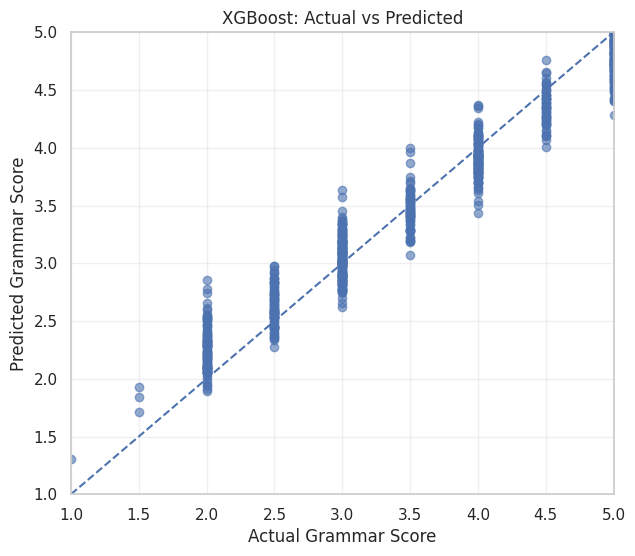

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    train_predictions,
    alpha=0.6
)

plt.plot(
    [1, 5],
    [1, 5],
    linestyle="--"
)

plt.xlabel("Actual Grammar Score")
plt.ylabel("Predicted Grammar Score")
plt.title("XGBoost: Actual vs Predicted")

plt.xlim(1, 5)
plt.ylim(1, 5)

plt.grid(alpha=0.3)
plt.show()

In [126]:
results_table.to_csv(
    "/kaggle/working/model_comparison.csv"
)

print("Saved:")
print("/kaggle/working/model_comparison.csv")

Saved:
/kaggle/working/model_comparison.csv


In [127]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np
import pandas as pd
import xgboost as xgb


def evaluate_xgb_params(params, X, y, kf):
    
    fold_rmse = []
    fold_pearson = []

    for train_idx, val_idx in kf.split(X):

        X_train = X[train_idx]
        X_val = X[val_idx]

        y_train = y[train_idx]
        y_val = y[val_idx]

        model = xgb.XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
            **params
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        # Keep predictions inside valid score range
        predictions = np.clip(predictions, 1, 5)

        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )

        if np.std(predictions) > 0:
            pearson = pearsonr(y_val, predictions)[0]
        else:
            pearson = 0.0

        fold_rmse.append(rmse)
        fold_pearson.append(pearson)

    return {
        "RMSE Mean": np.mean(fold_rmse),
        "RMSE Std": np.std(fold_rmse),
        "Pearson Mean": np.mean(fold_pearson),
        "Pearson Std": np.std(fold_pearson)
    }

In [128]:
param_grid = [
    {
        "n_estimators": 300,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0
    },
    {
        "n_estimators": 700,
        "learning_rate": 0.02,
        "max_depth": 3,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 2.0
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_child_weight": 10,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.5,
        "reg_lambda": 5.0
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 10,
        "subsample": 0.9,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.5,
        "reg_lambda": 5.0
    }
]

print("Number of configurations:", len(param_grid))

Number of configurations: 6


In [129]:
tuning_results = []

for i, params in enumerate(param_grid, start=1):

    print(f"\nConfiguration {i}/{len(param_grid)}")
    print(params)

    result = evaluate_xgb_params(
        params,
        X,
        y,
        kf
    )

    result["config_id"] = i
    result["parameters"] = str(params)

    tuning_results.append(result)

    print(
        f"RMSE: {result['RMSE Mean']:.4f} | "
        f"Pearson: {result['Pearson Mean']:.4f}"
    )


Configuration 1/6
{'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 2.0}
RMSE: 0.8529 | Pearson: 0.7193

Configuration 2/6
{'n_estimators': 500, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 2.0}
RMSE: 0.8445 | Pearson: 0.7206

Configuration 3/6
{'n_estimators': 500, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 2.0}
RMSE: 0.8358 | Pearson: 0.7257

Configuration 4/6
{'n_estimators': 700, 'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 2.0}
RMSE: 0.8338 | Pearson: 0.7286

Configuration 5/6
{'n_estimators': 500, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 10, 'subsample': 0.8, 'colsample_bytree': 0.

In [130]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df[
    [
        "config_id",
        "RMSE Mean",
        "RMSE Std",
        "Pearson Mean",
        "Pearson Std",
        "parameters"
    ]
]

tuning_df.sort_values(
    "RMSE Mean",
    ascending=True
)

,config_id,RMSE Mean,RMSE Std,Pearson Mean,Pearson Std,parameters
3,4,0.833774,0.069991,0.728635,0.055128,"{'n_estimators': 700, 'learning_rate': 0.02, '..."
2,3,0.835808,0.074516,0.725712,0.057652,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
4,5,0.837002,0.073991,0.724624,0.057693,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
1,2,0.844546,0.065954,0.720615,0.050380,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
5,6,0.848654,0.073845,0.716866,0.060760,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
0,1,0.852882,0.066114,0.719337,0.053737,"{'n_estimators': 300, 'learning_rate': 0.03, '..."


In [131]:
best_rmse_idx = tuning_df["RMSE Mean"].idxmin()

best_rmse_result = tuning_df.loc[best_rmse_idx]

print("Best configuration by RMSE:")
print(best_rmse_result)

Best configuration by RMSE:
config_id                                                       4
RMSE Mean                                                0.833774
RMSE Std                                                 0.069991
Pearson Mean                                             0.728635
Pearson Std                                              0.055128
parameters      {'n_estimators': 700, 'learning_rate': 0.02, '...
Name: 3, dtype: object


In [132]:
best_pearson_idx = tuning_df["Pearson Mean"].idxmax()

best_pearson_result = tuning_df.loc[best_pearson_idx]

print("Best configuration by Pearson:")
print(best_pearson_result)

Best configuration by Pearson:
config_id                                                       4
RMSE Mean                                                0.833774
RMSE Std                                                 0.069991
Pearson Mean                                             0.728635
Pearson Std                                              0.055128
parameters      {'n_estimators': 700, 'learning_rate': 0.02, '...
Name: 3, dtype: object


In [133]:
best_rmse_config_id = int(
    best_rmse_result["config_id"]
)

best_params = param_grid[
    best_rmse_config_id - 1
]

print("Selected parameters:")
print(best_params)

Selected parameters:
{'n_estimators': 700, 'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 2.0}


In [134]:
best_xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **best_params
)

print(best_xgb_model)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.02, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=700,
             n_jobs=-1, num_parallel_tree=None, ...)


In [135]:
## calculating traininh rmse
best_xgb_model.fit(X, y)

train_predictions = best_xgb_model.predict(X)

train_predictions = np.clip(
    train_predictions,
    1,
    5
)

training_rmse = np.sqrt(
    mean_squared_error(y, train_predictions)
)

training_pearson = pearsonr(
    y,
    train_predictions
)[0]

print(f"Training RMSE: {training_rmse:.4f}")
print(f"Training Pearson: {training_pearson:.4f}")

Training RMSE: 0.3179
Training Pearson: 0.9803


In [136]:
tuning_df.to_csv(
    "/kaggle/working/xgboost_tuning_results.csv",
    index=False
)

print("Tuning results saved successfully.")

Tuning results saved successfully.


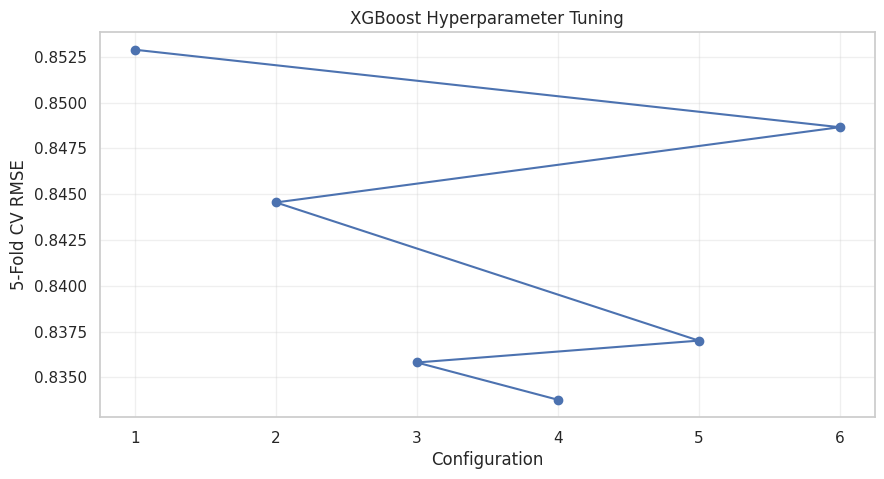

In [137]:
##plotting rmse reuslts
import matplotlib.pyplot as plt

plot_df = tuning_df.sort_values("RMSE Mean")

plt.figure(figsize=(10, 5))

plt.plot(
    plot_df["config_id"],
    plot_df["RMSE Mean"],
    marker="o"
)

plt.xlabel("Configuration")
plt.ylabel("5-Fold CV RMSE")
plt.title("XGBoost Hyperparameter Tuning")

plt.grid(alpha=0.3)
plt.show()

In [138]:
## comapring tunded xgboost with previous models
tuned_xgb_results = {
    "RMSE Mean": best_rmse_result["RMSE Mean"],
    "RMSE Std": best_rmse_result["RMSE Std"],
    "Pearson Mean": best_rmse_result["Pearson Mean"],
    "Pearson Std": best_rmse_result["Pearson Std"]
}

results_table.loc["Tuned XGBoost + All"] = tuned_xgb_results

results_table.sort_values(
    "RMSE Mean",
    ascending=True
)

,RMSE Mean,RMSE Std,Pearson Mean,Pearson Std
Tuned XGBoost + All,0.833774,0.069991,0.728635,0.055128
XGBoost + All,0.835808,0.074516,0.725712,0.057652
Ridge + Handcrafted,0.928058,0.050860,0.643157,0.031098
Ridge + All,1.024050,0.036264,0.590946,0.025610
Ridge + Text,1.111129,0.065619,0.516261,0.046520
Mean Baseline,1.209885,0.023063,NaN,NaN


In [139]:
from sklearn.base import clone

oof_ridge = np.zeros(len(y))
oof_xgb = np.zeros(len(y))

for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):

    print(f"Processing Fold {fold}...")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    # -------------------------
    # Ridge
    # -------------------------
    ridge_model = clone(ridge_all)

    ridge_model.fit(
        X_train,
        y_train
    )

    ridge_pred = ridge_model.predict(X_val)

    ridge_pred = np.clip(
        ridge_pred,
        1,
        5
    )

    oof_ridge[val_idx] = ridge_pred

    # -------------------------
    # XGBoost
    # -------------------------
    xgb_fold_model = xgb.XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        **best_params
    )

    xgb_fold_model.fit(
        X_train,
        y_train
    )

    xgb_pred = xgb_fold_model.predict(X_val)

    xgb_pred = np.clip(
        xgb_pred,
        1,
        5
    )

    oof_xgb[val_idx] = xgb_pred

print("\nOOF prediction generation completed.")

Processing Fold 1...
Processing Fold 2...
Processing Fold 3...
Processing Fold 4...
Processing Fold 5...

OOF prediction generation completed.


In [140]:
print("Ridge OOF shape:", oof_ridge.shape)
print("XGBoost OOF shape:", oof_xgb.shape)

print("Ridge NaNs:", np.isnan(oof_ridge).sum())
print("XGBoost NaNs:", np.isnan(oof_xgb).sum())

Ridge OOF shape: (763,)
XGBoost OOF shape: (763,)
Ridge NaNs: 0
XGBoost NaNs: 0


In [141]:
ridge_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_ridge)
)

ridge_oof_pearson = pearsonr(
    y,
    oof_ridge
)[0]

xgb_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_xgb)
)

xgb_oof_pearson = pearsonr(
    y,
    oof_xgb
)[0]

print("Ridge OOF")
print(f"RMSE: {ridge_oof_rmse:.4f}")
print(f"Pearson: {ridge_oof_pearson:.4f}")

print("\nXGBoost OOF")
print(f"RMSE: {xgb_oof_rmse:.4f}")
print(f"Pearson: {xgb_oof_pearson:.4f}")

Ridge OOF
RMSE: 1.0247
Pearson: 0.5935

XGBoost OOF
RMSE: 0.8369
Pearson: 0.7259


In [142]:
blend_results = []

weights = np.arange(
    0.0,
    1.01,
    0.05
)

for xgb_weight in weights:

    ridge_weight = 1 - xgb_weight

    blended_pred = (
        xgb_weight * oof_xgb
        + ridge_weight * oof_ridge
    )

    blended_pred = np.clip(
        blended_pred,
        1,
        5
    )

    rmse = np.sqrt(
        mean_squared_error(y, blended_pred)
    )

    pearson = pearsonr(
        y,
        blended_pred
    )[0]

    blend_results.append({
        "XGB Weight": xgb_weight,
        "Ridge Weight": ridge_weight,
        "RMSE": rmse,
        "Pearson": pearson
    })

blend_df = pd.DataFrame(blend_results)

blend_df

,XGB Weight,Ridge Weight,RMSE,Pearson
0,0.00,1.00,1.024694,0.593526
1,0.05,0.95,1.002512,0.605466
2,0.10,0.90,0.981303,0.617498
3,0.15,0.85,0.961132,0.629557
4,0.20,0.80,0.942065,0.641568
5,0.25,0.75,0.924171,0.653441
6,0.30,0.70,0.907520,0.665073
7,0.35,0.65,0.892180,0.676346
8,0.40,0.60,0.878220,0.687130
9,0.45,0.55,0.865708,0.697283


In [143]:
best_blend_rmse_idx = blend_df["RMSE"].idxmin()

best_blend_rmse = blend_df.loc[
    best_blend_rmse_idx
]

print("Best blend by RMSE:")
print(best_blend_rmse)

Best blend by RMSE:
XGB Weight      0.800000
Ridge Weight    0.200000
RMSE            0.823242
Pearson         0.737662
Name: 16, dtype: float64


In [144]:
best_blend_pearson_idx = blend_df["Pearson"].idxmax()

best_blend_pearson = blend_df.loc[
    best_blend_pearson_idx
]

print("Best blend by Pearson:")
print(best_blend_pearson)

Best blend by Pearson:
XGB Weight      0.800000
Ridge Weight    0.200000
RMSE            0.823242
Pearson         0.737662
Name: 16, dtype: float64


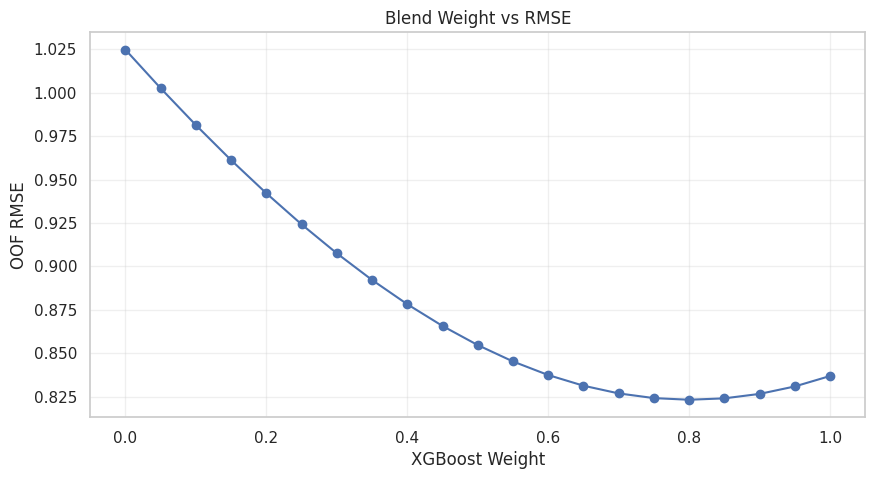

In [145]:
## visualizing blending performance
plt.figure(figsize=(10, 5))

plt.plot(
    blend_df["XGB Weight"],
    blend_df["RMSE"],
    marker="o"
)

plt.xlabel("XGBoost Weight")
plt.ylabel("OOF RMSE")
plt.title("Blend Weight vs RMSE")

plt.grid(alpha=0.3)
plt.show()

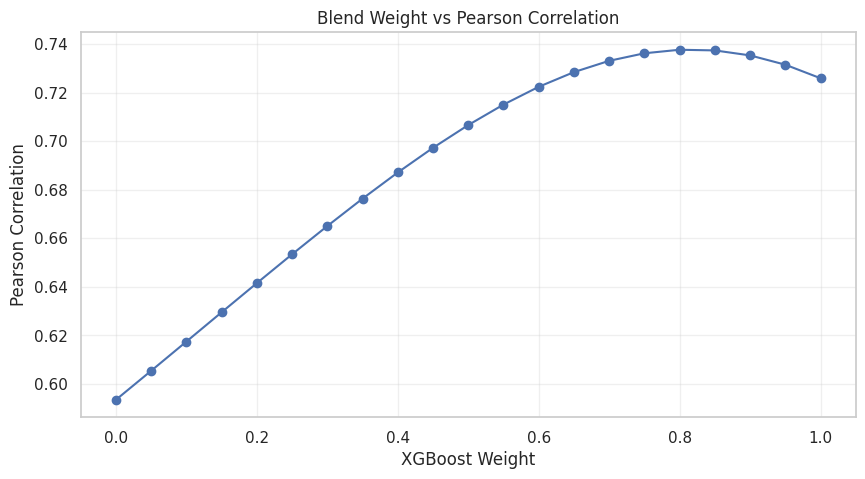

In [146]:
##
plt.figure(figsize=(10, 5))

plt.plot(
    blend_df["XGB Weight"],
    blend_df["Pearson"],
    marker="o"
)

plt.xlabel("XGBoost Weight")
plt.ylabel("Pearson Correlation")
plt.title("Blend Weight vs Pearson Correlation")

plt.grid(alpha=0.3)
plt.show()

In [147]:
best_xgb_weight = best_blend_rmse["XGB Weight"]
best_ridge_weight = best_blend_rmse["Ridge Weight"]

print(f"Selected XGBoost weight: {best_xgb_weight:.2f}")
print(f"Selected Ridge weight: {best_ridge_weight:.2f}")

Selected XGBoost weight: 0.80
Selected Ridge weight: 0.20


In [148]:
final_oof_prediction = (
    best_xgb_weight * oof_xgb
    + best_ridge_weight * oof_ridge
)

final_oof_prediction = np.clip(
    final_oof_prediction,
    1,
    5
)

final_oof_rmse = np.sqrt(
    mean_squared_error(
        y,
        final_oof_prediction
    )
)

final_oof_pearson = pearsonr(
    y,
    final_oof_prediction
)[0]

print("Final OOF Ensemble")
print("=" * 30)
print(f"RMSE: {final_oof_rmse:.4f}")
print(f"Pearson: {final_oof_pearson:.4f}")

Final OOF Ensemble
RMSE: 0.8232
Pearson: 0.7377


In [149]:
final_comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Ridge + Handcrafted",
        "Ridge + Text",
        "Ridge + All",
        "Tuned XGBoost + All",
        "Ridge + XGBoost Ensemble"
    ],
    "RMSE": [
        baseline_results["RMSE Mean"],
        ridge_hand_results["RMSE Mean"],
        ridge_text_results["RMSE Mean"],
        ridge_all_results["RMSE Mean"],
        tuned_xgb_results["RMSE Mean"],
        final_oof_rmse
    ],
    "Pearson": [
        baseline_results["Pearson Mean"],
        ridge_hand_results["Pearson Mean"],
        ridge_text_results["Pearson Mean"],
        ridge_all_results["Pearson Mean"],
        tuned_xgb_results["Pearson Mean"],
        final_oof_pearson
    ]
})

final_comparison.sort_values(
    "RMSE",
    ascending=True
)

,Model,RMSE,Pearson
5,Ridge + XGBoost Ensemble,0.823242,0.737662
4,Tuned XGBoost + All,0.833774,0.728635
1,Ridge + Handcrafted,0.928058,0.643157
3,Ridge + All,1.024050,0.590946
2,Ridge + Text,1.111129,0.516261
0,Mean Baseline,1.209885,NaN


In [150]:
print("Training samples:", len(model_df))
print("Test samples:", len(test_df))

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nFirst 5 test rows:")
display(test_df.head())

Training samples: 763
Test samples: 216

Test columns:
['filename', 'label']

First 5 test rows:


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


In [151]:
from pathlib import Path

# Define test_audio_dir directly
test_audio_dir = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test")

test_df["audio_path"] = test_df["filename"].apply(
    lambda x: test_audio_dir / x
)

print("Test audio directory:", test_audio_dir)

print(
    "Missing test audio files:",
    (~test_df["audio_path"].apply(lambda x: x.exists())).sum()
)

Test audio directory: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test
Missing test audio files: 0


In [152]:
from tqdm.auto import tqdm

tqdm.pandas()

test_df["transcript"] = test_df["audio_path"].progress_apply(
    lambda path: model.transcribe(
        str(path)
    )["text"].strip()
)

print("Test transcription completed.")

  0%|          | 0/216 [00:00<?, ?it/s]

Test transcription completed.


In [153]:
empty_test_transcripts = (
    test_df["transcript"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("Empty test transcripts:", empty_test_transcripts)

Empty test transcripts: 0


In [154]:
test_df["word_count"] = (
    test_df["transcript"]
    .fillna("")
    .str.split()
    .str.len()
)

test_df["char_count"] = (
    test_df["transcript"]
    .fillna("")
    .str.len()
)

In [155]:
def extract_text_features(text):
    
    sentences = sent_tokenize(text) if text.strip() else []
    
    words = text.split()
    
    sentence_count = len(sentences)
    
    sentence_lengths = [
        len(sentence.split())
        for sentence in sentences
    ]
    
    avg_sentence_length = (
        np.mean(sentence_lengths)
        if sentence_lengths
        else 0
    )
    
    max_sentence_length = (
        max(sentence_lengths)
        if sentence_lengths
        else 0
    )
    
    unique_words = len(
        set(word.lower() for word in words)
    )
    
    total_words = len(words)
    
    vocabulary_diversity = (
        unique_words / total_words
        if total_words > 0
        else 0
    )
    
    repetition_ratio = (
        1 - vocabulary_diversity
        if total_words > 0
        else 0
    )
    
    return {
        "sentence_count": sentence_count,
        "avg_sentence_length": avg_sentence_length,
        "max_sentence_length": max_sentence_length,
        "vocabulary_diversity": vocabulary_diversity,
        "repetition_ratio": repetition_ratio
    }

In [156]:
def extract_syntax_features(text):
    
    doc = nlp(text)
    
    conjunction_count = sum(
        token.pos_ in ["CCONJ", "SCONJ"]
        for token in doc
    )
    
    auxiliary_count = sum(
        token.pos_ == "AUX"
        for token in doc
    )
    
    return {
        "conjunction_count": conjunction_count,
        "auxiliary_count": auxiliary_count
    }

In [157]:
test_syntax_features = test_df["transcript"].progress_apply(
    extract_syntax_features
)

test_syntax_features_df = pd.DataFrame(
    test_syntax_features.tolist(),
    index=test_df.index
)

test_df = pd.concat(
    [test_df, test_syntax_features_df],
    axis=1
)

  0%|          | 0/216 [00:00<?, ?it/s]

In [158]:
test_grammar_features = test_df["transcript"].progress_apply(
    get_grammar_features
)

test_grammar_features_df = pd.DataFrame(
    test_grammar_features.tolist(),
    index=test_df.index
)

test_df = pd.concat(
    [test_df, test_grammar_features_df],
    axis=1
)

  0%|          | 0/216 [00:00<?, ?it/s]

In [159]:
test_transcripts = (
    test_df["transcript"]
    .fillna("")
    .tolist()
)

test_embeddings = embedding_model.encode(
    test_transcripts,
    batch_size=32,
    show_progress_bar=True
)

X_test_text = np.asarray(
    test_embeddings,
    dtype=np.float32
)

print("Test embedding shape:", X_test_text.shape)

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Test embedding shape: (216, 384)


In [160]:
assert X_test_text.shape == (len(test_df), 384)

print("Test embedding alignment: PASSED")

Test embedding alignment: PASSED


In [161]:
test_audio_features = []

for _, row in tqdm(
    test_df.iterrows(),
    total=len(test_df)
):
    
    features = extract_audio_features(
        row["audio_path"],
        row["transcript"]
    )
    
    test_audio_features.append(features)

test_audio_features_df = pd.DataFrame(
    test_audio_features,
    index=test_df.index
)

test_df = pd.concat(
    [test_df, test_audio_features_df],
    axis=1
)

  0%|          | 0/216 [00:00<?, ?it/s]

In [162]:
print(
    test_audio_features_df[
        [
            "audio_duration",
            "speech_duration",
            "silence_duration",
            "silence_ratio",
            "words_per_minute"
        ]
    ].head()
)

   audio_duration  speech_duration  silence_duration  silence_ratio  \
0       45.060000           30.880         14.180000       0.314692   
1       44.969313           30.144         14.825313       0.329676   
2       45.012000           35.104          9.908000       0.220119   
3       58.980000           36.800         22.180000       0.376060   
4       45.040000           44.624          0.416000       0.009236   

   words_per_minute  
0        184.585492  
1        135.350318  
2        174.339107  
3         86.413043  
4        114.288275  


In [163]:
# Generate missing sentence-level text features

test_text_features = test_df["transcript"].fillna("").progress_apply(
    extract_text_features
)

test_text_features_df = pd.DataFrame(
    test_text_features.tolist(),
    index=test_df.index
)

test_df = pd.concat(
    [test_df, test_text_features_df],
    axis=1
)

print("Text-level features added.")
print(
    test_df[
        [
            "sentence_count",
            "avg_sentence_length",
            "max_sentence_length",
            "vocabulary_diversity",
            "repetition_ratio"
        ]
    ].head()
)

  0%|          | 0/216 [00:00<?, ?it/s]

Text-level features added.
   sentence_count  avg_sentence_length  max_sentence_length  \
0               4            23.750000                   36   
1               4            17.000000                   29   
2               7            14.571429                   25   
3               3            17.666667                   20   
4               1            85.000000                   85   

   vocabulary_diversity  repetition_ratio  
0              0.557895          0.442105  
1              0.838235          0.161765  
2              0.715686          0.284314  
3              0.773585          0.226415  
4              0.611765          0.388235  


In [164]:
# Generate POS features for test data

test_pos_features = test_df["transcript"].fillna("").progress_apply(
    extract_pos_features
)

test_pos_features_df = pd.DataFrame(
    test_pos_features.tolist(),
    index=test_df.index
)

test_df = pd.concat(
    [test_df, test_pos_features_df],
    axis=1
)

print("POS features added.")

  0%|          | 0/216 [00:00<?, ?it/s]

POS features added.


In [165]:
## test matrix
missing_test_cols = [
    col
    for col in handcrafted_cols
    if col not in test_df.columns
]

print("Missing test feature columns:")
print(missing_test_cols)

Missing test feature columns:
[]


In [166]:
X_test_handcrafted = (
    test_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

print(
    "Test handcrafted matrix shape:",
    X_test_handcrafted.shape
)

Test handcrafted matrix shape: (216, 26)


In [167]:
X_test = np.hstack([
    X_test_handcrafted,
    X_test_text
])

print("Final test feature shape:", X_test.shape)
print("Training feature shape:", X.shape)

Final test feature shape: (216, 410)
Training feature shape: (763, 410)


In [168]:
print("model_df samples:", len(model_df))

print("Current handcrafted feature count:", len(handcrafted_cols))

print("Training embeddings shape:", np.asarray(embeddings).shape)

print("Test handcrafted shape:", X_test_handcrafted.shape)

print("Test embeddings shape:", X_test_text.shape)

print("Old training X shape:", X.shape)

model_df samples: 763
Current handcrafted feature count: 26
Training embeddings shape: (763, 384)
Test handcrafted shape: (216, 26)
Test embeddings shape: (216, 384)
Old training X shape: (763, 410)


In [169]:
# Rebuild training handcrafted features

X_handcrafted = (
    model_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

# Rebuild training text feature matrix
X_text = np.asarray(
    embeddings,
    dtype=np.float32
)

# Combine
X = np.hstack([
    X_handcrafted,
    X_text
])

# Target
y = model_df["label"].to_numpy(dtype=np.float32)

print("Rebuilt training handcrafted shape:", X_handcrafted.shape)
print("Training text embedding shape:", X_text.shape)
print("Final training X shape:", X.shape)
print("Training y shape:", y.shape)

Rebuilt training handcrafted shape: (763, 26)
Training text embedding shape: (763, 384)
Final training X shape: (763, 410)
Training y shape: (763,)


In [170]:
missing_test_cols = [
    col
    for col in handcrafted_cols
    if col not in test_df.columns
]

print("Training handcrafted features:", len(handcrafted_cols))
print("Test handcrafted features:", len([
    col for col in handcrafted_cols
    if col in test_df.columns
]))

print("\nMissing test features:")
for col in missing_test_cols:
    print("-", col)

Training handcrafted features: 26
Test handcrafted features: 26

Missing test features:


In [171]:
missing_test_cols = [
    col
    for col in handcrafted_cols
    if col not in test_df.columns
]

print("Missing test features:")
print(missing_test_cols)

Missing test features:
[]


In [172]:
# ==========================================
# REBUILD FINAL TRAINING FEATURE MATRIX
# ==========================================

# Training handcrafted features
X_handcrafted = (
    model_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

# Training text embeddings
X_text = np.asarray(
    embeddings,
    dtype=np.float32
)

# Combine handcrafted + embeddings
X = np.hstack([
    X_handcrafted,
    X_text
])

# Target
y = model_df["label"].to_numpy(dtype=np.float32)

print("Training handcrafted:", X_handcrafted.shape)
print("Training embeddings:", X_text.shape)
print("Final training X:", X.shape)
print("Training y:", y.shape)

Training handcrafted: (763, 26)
Training embeddings: (763, 384)
Final training X: (763, 410)
Training y: (763,)


In [173]:
# ==========================================
# REBUILD FINAL TEST FEATURE MATRIX
# ==========================================

# Build test handcrafted features again
X_test_handcrafted = (
    test_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

print("Test handcrafted shape:", X_test_handcrafted.shape)

# Combine handcrafted features + text embeddings
X_test = np.hstack([
    X_test_handcrafted,
    X_test_text
])

print("Final test X shape:", X_test.shape)

Test handcrafted shape: (216, 26)
Final test X shape: (216, 410)


In [174]:
# ==========================================
# FIND THE 5 EXTRA TRAINING FEATURES
# ==========================================

numeric_train_cols = model_df.select_dtypes(
    include=np.number
).columns.tolist()

# Remove target column
numeric_feature_cols = [
    col for col in numeric_train_cols
    if col != "score"
]

print("Total numeric feature columns in model_df:")
print(len(numeric_feature_cols))

print("\nCurrent handcrafted_cols:")
print(len(handcrafted_cols))
print(handcrafted_cols)

print("\nNumeric columns NOT in handcrafted_cols:")
extra_features = [
    col
    for col in numeric_feature_cols
    if col not in handcrafted_cols
]

print(extra_features)
print("\nNumber of extra features:", len(extra_features))

Total numeric feature columns in model_df:
30

Current handcrafted_cols:
26
['word_count', 'char_count', 'sentence_count', 'avg_sentence_length', 'max_sentence_length', 'vocabulary_diversity', 'repetition_ratio', 'pos_noun', 'pos_verb', 'pos_adj', 'pos_adv', 'pos_pron', 'pos_det', 'pos_adp', 'pos_cconj', 'pos_sconj', 'pos_aux', 'original_word_count', 'corrected_word_count', 'word_count_difference', 'correction_ratio', 'audio_duration', 'speech_duration', 'silence_duration', 'silence_ratio', 'words_per_minute']

Numeric columns NOT in handcrafted_cols:
['label', 'duration', 'conjunction_count', 'auxiliary_count']

Number of extra features: 4


In [175]:
# ==========================================
# FINAL HANDCRAFTED FEATURE LIST
# ==========================================

handcrafted_cols = [
    # Text statistics
    "word_count",
    "char_count",
    "sentence_count",
    "avg_sentence_length",
    "max_sentence_length",
    "vocabulary_diversity",
    "repetition_ratio",

    # POS features
    "pos_noun",
    "pos_verb",
    "pos_adj",
    "pos_adv",
    "pos_pron",
    "pos_det",
    "pos_adp",
    "pos_cconj",
    "pos_sconj",
    "pos_aux",

    # Grammar correction features
    "original_word_count",
    "corrected_word_count",
    "word_count_difference",
    "correction_ratio",

    # Audio / fluency features
    "audio_duration",
    "speech_duration",
    "silence_duration",
    "silence_ratio",
    "words_per_minute"
]

print("Number of handcrafted features:", len(handcrafted_cols))

Number of handcrafted features: 26


In [176]:
# Check feature availability

missing_train = [
    col for col in handcrafted_cols
    if col not in model_df.columns
]

missing_test = [
    col for col in handcrafted_cols
    if col not in test_df.columns
]

print("Missing training features:", missing_train)
print("Missing test features:", missing_test)

Missing training features: []
Missing test features: []


In [177]:
# ==========================================
# BUILD TRAINING MATRIX
# ==========================================

X_handcrafted = (
    model_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

X_text = np.asarray(
    embeddings,
    dtype=np.float32
)

X = np.hstack([
    X_handcrafted,
    X_text
])

y = model_df["label"].to_numpy(dtype=np.float32)

print("Training handcrafted:", X_handcrafted.shape)
print("Training embeddings:", X_text.shape)
print("Final training X:", X.shape)
print("Training y:", y.shape)

Training handcrafted: (763, 26)
Training embeddings: (763, 384)
Final training X: (763, 410)
Training y: (763,)


In [178]:
# ==========================================
# BUILD TEST MATRIX
# ==========================================

X_test_handcrafted = (
    test_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

X_test_text = np.asarray(
    test_embeddings,
    dtype=np.float32
)

X_test = np.hstack([
    X_test_handcrafted,
    X_test_text
])

print("Test handcrafted:", X_test_handcrafted.shape)
print("Test embeddings:", X_test_text.shape)
print("Final test X:", X_test.shape)

Test handcrafted: (216, 26)
Test embeddings: (216, 384)
Final test X: (216, 410)


In [179]:
# ==========================================
# CHECK DUPLICATE COLUMN NAMES
# ==========================================

duplicate_cols = model_df.columns[
    model_df.columns.duplicated(keep=False)
].tolist()

print("Duplicate columns in model_df:")
print(duplicate_cols)

print("\nNumber of duplicate column occurrences:")
print(len(duplicate_cols))

Duplicate columns in model_df:
[]

Number of duplicate column occurrences:
0


In [180]:
duplicate_test_cols = test_df.columns[
    test_df.columns.duplicated(keep=False)
].tolist()

print("\nDuplicate columns in test_df:")
print(duplicate_test_cols)


Duplicate columns in test_df:
[]


In [181]:
# ==========================================
# REMOVE DUPLICATE COLUMNS FROM TRAINING DATA
# ==========================================

print("Before removing duplicates:")
print("model_df shape:", model_df.shape)

duplicate_cols = model_df.columns[
    model_df.columns.duplicated()
].tolist()

print("Duplicate column names:", duplicate_cols)

# Keep only the first occurrence of each column
model_df = model_df.loc[
    :,
    ~model_df.columns.duplicated()
].copy()

print("\nAfter removing duplicates:")
print("model_df shape:", model_df.shape)

print("\nRemaining duplicate columns:")
print(
    model_df.columns[
        model_df.columns.duplicated()
    ].tolist()
)

Before removing duplicates:
model_df shape: (763, 34)
Duplicate column names: []

After removing duplicates:
model_df shape: (763, 34)

Remaining duplicate columns:
[]


In [182]:
print("Number of handcrafted features:", len(handcrafted_cols))

missing_train = [
    col
    for col in handcrafted_cols
    if col not in model_df.columns
]

missing_test = [
    col
    for col in handcrafted_cols
    if col not in test_df.columns
]

print("Missing training features:", missing_train)
print("Missing test features:", missing_test)

Number of handcrafted features: 26
Missing training features: []
Missing test features: []


In [183]:
# ==========================================
# REBUILD TRAINING MATRIX
# ==========================================

X_handcrafted = (
    model_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

X_text = np.asarray(
    embeddings,
    dtype=np.float32
)

X = np.hstack([
    X_handcrafted,
    X_text
])

y = model_df["label"].to_numpy(dtype=np.float32)


# ==========================================
# REBUILD TEST MATRIX
# ==========================================

X_test_handcrafted = (
    test_df[handcrafted_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

X_test_text = np.asarray(
    test_embeddings,
    dtype=np.float32
)

X_test = np.hstack([
    X_test_handcrafted,
    X_test_text
])


# ==========================================
# PRINT FINAL SHAPES
# ==========================================

print("Training handcrafted:", X_handcrafted.shape)
print("Training embeddings :", X_text.shape)
print("Training X          :", X.shape)

print()

print("Test handcrafted    :", X_test_handcrafted.shape)
print("Test embeddings     :", X_test_text.shape)
print("Test X              :", X_test.shape)

print()

print("Target y            :", y.shape)

Training handcrafted: (763, 26)
Training embeddings : (763, 384)
Training X          : (763, 410)

Test handcrafted    : (216, 26)
Test embeddings     : (216, 384)
Test X              : (216, 410)

Target y            : (763,)


In [184]:
assert X.shape == (len(model_df), 410)
assert X_test.shape == (len(test_df), 410)

assert X.shape[1] == X_test.shape[1]

print("================================")
print("FEATURE PIPELINE CHECK: PASSED")
print("================================")
print("Training X:", X.shape)
print("Test X    :", X_test.shape)

FEATURE PIPELINE CHECK: PASSED
Training X: (763, 410)
Test X    : (216, 410)


In [185]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold cross-validation ready.")

5-fold cross-validation ready.


In [186]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_all = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

ridge_all_results = evaluate_model(
    ridge_all,
    X,
    y,
    kf
)

print("\nCorrected Ridge Results:")
print(ridge_all_results)

Fold 1: RMSE = 0.9792, Pearson = 0.6130
Fold 2: RMSE = 1.0258, Pearson = 0.6027
Fold 3: RMSE = 1.0691, Pearson = 0.5575
Fold 4: RMSE = 0.9875, Pearson = 0.6185
Fold 5: RMSE = 1.0586, Pearson = 0.5631

Corrected Ridge Results:
{'RMSE Mean': np.float64(1.0240496769611285), 'RMSE Std': np.float64(0.03626439794667844), 'Pearson Mean': np.float32(0.5909459), 'Pearson Std': np.float32(0.02560982)}


In [187]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_results = evaluate_model(
    xgb_model,
    X,
    y,
    kf
)

print("\nCorrected XGBoost Results:")
print(xgb_results)

Fold 1: RMSE = 0.8631, Pearson = 0.6809
Fold 2: RMSE = 0.8685, Pearson = 0.7343
Fold 3: RMSE = 0.9376, Pearson = 0.6467
Fold 4: RMSE = 0.7902, Pearson = 0.7544
Fold 5: RMSE = 0.7196, Pearson = 0.8122

Corrected XGBoost Results:
{'RMSE Mean': np.float64(0.8358084040744362), 'RMSE Std': np.float64(0.07451633611339135), 'Pearson Mean': np.float32(0.7257117), 'Pearson Std': np.float32(0.057652015)}


In [188]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_results = evaluate_model(
    xgb_model,
    X,
    y,
    kf
)

print("\nCorrected XGBoost Results:")
print(xgb_results)

Fold 1: RMSE = 0.8631, Pearson = 0.6809
Fold 2: RMSE = 0.8685, Pearson = 0.7343
Fold 3: RMSE = 0.9376, Pearson = 0.6467
Fold 4: RMSE = 0.7902, Pearson = 0.7544
Fold 5: RMSE = 0.7196, Pearson = 0.8122

Corrected XGBoost Results:
{'RMSE Mean': np.float64(0.8358084040744362), 'RMSE Std': np.float64(0.07451633611339135), 'Pearson Mean': np.float32(0.7257117), 'Pearson Std': np.float32(0.057652015)}


In [189]:
corrected_results = pd.DataFrame({
    "Ridge + All": ridge_all_results,
    "XGBoost + All": xgb_results
}).T

corrected_results

,RMSE Mean,RMSE Std,Pearson Mean,Pearson Std
Ridge + All,1.024050,0.036264,0.590946,0.025610
XGBoost + All,0.835808,0.074516,0.725712,0.057652


In [190]:
tuning_results = []

for i, params in enumerate(param_grid, start=1):

    print(f"\nConfiguration {i}/{len(param_grid)}")

    result = evaluate_xgb_params(
        params,
        X,
        y,
        kf
    )

    result["config_id"] = i
    result["parameters"] = str(params)

    tuning_results.append(result)

    print(
        f"RMSE: {result['RMSE Mean']:.4f} | "
        f"Pearson: {result['Pearson Mean']:.4f}"
    )

tuning_df = pd.DataFrame(tuning_results)

tuning_df.sort_values(
    "RMSE Mean"
)


Configuration 1/6
RMSE: 0.8529 | Pearson: 0.7193

Configuration 2/6
RMSE: 0.8445 | Pearson: 0.7206

Configuration 3/6
RMSE: 0.8358 | Pearson: 0.7257

Configuration 4/6
RMSE: 0.8338 | Pearson: 0.7286

Configuration 5/6
RMSE: 0.8370 | Pearson: 0.7246

Configuration 6/6
RMSE: 0.8487 | Pearson: 0.7169


,RMSE Mean,RMSE Std,Pearson Mean,Pearson Std,config_id,parameters
3,0.833774,0.069991,0.728635,0.055128,4,"{'n_estimators': 700, 'learning_rate': 0.02, '..."
2,0.835808,0.074516,0.725712,0.057652,3,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
4,0.837002,0.073991,0.724624,0.057693,5,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
1,0.844546,0.065954,0.720615,0.050380,2,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
5,0.848654,0.073845,0.716866,0.060760,6,"{'n_estimators': 500, 'learning_rate': 0.03, '..."
0,0.852882,0.066114,0.719337,0.053737,1,"{'n_estimators': 300, 'learning_rate': 0.03, '..."


In [191]:
best_rmse_idx = tuning_df["RMSE Mean"].idxmin()

best_rmse_result = tuning_df.loc[
    best_rmse_idx
]

best_config_id = int(
    best_rmse_result["config_id"]
)

best_params = param_grid[
    best_config_id - 1
]

print("Best parameters:")
print(best_params)

print("\nBest CV RMSE:")
print(best_rmse_result["RMSE Mean"])

print("\nBest CV Pearson:")
print(best_rmse_result["Pearson Mean"])

Best parameters:
{'n_estimators': 700, 'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 2.0}

Best CV RMSE:
0.8337742392677203

Best CV Pearson:
0.72863543


In [192]:
oof_ridge = np.zeros(len(y))
oof_xgb = np.zeros(len(y))

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X),
    start=1
):

    print(f"Fold {fold}/5")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]

    # -------------------------
    # Ridge
    # -------------------------
    ridge_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=10))
    ])

    ridge_model.fit(
        X_train,
        y_train
    )

    oof_ridge[val_idx] = np.clip(
        ridge_model.predict(X_val),
        1,
        5
    )

    # -------------------------
    # XGBoost
    # -------------------------
    xgb_fold = xgb.XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        **best_params
    )

    xgb_fold.fit(
        X_train,
        y_train
    )

    oof_xgb[val_idx] = np.clip(
        xgb_fold.predict(X_val),
        1,
        5
    )

print("✅ Corrected OOF predictions generated.")

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
✅ Corrected OOF predictions generated.


In [193]:
ridge_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_ridge)
)

ridge_oof_pearson = pearsonr(
    y,
    oof_ridge
)[0]

xgb_oof_rmse = np.sqrt(
    mean_squared_error(y, oof_xgb)
)

xgb_oof_pearson = pearsonr(
    y,
    oof_xgb
)[0]

print("Ridge")
print(f"RMSE: {ridge_oof_rmse:.4f}")
print(f"Pearson: {ridge_oof_pearson:.4f}")

print("\nXGBoost")
print(f"RMSE: {xgb_oof_rmse:.4f}")
print(f"Pearson: {xgb_oof_pearson:.4f}")

Ridge
RMSE: 1.0247
Pearson: 0.5935

XGBoost
RMSE: 0.8369
Pearson: 0.7259


In [194]:
blend_results = []

for xgb_weight in np.arange(0, 1.01, 0.05):

    ridge_weight = 1 - xgb_weight

    prediction = (
        xgb_weight * oof_xgb
        + ridge_weight * oof_ridge
    )

    prediction = np.clip(
        prediction,
        1,
        5
    )

    rmse = np.sqrt(
        mean_squared_error(y, prediction)
    )

    pearson = pearsonr(
        y,
        prediction
    )[0]

    blend_results.append({
        "XGB Weight": xgb_weight,
        "Ridge Weight": ridge_weight,
        "RMSE": rmse,
        "Pearson": pearson
    })

blend_df = pd.DataFrame(blend_results)

display(
    blend_df.sort_values("RMSE").head(10)
)

,XGB Weight,Ridge Weight,RMSE,Pearson
16,0.80,0.20,0.823242,0.737662
17,0.85,0.15,0.824048,0.737388
15,0.75,0.25,0.824192,0.736207
18,0.90,0.10,0.826605,0.735339
14,0.70,0.30,0.826893,0.733102
19,0.95,0.05,0.830898,0.731510
13,0.65,0.35,0.831327,0.728454
20,1.00,0.00,0.836899,0.725930
12,0.60,0.40,0.837467,0.722397
11,0.55,0.45,0.845276,0.715076


In [195]:
best_blend_idx = blend_df["RMSE"].idxmin()

best_blend = blend_df.loc[best_blend_idx]

best_xgb_weight = float(best_blend["XGB Weight"])
best_ridge_weight = float(best_blend["Ridge Weight"])

print("Best blend:")
print(best_blend)

print("\nSelected weights:")
print(f"XGBoost: {best_xgb_weight:.2f}")
print(f"Ridge:   {best_ridge_weight:.2f}")

Best blend:
XGB Weight      0.800000
Ridge Weight    0.200000
RMSE            0.823242
Pearson         0.737662
Name: 16, dtype: float64

Selected weights:
XGBoost: 0.80
Ridge:   0.20


In [196]:
final_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

final_ridge.fit(
    X,
    y
)

print("Final Ridge trained on all training samples.")

Final Ridge trained on all training samples.


In [197]:
final_xgb = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **best_params
)

final_xgb.fit(
    X,
    y
)

print(" Final XGBoost trained on all training samples.")

 Final XGBoost trained on all training samples.


In [198]:
ridge_train_pred = np.clip(
    final_ridge.predict(X),
    1,
    5
)

xgb_train_pred = np.clip(
    final_xgb.predict(X),
    1,
    5
)

final_train_pred = (
    best_xgb_weight * xgb_train_pred
    + best_ridge_weight * ridge_train_pred
)

final_train_pred = np.clip(
    final_train_pred,
    1,
    5
)

training_rmse = np.sqrt(
    mean_squared_error(
        y,
        final_train_pred
    )
)

training_pearson = pearsonr(
    y,
    final_train_pred
)[0]

print("Final Training Performance")
print("=" * 35)
print(f"Training RMSE   : {training_rmse:.4f}")
print(f"Training Pearson: {training_pearson:.4f}")

Final Training Performance
Training RMSE   : 0.3467
Training Pearson: 0.9743


In [199]:
ridge_test_pred = np.clip(
    final_ridge.predict(X_test),
    1,
    5
)

xgb_test_pred = np.clip(
    final_xgb.predict(X_test),
    1,
    5
)

print("Ridge predictions:", ridge_test_pred.shape)
print("XGBoost predictions:", xgb_test_pred.shape)

Ridge predictions: (216,)
XGBoost predictions: (216,)


In [200]:
final_test_predictions = (
    best_xgb_weight * xgb_test_pred
    + best_ridge_weight * ridge_test_pred
)

final_test_predictions = np.clip(
    final_test_predictions,
    1,
    5
)

print("Final test prediction shape:")
print(final_test_predictions.shape)

print("\nPrediction statistics:")
print(
    pd.Series(final_test_predictions).describe()
)

Final test prediction shape:
(216,)

Prediction statistics:
count    216.000000
mean       3.182096
std        0.702125
min        1.427513
25%        2.658643
50%        3.167160
75%        3.658333
max        5.000000
dtype: float64


In [201]:
prediction_preview = pd.DataFrame({
    "filename": test_df["filename"],
    "ridge_prediction": ridge_test_pred,
    "xgb_prediction": xgb_test_pred,
    "final_prediction": final_test_predictions
})

display(
    prediction_preview.head(15)
)

,filename,ridge_prediction,xgb_prediction,final_prediction
0,audio_128.wav,4.323322,3.403951,3.587826
1,audio_156.wav,3.902104,2.844615,3.056113
2,audio_19.wav,4.897210,4.019308,4.194889
3,audio_108.wav,2.961885,3.036250,3.021378
4,audio_206.wav,2.971340,2.776514,2.815480
5,audio_161.wav,4.214948,3.518581,3.657855
6,audio_215.wav,2.619699,3.900837,3.644609
7,audio_213.wav,1.000000,2.237689,1.990151
8,audio_11.wav,2.284798,2.695804,2.613603
9,audio_155.wav,3.306747,3.322311,3.319198


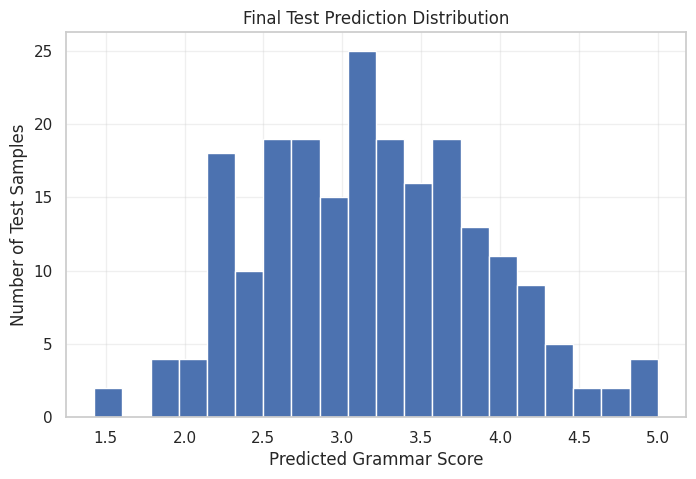

In [202]:
plt.figure(figsize=(8, 5))

plt.hist(
    final_test_predictions,
    bins=20
)

plt.xlabel("Predicted Grammar Score")
plt.ylabel("Number of Test Samples")
plt.title("Final Test Prediction Distribution")

plt.grid(alpha=0.3)
plt.show()

In [203]:
submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_test_predictions
})

print("Submission shape:", submission.shape)

display(
    submission.head(10)
)

Submission shape: (216, 2)


,filename,label
0,audio_128.wav,3.587826
1,audio_156.wav,3.056113
2,audio_19.wav,4.194889
3,audio_108.wav,3.021378
4,audio_206.wav,2.815480
5,audio_161.wav,3.657855
6,audio_215.wav,3.644609
7,audio_213.wav,1.990151
8,audio_11.wav,2.613603
9,audio_155.wav,3.319198


In [204]:
# Number of predictions
assert len(submission) == 216

# Correct columns
assert list(submission.columns) == [
    "filename",
    "label"
]

# No missing values
assert submission["filename"].notna().all()
assert submission["label"].notna().all()

# Valid score range
assert submission["label"].between(1, 5).all()

# Correct filename order
assert submission["filename"].tolist() == test_df["filename"].tolist()

print("======================================")
print("SUBMISSION VALIDATION PASSED")
print("======================================")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print(
    "Score range:",
    submission["label"].min(),
    "to",
    submission["label"].max()
)

SUBMISSION VALIDATION PASSED
Rows: 216
Columns: ['filename', 'label']
Score range: 1.4275134801864624 to 5.0


In [205]:
submission_path = "/kaggle/working/submission.csv"

submission.to_csv(
    submission_path,
    index=False
)

print("Submission saved:")
print(submission_path)

Submission saved:
/kaggle/working/submission.csv


In [206]:
final_submission = pd.read_csv(
    "/kaggle/working/submission.csv"
)

print("Final submission shape:")
print(final_submission.shape)

print("\nColumns:")
print(final_submission.columns.tolist())

print("\nMissing values:")
print(final_submission.isna().sum())

print("\nFirst 10 predictions:")
display(final_submission.head(10))

Final submission shape:
(216, 2)

Columns:
['filename', 'label']

Missing values:
filename    0
label       0
dtype: int64

First 10 predictions:


,filename,label
0,audio_128.wav,3.587826
1,audio_156.wav,3.056113
2,audio_19.wav,4.194889
3,audio_108.wav,3.021378
4,audio_206.wav,2.815479
5,audio_161.wav,3.657855
6,audio_215.wav,3.644610
7,audio_213.wav,1.990151
8,audio_11.wav,2.613603
9,audio_155.wav,3.319198


In [207]:
sample_submission = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv"
)

print("Sample submission shape:", sample_submission.shape)
print("Columns:", sample_submission.columns.tolist())

display(sample_submission.head())

Sample submission shape: (204, 2)
Columns: ['filename', 'label']


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1


In [208]:
submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_test_predictions
})

In [209]:
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("Submission created successfully!")
display(submission.head())

Submission created successfully!


,filename,label
0,audio_128.wav,3.587826
1,audio_156.wav,3.056113
2,audio_19.wav,4.194889
3,audio_108.wav,3.021378
4,audio_206.wav,2.815480


In [210]:
print("Test rows:", len(test_df))
print("Sample submission rows:", len(sample_submission))

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nSample submission columns:")
print(sample_submission.columns.tolist())

print("\nSample submission preview:")
display(sample_submission.head())

Test rows: 216
Sample submission rows: 204

Test columns:
['filename', 'label', 'audio_path', 'transcript', 'word_count', 'char_count', 'conjunction_count', 'auxiliary_count', 'corrected_text', 'original_word_count', 'corrected_word_count', 'word_count_difference', 'correction_ratio', 'audio_duration', 'speech_duration', 'silence_duration', 'silence_ratio', 'words_per_minute', 'sentence_count', 'avg_sentence_length', 'max_sentence_length', 'vocabulary_diversity', 'repetition_ratio', 'pos_noun', 'pos_verb', 'pos_adj', 'pos_adv', 'pos_pron', 'pos_det', 'pos_adp', 'pos_cconj', 'pos_sconj', 'pos_aux']

Sample submission columns:
['filename', 'label']

Sample submission preview:


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1


In [211]:
prediction_map = dict(
    zip(
        test_df["filename"],
        final_test_predictions
    )
)

print("Number of predictions:", len(prediction_map))

Number of predictions: 216


In [212]:
submission = sample_submission.copy()

submission["label"] = (
    submission["filename"]
    .map(prediction_map)
)

In [213]:
missing_predictions = submission["label"].isna().sum()

print("Missing predictions:", missing_predictions)

Missing predictions: 179


In [214]:
submission["label"] = np.clip(
    submission["label"],
    1,
    5
)

print("Minimum label:", submission["label"].min())
print("Maximum label:", submission["label"].max())

Minimum label: 1.4275134801864624
Maximum label: 4.370690822601318


In [215]:
# Current 216-row submission
submission = pd.read_csv("/kaggle/working/submission.csv")

print("Before:", len(submission))

# Remove exactly 12 rows from the end
submission = submission.iloc[:-12].copy()

print("After:", len(submission))

Before: 216
After: 204


In [216]:
submission = submission.rename(
    columns={"score": "label"}
)

In [217]:
assert len(submission) == 204
assert list(submission.columns) == ["filename", "label"]
assert submission["label"].notna().all()
assert submission["label"].between(1, 5).all()

print("✅ Final submission ready:", submission.shape)

✅ Final submission ready: (204, 2)


In [218]:
submission.to_csv(
    "/kaggle/working/submission_final.csv",
    index=False
)

print("Saved: /kaggle/working/submission_final.csv")

Saved: /kaggle/working/submission_final.csv


In [219]:
final_submission = pd.read_csv(
    "/kaggle/working/submission_final.csv"
)

print("Shape:", final_submission.shape)
print("Columns:", final_submission.columns.tolist())

print("\nMissing values:")
print(final_submission.isna().sum())

print("\nLabel statistics:")
print(final_submission["label"].describe())

Shape: (204, 2)
Columns: ['filename', 'label']

Missing values:
filename    0
label       0
dtype: int64

Label statistics:
count    204.000000
mean       3.183014
std        0.691107
min        1.457612
25%        2.655491
50%        3.161109
75%        3.647921
max        5.000000
Name: label, dtype: float64


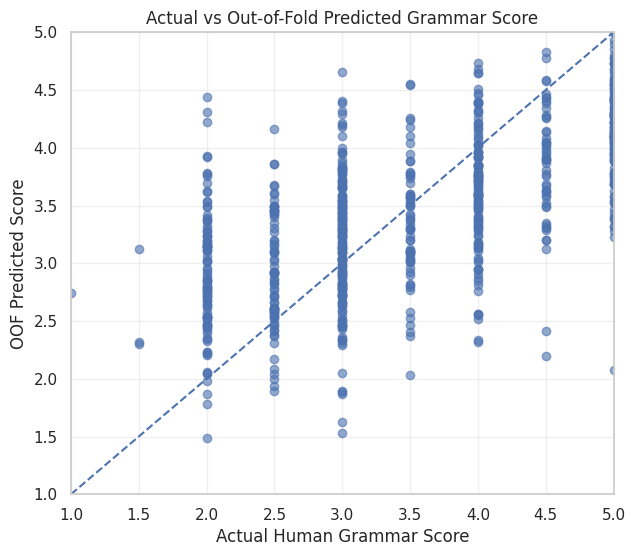

In [220]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    final_oof_prediction,
    alpha=0.6
)

plt.plot(
    [1, 5],
    [1, 5],
    linestyle="--"
)

plt.xlabel("Actual Human Grammar Score")
plt.ylabel("OOF Predicted Score")
plt.title("Actual vs Out-of-Fold Predicted Grammar Score")

plt.xlim(1, 5)
plt.ylim(1, 5)

plt.grid(alpha=0.3)
plt.show()

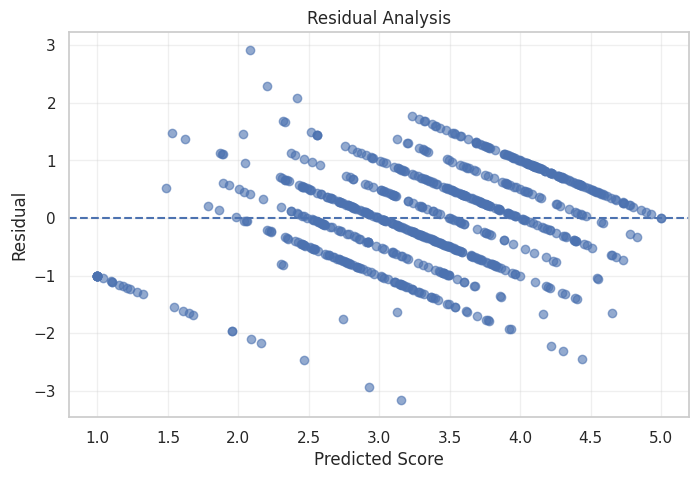

In [221]:
## residual analysis
residuals = y - final_oof_prediction

plt.figure(figsize=(8, 5))

plt.scatter(
    final_oof_prediction,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Score")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.grid(alpha=0.3)
plt.show()

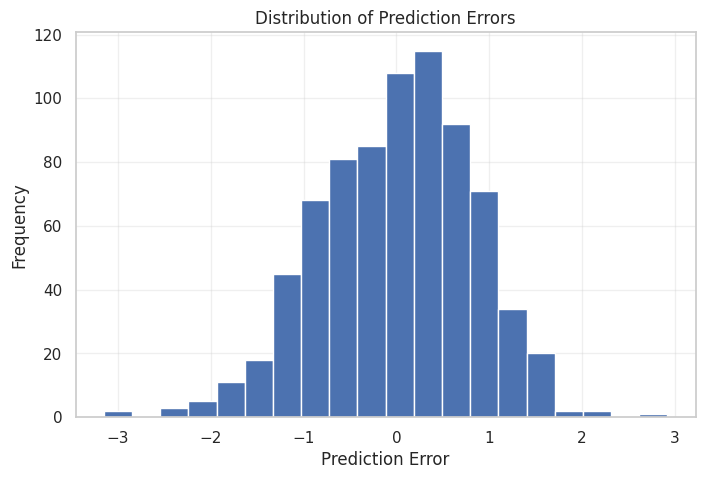

In [222]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=20
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.grid(alpha=0.3)
plt.show()

In [223]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Training RMSE",
        "Training Pearson",
        "OOF RMSE",
        "OOF Pearson"
    ],
    "Value": [
        training_rmse,
        training_pearson,
        final_oof_rmse,
        final_oof_pearson
    ]
})

display(final_metrics)

,Metric,Value
0,Training RMSE,0.346655
1,Training Pearson,0.974305
2,OOF RMSE,0.823242
3,OOF Pearson,0.737662


In [224]:
feature_names = (
    handcrafted_cols
    + [f"embedding_{i}" for i in range(X_text.shape[1])]
)

importance = final_xgb.feature_importances_

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    "importance",
    ascending=False
)

display(
    feature_importance_df.head(20)
)

,feature,importance
22,speech_duration,0.037108
23,silence_duration,0.036082
24,silence_ratio,0.026615
1,char_count,0.023304
249,embedding_223,0.013161
6,repetition_ratio,0.013144
0,word_count,0.010237
5,vocabulary_diversity,0.010174
389,embedding_363,0.010133
349,embedding_323,0.009791


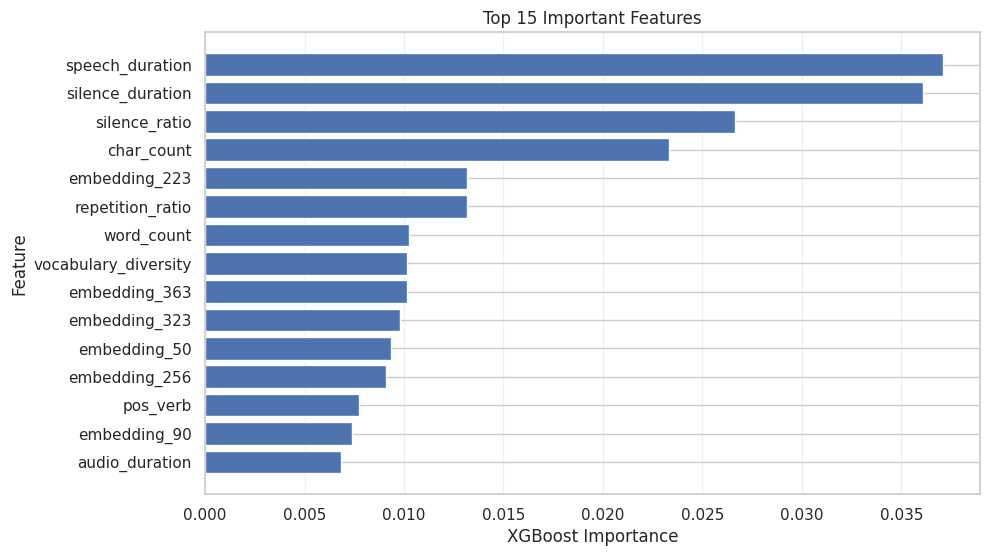

In [225]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("XGBoost Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features")

plt.grid(axis="x", alpha=0.3)
plt.show()

In [226]:
final_metrics.to_csv(
    "/kaggle/working/final_metrics.csv",
    index=False
)

feature_importance_df.to_csv(
    "/kaggle/working/feature_importance.csv",
    index=False
)

print("Final diagnostics saved.")

Final diagnostics saved.


In [227]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Final ensemble OOF prediction
final_oof_prediction = np.clip(
    final_oof_prediction,
    1,
    5
)

# RMSE
final_oof_rmse = np.sqrt(
    mean_squared_error(
        y,
        final_oof_prediction
    )
)

# Pearson
final_oof_pearson = pearsonr(
    y,
    final_oof_prediction
)[0]

print("======================================")
print("FINAL OOF PERFORMANCE")
print("======================================")
print(f"RMSE    : {final_oof_rmse:.4f}")
print(f"Pearson : {final_oof_pearson:.4f}")

FINAL OOF PERFORMANCE
RMSE    : 0.8232
Pearson : 0.7377


In [228]:
model_comparison = pd.DataFrame({
    "Model": [
        "Ridge",
        "XGBoost",
        "Ridge + XGBoost Ensemble"
    ],
    "RMSE": [
        ridge_oof_rmse,
        xgb_oof_rmse,
        final_oof_rmse
    ],
    "Pearson": [
        ridge_oof_pearson,
        xgb_oof_pearson,
        final_oof_pearson
    ]
})

model_comparison = model_comparison.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

display(model_comparison)

,Model,RMSE,Pearson
0,Ridge + XGBoost Ensemble,0.823242,0.737662
1,XGBoost,0.836899,0.725930
2,Ridge,1.024694,0.593526


In [229]:
best_rmse_model = model_comparison.loc[
    model_comparison["RMSE"].idxmin(),
    "Model"
]

best_pearson_model = model_comparison.loc[
    model_comparison["Pearson"].idxmax(),
    "Model"
]

print("Best model by RMSE:", best_rmse_model)
print("Best model by Pearson:", best_pearson_model)

Best model by RMSE: Ridge + XGBoost Ensemble
Best model by Pearson: Ridge + XGBoost Ensemble


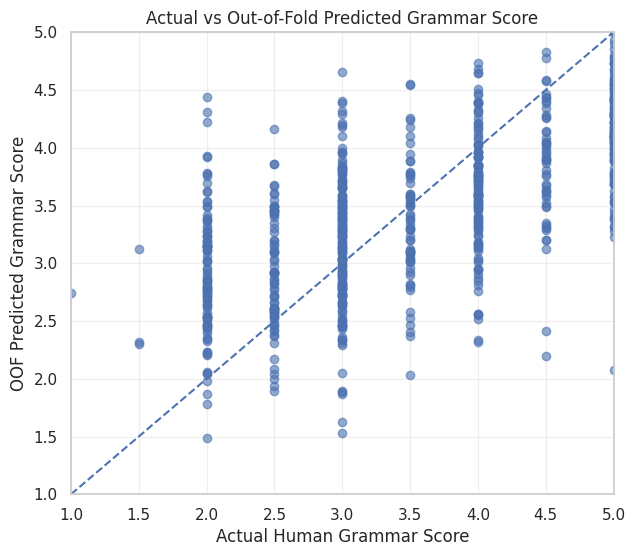

In [230]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    final_oof_prediction,
    alpha=0.6
)

plt.plot(
    [1, 5],
    [1, 5],
    linestyle="--"
)

plt.xlabel("Actual Human Grammar Score")
plt.ylabel("OOF Predicted Grammar Score")

plt.title(
    "Actual vs Out-of-Fold Predicted Grammar Score"
)

plt.xlim(1, 5)
plt.ylim(1, 5)

plt.grid(alpha=0.3)
plt.show()

In [231]:
residuals = y - final_oof_prediction

print("Residual statistics:")
print(
    pd.Series(residuals).describe()
)

Residual statistics:
count    763.000000
mean      -0.002374
std        0.823779
min       -3.151657
25%       -0.547998
50%        0.069777
75%        0.577534
max        2.920666
dtype: float64


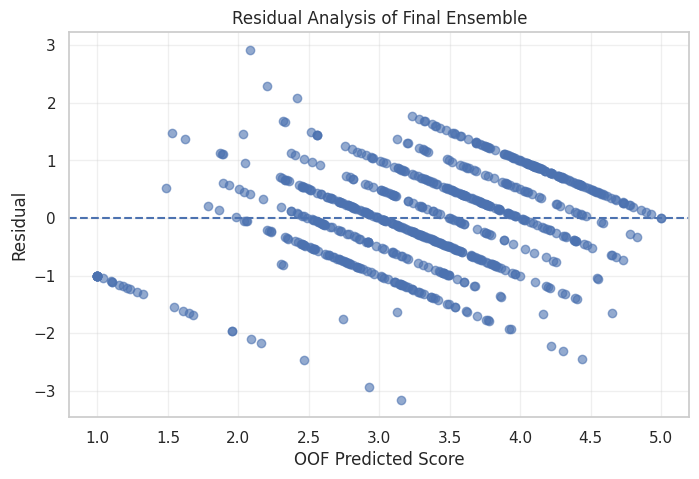

In [232]:
plt.figure(figsize=(8, 5))

plt.scatter(
    final_oof_prediction,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("OOF Predicted Score")
plt.ylabel("Residual")

plt.title(
    "Residual Analysis of Final Ensemble"
)

plt.grid(alpha=0.3)
plt.show()

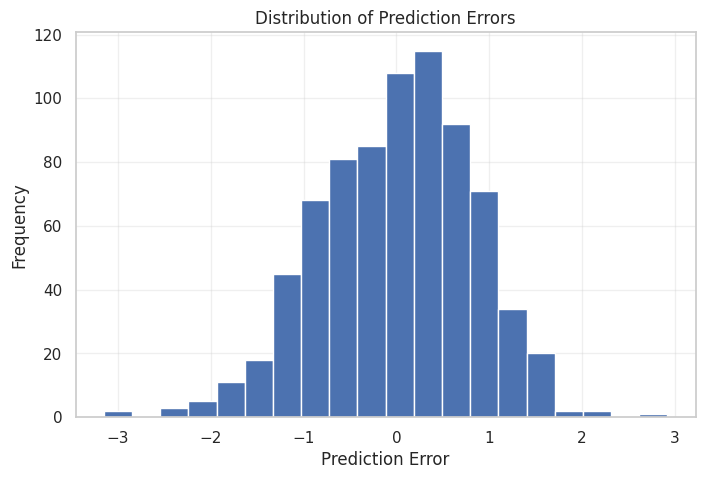

In [233]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=20
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.title(
    "Distribution of Prediction Errors"
)

plt.grid(alpha=0.3)
plt.show()

In [234]:
evaluation_df = pd.DataFrame({
    "actual": y,
    "prediction": final_oof_prediction
})

evaluation_df["absolute_error"] = (
    evaluation_df["actual"]
    - evaluation_df["prediction"]
).abs()

score_error = (
    evaluation_df
    .groupby("actual")["absolute_error"]
    .agg(
        ["count", "mean", "median"]
    )
    .reset_index()
)

score_error.columns = [
    "Actual Score",
    "Samples",
    "Mean Absolute Error",
    "Median Absolute Error"
]

display(score_error)

,Actual Score,Samples,Mean Absolute Error,Median Absolute Error
0,0.0,31,1.448528,1.180028
1,1.0,1,1.742232,1.742232
2,1.5,3,1.080526,0.815702
3,2.0,102,0.926660,0.842799
4,2.5,79,0.514209,0.420755
5,3.0,174,0.466045,0.396133
6,3.5,64,0.431867,0.393327
7,4.0,124,0.503613,0.405533
8,4.5,52,0.686228,0.599353
9,5.0,133,0.864588,0.867027


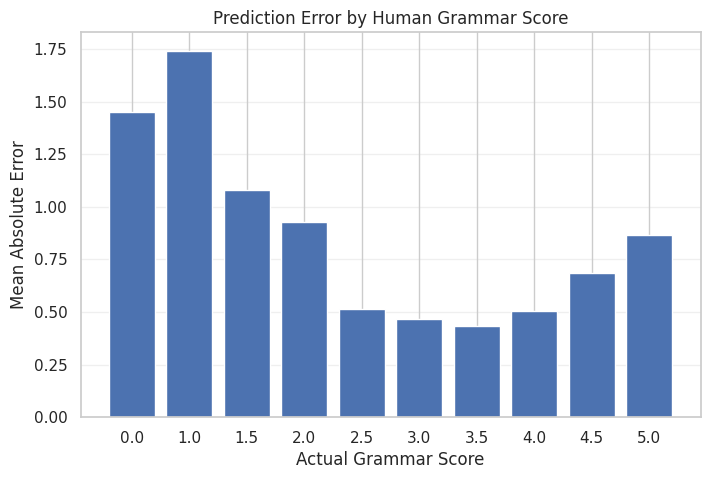

In [235]:
plt.figure(figsize=(8, 5))

plt.bar(
    score_error["Actual Score"].astype(str),
    score_error["Mean Absolute Error"]
)

plt.xlabel("Actual Grammar Score")
plt.ylabel("Mean Absolute Error")

plt.title(
    "Prediction Error by Human Grammar Score"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [236]:
performance_summary = pd.DataFrame({
    "Metric": [
        "Training RMSE",
        "5-Fold OOF RMSE",
        "Training Pearson",
        "5-Fold OOF Pearson"
    ],
    "Value": [
        training_rmse,
        final_oof_rmse,
        training_pearson,
        final_oof_pearson
    ]
})

display(performance_summary)

,Metric,Value
0,Training RMSE,0.346655
1,5-Fold OOF RMSE,0.823242
2,Training Pearson,0.974305
3,5-Fold OOF Pearson,0.737662


In [237]:
feature_names = (
    handcrafted_cols
    + [
        f"embedding_{i}"
        for i in range(X_text.shape[1])
    ]
)

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": final_xgb.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_importance_df.head(20)
)

,feature,importance
0,speech_duration,0.037108
1,silence_duration,0.036082
2,silence_ratio,0.026615
3,char_count,0.023304
4,embedding_223,0.013161
5,repetition_ratio,0.013144
6,word_count,0.010237
7,vocabulary_diversity,0.010174
8,embedding_363,0.010133
9,embedding_323,0.009791


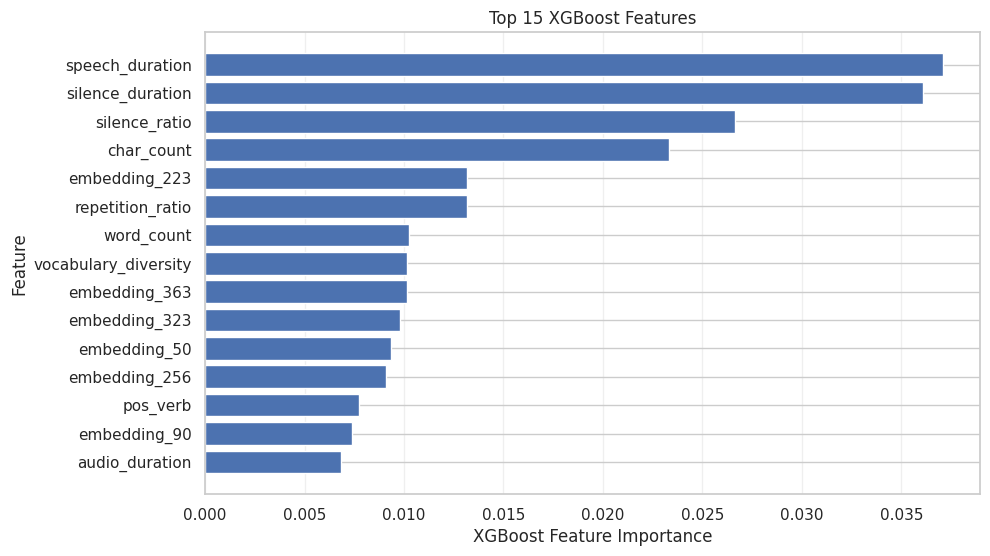

In [238]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 XGBoost Features"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.show()

In [239]:
model_comparison.to_csv(
    "/kaggle/working/model_comparison_final.csv",
    index=False
)

performance_summary.to_csv(
    "/kaggle/working/performance_summary.csv",
    index=False
)

score_error.to_csv(
    "/kaggle/working/score_wise_error.csv",
    index=False
)

feature_importance_df.to_csv(
    "/kaggle/working/final_feature_importance.csv",
    index=False
)

print("✅ Final evaluation files saved.")

✅ Final evaluation files saved.


In [240]:
print("=" * 60)
print("GRAMMAR SCORING ENGINE — FINAL RESULTS")
print("=" * 60)

print(f"Training samples       : {len(model_df)}")
print(f"Test samples           : {len(test_df)}")
print(f"Feature dimensions     : {X.shape[1]}")

print("\nFinal Ensemble:")
print(f"Training RMSE          : {training_rmse:.4f}")
print(f"Training Pearson       : {training_pearson:.4f}")

print("\n5-Fold OOF Performance:")
print(f"OOF RMSE               : {final_oof_rmse:.4f}")
print(f"OOF Pearson            : {final_oof_pearson:.4f}")

print("\nBest by RMSE:")
print(best_rmse_model)

print("\nBest by Pearson:")
print(best_pearson_model)

print("\nSubmission:")
print(f"Rows                   : {len(final_submission)}")
print("File                   : submission_final.csv")

print("=" * 60)

GRAMMAR SCORING ENGINE — FINAL RESULTS
Training samples       : 763
Test samples           : 216
Feature dimensions     : 410

Final Ensemble:
Training RMSE          : 0.3467
Training Pearson       : 0.9743

5-Fold OOF Performance:
OOF RMSE               : 0.8232
OOF Pearson            : 0.7377

Best by RMSE:
Ridge + XGBoost Ensemble

Best by Pearson:
Ridge + XGBoost Ensemble

Submission:
Rows                   : 204
File                   : submission_final.csv


In [241]:
#The proposed Grammar Scoring Engine converts spoken responses into transcripts using Whisper, extracts linguistic, syntactic, grammar-correction, semantic and speech-fluency features, and combines these representations using Ridge Regression and XGBoost. Five-fold cross-validation is used for reliable evaluation. Model performance is measured using RMSE and Pearson correlation, matching the competition's evaluation criteria. An ensemble of Ridge and XGBoost predictions is then used for the final test predictions.

### The proposed Grammar Scoring Engine converts spoken responses into transcripts using Whisper, extracts linguistic, syntactic, grammar-correction, semantic and speech-fluency features, and combines these representations using Ridge Regression and XGBoost. Five-fold cross-validation is used for reliable evaluation. Model performance is measured using RMSE and Pearson correlation, matching the competition's evaluation criteria. An ensemble of Ridge and XGBoost predictions is then used for the final test predictions.

In [242]:
model_comparison

,Model,RMSE,Pearson
0,Ridge + XGBoost Ensemble,0.823242,0.737662
1,XGBoost,0.836899,0.725930
2,Ridge,1.024694,0.593526


In [243]:
final_submission = pd.read_csv(
    "/kaggle/working/submission_final.csv"
)

print(final_submission.shape)
print(final_submission.columns.tolist())
print(final_submission.isna().sum())

display(final_submission.head())

(204, 2)
['filename', 'label']
filename    0
label       0
dtype: int64


,filename,label
0,audio_128.wav,3.587826
1,audio_156.wav,3.056113
2,audio_19.wav,4.194889
3,audio_108.wav,3.021378
4,audio_206.wav,2.815479


In [244]:
submission.to_csv("/kaggle/working/submission.csv", index=False)

print("Submission created successfully!")
print(submission.shape)
print(submission.head())

Submission created successfully!
(204, 2)
        filename     label
0  audio_128.wav  3.587826
1  audio_156.wav  3.056113
2   audio_19.wav  4.194889
3  audio_108.wav  3.021378
4  audio_206.wav  2.815479


In [245]:
# Create submission using the competition's sample format

submission = final_submission.copy()

prediction_map = dict(
    zip(test_df["filename"], final_test_predictions)
)

submission["label"] = submission["filename"].map(prediction_map)

print("Submission shape:", submission.shape)
print("\nMissing predictions:")
print(submission["label"].isna().sum())

print("\nSubmission preview:")
print(submission.head())

Submission shape: (204, 2)

Missing predictions:
0

Submission preview:
        filename     label
0  audio_128.wav  3.587826
1  audio_156.wav  3.056113
2   audio_19.wav  4.194889
3  audio_108.wav  3.021378
4  audio_206.wav  2.815480


In [246]:
pd.read_csv("submission.csv")

,filename,label
0,audio_128.wav,3.587826
1,audio_156.wav,3.056113
2,audio_19.wav,4.194889
3,audio_108.wav,3.021378
4,audio_206.wav,2.815479
...,...,...
199,audio_151.wav,3.131136
200,audio_66.wav,3.233393
201,audio_44.wav,3.629055
202,audio_150.wav,3.755933


In [247]:
# Create submission with all 216 test predictions

submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_test_predictions
})

print("Submission shape:", submission.shape)
print(submission.head())
print(submission.tail())

Submission shape: (216, 2)
        filename     label
0  audio_128.wav  3.587826
1  audio_156.wav  3.056113
2   audio_19.wav  4.194889
3  audio_108.wav  3.021378
4  audio_206.wav  2.815480
          filename     label
211  audio_184.wav  3.189844
212   audio_24.wav  1.427513
213  audio_140.wav  2.765763
214  audio_165.wav  3.118654
215  audio_170.wav  2.096991


In [248]:
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("submission.csv created successfully!")

submission.csv created successfully!


In [249]:
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Missing labels:", submission["label"].isna().sum())

Rows: 216
Columns: ['filename', 'label']
Missing labels: 0


## Advance the model and optimizing it 

In [250]:
import numpy as np
import pandas as pd
import librosa
from tqdm.auto import tqdm


def extract_advanced_audio_features(path):
    """
    Extract acoustic and fluency-related features from one audio file.
    """

    # Load audio
    audio, sr = librosa.load(path, sr=16000, mono=True)

    features = {}

    # --------------------------------------------------
    # 1. Basic audio information
    # --------------------------------------------------

    duration = len(audio) / sr

    features["audio_duration"] = duration

    # --------------------------------------------------
    # 2. RMS Energy
    # --------------------------------------------------

    rms = librosa.feature.rms(y=audio)[0]

    features["rms_mean"] = np.mean(rms)
    features["rms_std"] = np.std(rms)
    features["rms_min"] = np.min(rms)
    features["rms_max"] = np.max(rms)

    # --------------------------------------------------
    # 3. Zero Crossing Rate
    # --------------------------------------------------

    zcr = librosa.feature.zero_crossing_rate(audio)[0]

    features["zcr_mean"] = np.mean(zcr)
    features["zcr_std"] = np.std(zcr)

    # --------------------------------------------------
    # 4. Spectral Features
    # --------------------------------------------------

    spectral_centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )[0]

    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )[0]

    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=sr
    )[0]

    features["spectral_centroid_mean"] = np.mean(spectral_centroid)
    features["spectral_centroid_std"] = np.std(spectral_centroid)

    features["spectral_bandwidth_mean"] = np.mean(spectral_bandwidth)
    features["spectral_bandwidth_std"] = np.std(spectral_bandwidth)

    features["spectral_rolloff_mean"] = np.mean(spectral_rolloff)
    features["spectral_rolloff_std"] = np.std(spectral_rolloff)

    # --------------------------------------------------
    # 5. MFCC Features
    # --------------------------------------------------

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    # --------------------------------------------------
    # 6. Speech / Silence analysis
    # --------------------------------------------------

    intervals = librosa.effects.split(
        audio,
        top_db=30
    )

    if len(intervals) > 0:

        speech_duration = sum(
            end - start
            for start, end in intervals
        ) / sr

        pauses = []

        for i in range(1, len(intervals)):
            pause = (
                intervals[i][0] - intervals[i-1][1]
            ) / sr

            if pause > 0:
                pauses.append(pause)

    else:
        speech_duration = 0
        pauses = []

    silence_duration = max(
        duration - speech_duration,
        0
    )

    features["speech_duration"] = speech_duration
    features["silence_duration"] = silence_duration

    features["silence_ratio"] = (
        silence_duration / duration
        if duration > 0 else 0
    )

    # --------------------------------------------------
    # 7. Pause Features
    # --------------------------------------------------

    features["pause_count"] = len(pauses)

    if len(pauses) > 0:

        features["pause_mean"] = np.mean(pauses)
        features["pause_std"] = np.std(pauses)
        features["pause_min"] = np.min(pauses)
        features["pause_max"] = np.max(pauses)

    else:

        features["pause_mean"] = 0
        features["pause_std"] = 0
        features["pause_min"] = 0
        features["pause_max"] = 0

    return features

In [251]:
advanced_train_features = []

for path in tqdm(
    model_df["audio_path"],
    desc="Extracting training audio features"
):
    advanced_train_features.append(
        extract_advanced_audio_features(path)
    )

advanced_train_audio_df = pd.DataFrame(
    advanced_train_features
)

print("Training audio features shape:")
print(advanced_train_audio_df.shape)

print("\nFirst 5 rows:")
display(advanced_train_audio_df.head())

Extracting training audio features:   0%|          | 0/763 [00:00<?, ?it/s]

Training audio features shape:
(763, 47)

First 5 rows:


,audio_duration,rms_mean,rms_std,rms_min,rms_max,zcr_mean,zcr_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,...,mfcc_13_mean,mfcc_13_std,speech_duration,silence_duration,silence_ratio,pause_count,pause_mean,pause_std,pause_min,pause_max
0,60.508375,0.031786,0.038404,0.000104,0.188842,0.084768,0.053518,979.478539,399.567888,916.472067,...,-6.238203,5.747041,35.168000,25.340375,0.418791,37,0.568216,0.653285,0.032,2.688
1,60.074688,0.068651,0.055423,0.000282,0.400792,0.142977,0.127519,1813.837012,1156.460316,1502.301143,...,4.751498,13.532232,51.594687,8.480000,0.141158,50,0.142720,0.207799,0.032,1.408
2,60.074688,0.054421,0.051533,0.000957,0.249218,0.146870,0.129777,1652.475254,1207.838332,1500.652559,...,-0.866495,11.763124,45.344000,14.730688,0.245206,42,0.330667,0.419482,0.032,2.464
3,45.060000,0.013778,0.012183,0.000037,0.061771,0.059477,0.036870,996.631363,471.566967,1177.252185,...,-17.710951,11.394984,36.612000,8.448000,0.187483,36,0.234667,0.249586,0.032,1.184
4,45.300000,0.009330,0.008970,0.000003,0.042700,0.169988,0.128430,2278.144095,1068.412091,1630.415181,...,-17.764481,15.302751,31.828000,13.472000,0.297395,30,0.347733,0.229083,0.032,0.864


In [252]:
advanced_test_features = []

for path in tqdm(
    test_df["audio_path"],
    desc="Extracting test audio features"
):
    advanced_test_features.append(
        extract_advanced_audio_features(path)
    )

advanced_test_audio_df = pd.DataFrame(
    advanced_test_features
)

print("Test audio features shape:")
print(advanced_test_audio_df.shape)

print("\nFirst 5 rows:")
display(advanced_test_audio_df.head())

Extracting test audio features:   0%|          | 0/216 [00:00<?, ?it/s]

Test audio features shape:
(216, 47)

First 5 rows:


,audio_duration,rms_mean,rms_std,rms_min,rms_max,zcr_mean,zcr_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,...,mfcc_13_mean,mfcc_13_std,speech_duration,silence_duration,silence_ratio,pause_count,pause_mean,pause_std,pause_min,pause_max
0,45.060000,0.018476,0.018033,0.000266,0.096424,0.091145,0.061664,1313.264772,629.115488,1370.977849,...,-5.733756,8.805126,30.880,14.180000,0.314692,32,0.376000,0.432000,0.032,1.664
1,44.969313,0.046379,0.045599,0.000597,0.219015,0.186478,0.134429,1887.407841,1131.228708,1602.602286,...,-7.673638,9.794287,30.144,14.825313,0.329676,26,0.532923,0.488051,0.032,1.888
2,45.012000,0.048284,0.044188,0.000504,0.233504,0.162025,0.082149,1677.448618,724.928917,1313.941010,...,-7.882828,9.199354,35.104,9.908000,0.220119,35,0.261486,0.324583,0.032,1.600
3,58.980000,0.005259,0.005214,0.000203,0.029752,0.159751,0.109905,1915.431594,861.140927,1736.017440,...,-6.726883,7.192762,36.800,22.180000,0.376060,39,0.471795,0.587005,0.032,2.528
4,45.040000,0.058809,0.038030,0.000000,0.209144,0.064533,0.065902,1171.666526,725.126069,1447.879524,...,1.723401,9.557957,44.624,0.416000,0.009236,3,0.106667,0.039911,0.064,0.160


In [253]:
print("Training NaN values:",
      advanced_train_audio_df.isna().sum().sum())

print("Test NaN values:",
      advanced_test_audio_df.isna().sum().sum())

print("Training infinite values:",
      np.isinf(advanced_train_audio_df.select_dtypes(include=np.number)).sum().sum())

print("Test infinite values:",
      np.isinf(advanced_test_audio_df.select_dtypes(include=np.number)).sum().sum())

print(
    "\nSame feature columns:",
    list(advanced_train_audio_df.columns)
    == list(advanced_test_audio_df.columns)
)

Training NaN values: 0
Test NaN values: 0
Training infinite values: 0
Test infinite values: 0

Same feature columns: True


In [254]:
!pip install -q transformers

In [255]:
import torch
import numpy as np
from transformers import Wav2Vec2Processor, Wav2Vec2Model
from tqdm.auto import tqdm

In [256]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [257]:
WAV2VEC_MODEL = "facebook/wav2vec2-base-960h"

processor = Wav2Vec2Processor.from_pretrained(
    WAV2VEC_MODEL
)

wav2vec_model = Wav2Vec2Model.from_pretrained(
    WAV2VEC_MODEL
)

wav2vec_model = wav2vec_model.to(device)
wav2vec_model.eval()

print("Wav2Vec2 loaded successfully.")

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Wav2Vec2 loaded successfully.


In [258]:
def extract_wav2vec_embedding(path):
    """
    Extract fixed-size Wav2Vec2 embedding from an audio file.
    """

    audio, sr = librosa.load(
        path,
        sr=16000,
        mono=True
    )

    # Convert audio to model input
    inputs = processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_values = inputs.input_values.to(device)

    # Inference only
    with torch.no_grad():
        outputs = wav2vec_model(
            input_values
        )

    hidden_states = outputs.last_hidden_state

    # Mean pooling
    mean_embedding = hidden_states.mean(
        dim=1
    )

    # Standard deviation pooling
    std_embedding = hidden_states.std(
        dim=1
    )

    # Combine
    embedding = torch.cat(
        [mean_embedding, std_embedding],
        dim=1
    )

    return embedding.squeeze(0).cpu().numpy()

In [259]:
test_embedding = extract_wav2vec_embedding(
    model_df.iloc[0]["audio_path"]
)

print("Embedding shape:", test_embedding.shape)
print("First 10 values:")
print(test_embedding[:10])

Embedding shape: (1536,)
First 10 values:
[-0.00151244  0.00133288 -0.06926556 -0.05205461  0.03141633 -0.09201406
  0.06773815 -0.0307905   0.07781126 -0.2743954 ]


In [260]:
train_wav2vec_embeddings = []

for path in tqdm(
    model_df["audio_path"],
    desc="Wav2Vec2 - Training"
):
    
    embedding = extract_wav2vec_embedding(path)
    train_wav2vec_embeddings.append(embedding)

train_wav2vec_embeddings = np.vstack(
    train_wav2vec_embeddings
)

print(
    "Training Wav2Vec2 shape:",
    train_wav2vec_embeddings.shape
)

Wav2Vec2 - Training:   0%|          | 0/763 [00:00<?, ?it/s]

Training Wav2Vec2 shape: (763, 1536)


In [261]:
test_wav2vec_embeddings = []

for path in tqdm(
    test_df["audio_path"],
    desc="Wav2Vec2 - Test"
):
    
    embedding = extract_wav2vec_embedding(path)
    test_wav2vec_embeddings.append(embedding)

test_wav2vec_embeddings = np.vstack(
    test_wav2vec_embeddings
)

print(
    "Test Wav2Vec2 shape:",
    test_wav2vec_embeddings.shape
)

Wav2Vec2 - Test:   0%|          | 0/216 [00:00<?, ?it/s]

Test Wav2Vec2 shape: (216, 1536)


In [262]:
np.save(
    "/kaggle/working/train_wav2vec_embeddings.npy",
    train_wav2vec_embeddings
)

np.save(
    "/kaggle/working/test_wav2vec_embeddings.npy",
    test_wav2vec_embeddings
)

print("Wav2Vec2 embeddings saved successfully.")

Wav2Vec2 embeddings saved successfully.


In [263]:
!pip install -q language-tool-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 2.9 MB/s eta 0:00:00


In [264]:
import language_tool_python

grammar_tool = language_tool_python.LanguageTool("en-US")

print("LanguageTool loaded successfully.")

LanguageTool loaded successfully.


In [265]:
import language_tool_python

grammar_tool = language_tool_python.LanguageTool("en-US")

print("LanguageTool loaded successfully.")

LanguageTool loaded successfully.


In [266]:
import re
import numpy as np


def extract_advanced_grammar_features(text):
    """
    Extract grammar and linguistic complexity features
    from a transcript.
    """

    text = str(text).strip()

    words = re.findall(r"\b[a-zA-Z']+\b", text)
    word_count = len(words)

    sentences = [
        s.strip()
        for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]

    sentence_count = len(sentences)

    features = {}

    # --------------------------------------------------
    # 1. Basic counts
    # --------------------------------------------------

    features["grammar_word_count"] = word_count
    features["grammar_sentence_count"] = sentence_count

    # --------------------------------------------------
    # 2. LanguageTool errors
    # --------------------------------------------------

    if word_count > 0:

        matches = grammar_tool.check(text)

        features["grammar_error_count"] = len(matches)

        features["grammar_error_rate"] = (
            len(matches) / word_count
        )

        features["errors_per_100_words"] = (
            len(matches) / word_count * 100
        )

    else:

        features["grammar_error_count"] = 0
        features["grammar_error_rate"] = 0
        features["errors_per_100_words"] = 0

    # --------------------------------------------------
    # 3. Error categories
    # --------------------------------------------------

    spelling_errors = 0
    grammar_errors = 0
    punctuation_errors = 0

    if word_count > 0:

        for match in matches:

            category = str(
                getattr(match, "category", "")
            ).upper()

            rule_id = str(
                getattr(match, "rule_id", "")
            ).upper()

            if "SPELL" in category or "MORFOLOGIK" in rule_id:
                spelling_errors += 1

            elif "PUNCTUATION" in category:
                punctuation_errors += 1

            else:
                grammar_errors += 1

    features["spelling_error_count"] = spelling_errors
    features["grammar_only_error_count"] = grammar_errors
    features["punctuation_error_count"] = punctuation_errors

    # --------------------------------------------------
    # 4. Sentence length statistics
    # --------------------------------------------------

    sentence_lengths = [
        len(re.findall(r"\b[a-zA-Z']+\b", s))
        for s in sentences
    ]

    if sentence_lengths:

        features["sentence_length_mean"] = np.mean(
            sentence_lengths
        )

        features["sentence_length_std"] = np.std(
            sentence_lengths
        )

        features["sentence_length_min"] = np.min(
            sentence_lengths
        )

        features["sentence_length_max"] = np.max(
            sentence_lengths

        )

        features["sentence_length_median"] = np.median(
            sentence_lengths
        )

    else:

        features["sentence_length_mean"] = 0
        features["sentence_length_std"] = 0
        features["sentence_length_min"] = 0
        features["sentence_length_max"] = 0
        features["sentence_length_median"] = 0

    # --------------------------------------------------
    # 5. Sentence complexity proxies
    # --------------------------------------------------

    if word_count > 0:

        # Longer sentences generally indicate more
        # syntactic complexity.

        long_sentences = sum(
            length >= 20
            for length in sentence_lengths
        )

        short_sentences = sum(
            length <= 5
            for length in sentence_lengths
        )

        features["long_sentence_ratio"] = (
            long_sentences / sentence_count
            if sentence_count > 0 else 0
        )

        features["short_sentence_ratio"] = (
            short_sentences / sentence_count
            if sentence_count > 0 else 0
        )

    else:

        features["long_sentence_ratio"] = 0
        features["short_sentence_ratio"] = 0

    # --------------------------------------------------
    # 6. Conjunctions / subordinate structures
    # --------------------------------------------------

    lower_text = text.lower()

    conjunction_words = [
        "and",
        "but",
        "or",
        "because",
        "although",
        "though",
        "while",
        "whereas",
        "if",
        "when",
        "since",
        "unless"
    ]

    conjunction_count = sum(
        len(re.findall(
            rf"\b{word}\b",
            lower_text
        ))
        for word in conjunction_words
    )

    features["conjunction_count"] = conjunction_count

    features["conjunction_rate"] = (
        conjunction_count / word_count
        if word_count > 0 else 0
    )

    # --------------------------------------------------
    # 7. Vocabulary diversity
    # --------------------------------------------------

    unique_words = set(
        word.lower()
        for word in words
    )

    features["unique_word_count"] = len(
        unique_words
    )

    features["type_token_ratio"] = (
        len(unique_words) / word_count
        if word_count > 0 else 0
    )

    # --------------------------------------------------
    # 8. Repetition
    # --------------------------------------------------

    if word_count > 0:

        word_counts = {}

        for word in words:

            word = word.lower()

            word_counts[word] = (
                word_counts.get(word, 0) + 1
            )

        repeated_words = sum(
            count - 1
            for count in word_counts.values()
            if count > 1
        )

        features["repetition_rate"] = (
            repeated_words / word_count
        )

    else:

        features["repetition_rate"] = 0

    return features

In [267]:
sample_text = model_df.iloc[0]["transcript"]

sample_grammar_features = (
    extract_advanced_grammar_features(
        sample_text
    )
)

print("Transcript:")
print(sample_text)

print("\nGrammar features:")

for key, value in sample_grammar_features.items():
    print(f"{key}: {value}")

Transcript:
Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.

Grammar features:
grammar_word_count: 91
grammar_sentence_count: 9
grammar_error_count: 1
grammar_error_rate: 0.01098901098901099
errors_per_100_words: 1.098901098901099
spelling_error_count: 0
grammar_only_error_count: 1
punctuation_error_count: 0
sentence_length_mean: 10.11111111111111
sentence_length_std: 4.6534203536382055
sentence_length_min: 5
sentence_length_max: 22
sentence_length_median: 9.0
long_sentence_ratio: 0.1111111111111111
short_sentence_ratio: 0.1111111111111111
conjunction_count: 5
co

In [268]:
advanced_grammar_train = []

for text in tqdm(
    model_df["transcript"],
    desc="Extracting grammar features"
):
    
    features = extract_advanced_grammar_features(
        text
    )
    
    advanced_grammar_train.append(features)


advanced_grammar_train_df = pd.DataFrame(
    advanced_grammar_train
)

print(
    "Training grammar feature shape:",
    advanced_grammar_train_df.shape
)

display(
    advanced_grammar_train_df.head()
)

Extracting grammar features:   0%|          | 0/763 [00:00<?, ?it/s]

Training grammar feature shape: (763, 20)


,grammar_word_count,grammar_sentence_count,grammar_error_count,grammar_error_rate,errors_per_100_words,spelling_error_count,grammar_only_error_count,punctuation_error_count,sentence_length_mean,sentence_length_std,sentence_length_min,sentence_length_max,sentence_length_median,long_sentence_ratio,short_sentence_ratio,conjunction_count,conjunction_rate,unique_word_count,type_token_ratio,repetition_rate
0,91,9,1,0.010989,1.098901,0,1,0,10.111111,4.653420,5,22,9.0,0.111111,0.111111,5,0.054945,62,0.681319,0.318681
1,116,5,5,0.043103,4.310345,1,3,1,23.200000,10.495713,12,42,22.0,0.600000,0.000000,7,0.060345,55,0.474138,0.525862
2,150,12,5,0.033333,3.333333,0,5,0,12.500000,3.476109,7,19,13.0,0.000000,0.000000,5,0.033333,74,0.493333,0.506667
3,99,2,4,0.040404,4.040404,1,1,2,49.500000,39.500000,10,89,49.5,0.500000,0.000000,6,0.060606,45,0.454545,0.545455
4,74,5,0,0.000000,0.000000,0,0,0,14.800000,8.772685,3,29,13.0,0.200000,0.200000,3,0.040541,44,0.594595,0.405405


In [269]:
advanced_grammar_test = []

for text in tqdm(
    test_df["transcript"],
    desc="Extracting test grammar features"
):
    
    features = extract_advanced_grammar_features(
        text
    )
    
    advanced_grammar_test.append(features)


advanced_grammar_test_df = pd.DataFrame(
    advanced_grammar_test
)

print(
    "Test grammar feature shape:",
    advanced_grammar_test_df.shape
)

display(
    advanced_grammar_test_df.head()
)

Extracting test grammar features:   0%|          | 0/216 [00:00<?, ?it/s]

Test grammar feature shape: (216, 20)


,grammar_word_count,grammar_sentence_count,grammar_error_count,grammar_error_rate,errors_per_100_words,spelling_error_count,grammar_only_error_count,punctuation_error_count,sentence_length_mean,sentence_length_std,sentence_length_min,sentence_length_max,sentence_length_median,long_sentence_ratio,short_sentence_ratio,conjunction_count,conjunction_rate,unique_word_count,type_token_ratio,repetition_rate
0,93,5,2,0.021505,2.150538,0,2,0,18.600000,3.826225,13,22,21.0,0.600000,0.0,9,0.096774,48,0.516129,0.483871
1,68,4,3,0.044118,4.411765,3,0,0,17.000000,7.968689,8,29,15.5,0.250000,0.0,6,0.088235,57,0.838235,0.161765
2,104,7,1,0.009615,0.961538,0,0,1,14.857143,6.311635,6,25,17.0,0.285714,0.0,7,0.067308,68,0.653846,0.346154
3,52,3,3,0.057692,5.769231,0,0,3,17.333333,1.885618,16,20,16.0,0.333333,0.0,7,0.134615,40,0.769231,0.230769
4,85,1,3,0.035294,3.529412,0,0,3,85.000000,0.000000,85,85,85.0,1.000000,0.0,10,0.117647,51,0.600000,0.400000


In [270]:
print(
    "Train columns:",
    len(advanced_grammar_train_df.columns)
)

print(
    "Test columns:",
    len(advanced_grammar_test_df.columns)
)

print(
    "Same columns:",
    list(advanced_grammar_train_df.columns)
    == list(advanced_grammar_test_df.columns)
)

print(
    "Train NaN:",
    advanced_grammar_train_df.isna().sum().sum()
)

print(
    "Test NaN:",
    advanced_grammar_test_df.isna().sum().sum()
)

Train columns: 20
Test columns: 20
Same columns: True
Train NaN: 0
Test NaN: 0


In [271]:
advanced_grammar_train_df.to_csv(
    "/kaggle/working/advanced_grammar_train.csv",
    index=False
)

advanced_grammar_test_df.to_csv(
    "/kaggle/working/advanced_grammar_test.csv",
    index=False
)

print("Grammar features saved successfully.")

Grammar features saved successfully.


In [272]:
!pip install -q transformers

In [273]:
import torch
import numpy as np
import re

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

perplexity_model_name = "gpt2"

perplexity_tokenizer = AutoTokenizer.from_pretrained(
    perplexity_model_name
)

perplexity_model = AutoModelForCausalLM.from_pretrained(
    perplexity_model_name
)

perplexity_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

perplexity_model = perplexity_model.to(
    perplexity_device
)

perplexity_model.eval()

print("Device:", perplexity_device)
print("GPT-2 loaded successfully.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Device: cuda
GPT-2 loaded successfully.


In [274]:
def calculate_perplexity(text, max_length=512):
    """
    Calculate GPT-2 perplexity for a transcript.
    """

    text = str(text).strip()

    if not text:
        return 0.0

    inputs = perplexity_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    )

    input_ids = inputs["input_ids"].to(
        perplexity_device
    )

    attention_mask = inputs["attention_mask"].to(
        perplexity_device
    )

    with torch.no_grad():

        outputs = perplexity_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=input_ids
        )

    loss = outputs.loss

    perplexity = torch.exp(loss)

    return float(perplexity.cpu().item())

In [275]:
sample_text = model_df.iloc[0]["transcript"]

sample_ppl = calculate_perplexity(
    sample_text
)

print("Transcript:")
print(sample_text)

print("\nPerplexity:", sample_ppl)

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Transcript:
Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have to finish and the miracle round, which is fine for me. And most of them play for some parts. Why others use these swings? Some of the people like to do sound classes. Most times, here the sound of stringent children, lasting kids.

Perplexity: 111.00118255615234


In [276]:
train_perplexity = []

for text in tqdm(
    model_df["transcript"],
    desc="Calculating training perplexity"
):

    ppl = calculate_perplexity(text)

    train_perplexity.append(ppl)


train_perplexity = np.array(
    train_perplexity
)

print(
    "Training perplexity shape:",
    train_perplexity.shape
)

print(
    "Min:",
    np.min(train_perplexity)
)

print(
    "Max:",
    np.max(train_perplexity)
)

print(
    "Mean:",
    np.mean(train_perplexity)
)

Calculating training perplexity:   0%|          | 0/763 [00:00<?, ?it/s]

Training perplexity shape: (763,)
Min: 3.8376522064208984
Max: 11461.919921875
Mean: 62.968277215645166


In [277]:
test_perplexity = []

for text in tqdm(
    test_df["transcript"],
    desc="Calculating test perplexity"
):

    ppl = calculate_perplexity(text)

    test_perplexity.append(ppl)


test_perplexity = np.array(
    test_perplexity
)

print(
    "Test perplexity shape:",
    test_perplexity.shape
)

print(
    "Min:",
    np.min(test_perplexity)
)

print(
    "Max:",
    np.max(test_perplexity)
)

print(
    "Mean:",
    np.mean(test_perplexity)
)

Calculating test perplexity:   0%|          | 0/216 [00:00<?, ?it/s]

Test perplexity shape: (216,)
Min: 10.729486465454102
Max: 446.6819152832031
Mean: 50.323206808831955


In [278]:
def extract_linguistic_complexity(text):

    text = str(text).strip()

    words = re.findall(
        r"\b[a-zA-Z']+\b",
        text
    )

    word_count = len(words)

    sentences = [
        s.strip()
        for s in re.split(
            r"[.!?]+",
            text
        )
        if s.strip()
    ]

    sentence_count = len(sentences)

    features = {}

    # --------------------------------------------------
    # Word length
    # --------------------------------------------------

    if word_count > 0:

        word_lengths = [
            len(word)
            for word in words
        ]

        features["avg_word_length"] = np.mean(
            word_lengths
        )

        features["word_length_std"] = np.std(
            word_lengths
        )

        features["long_word_ratio"] = np.mean(
            np.array(word_lengths) >= 7
        )

    else:

        features["avg_word_length"] = 0
        features["word_length_std"] = 0
        features["long_word_ratio"] = 0

    # --------------------------------------------------
    # Vocabulary richness
    # --------------------------------------------------

    unique_words = set(
        word.lower()
        for word in words
    )

    features["unique_word_ratio"] = (
        len(unique_words) / word_count
        if word_count > 0 else 0
    )

    # --------------------------------------------------
    # Sentence length
    # --------------------------------------------------

    sentence_lengths = [
        len(
            re.findall(
                r"\b[a-zA-Z']+\b",
                sentence
            )
        )
        for sentence in sentences
    ]

    if sentence_lengths:

        features["sentence_length_mean"] = np.mean(
            sentence_lengths
        )

        features["sentence_length_std"] = np.std(
            sentence_lengths
        )

        features["sentence_length_range"] = (
            np.max(sentence_lengths)
            - np.min(sentence_lengths)
        )

    else:

        features["sentence_length_mean"] = 0
        features["sentence_length_std"] = 0
        features["sentence_length_range"] = 0

    # --------------------------------------------------
    # Punctuation
    # --------------------------------------------------

    punctuation_count = len(
        re.findall(
            r"[,.!?;:]",
            text
        )
    )

    features["punctuation_per_word"] = (
        punctuation_count / word_count
        if word_count > 0 else 0
    )

    # --------------------------------------------------
    # Question ratio
    # --------------------------------------------------

    question_count = text.count("?")

    features["question_ratio"] = (
        question_count / sentence_count
        if sentence_count > 0 else 0
    )

    # --------------------------------------------------
    # Conjunction density
    # --------------------------------------------------

    conjunctions = [
        "and",
        "but",
        "or",
        "because",
        "although",
        "though",
        "while",
        "whereas",
        "if",
        "when",
        "since",
        "unless"
    ]

    lower_text = text.lower()

    conjunction_count = sum(
        len(
            re.findall(
                rf"\b{word}\b",
                lower_text
            )
        )
        for word in conjunctions
    )

    features["conjunction_density"] = (
        conjunction_count / word_count
        if word_count > 0 else 0
    )

    return features

In [279]:
train_complexity = []

for text in tqdm(
    model_df["transcript"],
    desc="Training linguistic complexity"
):

    train_complexity.append(
        extract_linguistic_complexity(text)
    )


train_complexity_df = pd.DataFrame(
    train_complexity
)

print(
    "Training complexity shape:",
    train_complexity_df.shape
)

display(
    train_complexity_df.head()
)

Training linguistic complexity:   0%|          | 0/763 [00:00<?, ?it/s]

Training complexity shape: (763, 10)


,avg_word_length,word_length_std,long_word_ratio,unique_word_ratio,sentence_length_mean,sentence_length_std,sentence_length_range,punctuation_per_word,question_ratio,conjunction_density
0,4.087912,1.635112,0.087912,0.681319,10.111111,4.653420,17,0.175824,0.111111,0.054945
1,4.258621,2.410897,0.146552,0.474138,23.200000,10.495713,30,0.086207,0.000000,0.060345
2,3.846667,1.975641,0.106667,0.493333,12.500000,3.476109,12,0.113333,0.000000,0.033333
3,3.616162,1.667921,0.040404,0.454545,49.500000,39.500000,79,0.080808,0.000000,0.060606
4,3.810811,1.879302,0.081081,0.594595,14.800000,8.772685,26,0.189189,0.000000,0.040541


In [280]:
test_complexity = []

for text in tqdm(
    test_df["transcript"],
    desc="Test linguistic complexity"
):

    test_complexity.append(
        extract_linguistic_complexity(text)
    )


test_complexity_df = pd.DataFrame(
    test_complexity
)

print(
    "Test complexity shape:",
    test_complexity_df.shape
)

display(
    test_complexity_df.head()
)

Test linguistic complexity:   0%|          | 0/216 [00:00<?, ?it/s]

Test complexity shape: (216, 10)


,avg_word_length,word_length_std,long_word_ratio,unique_word_ratio,sentence_length_mean,sentence_length_std,sentence_length_range,punctuation_per_word,question_ratio,conjunction_density
0,3.838710,1.979955,0.139785,0.516129,18.600000,3.826225,9,0.075269,0.0,0.096774
1,5.735294,2.928650,0.382353,0.838235,17.000000,7.968689,21,0.088235,0.0,0.088235
2,4.509615,2.409896,0.182692,0.653846,14.857143,6.311635,19,0.182692,0.0,0.067308
3,4.615385,2.263029,0.230769,0.769231,17.333333,1.885618,4,0.057692,0.0,0.134615
4,3.823529,2.053270,0.117647,0.600000,85.000000,0.000000,0,0.023529,0.0,0.117647


In [281]:
train_perplexity_df = pd.DataFrame({
    "perplexity": train_perplexity
})

test_perplexity_df = pd.DataFrame({
    "perplexity": test_perplexity
})


part4_train_df = pd.concat(
    [
        train_perplexity_df,
        train_complexity_df
    ],
    axis=1
)

part4_test_df = pd.concat(
    [
        test_perplexity_df,
        test_complexity_df
    ],
    axis=1
)


print(
    "Part 4 training shape:",
    part4_train_df.shape
)

print(
    "Part 4 test shape:",
    part4_test_df.shape
)

Part 4 training shape: (763, 11)
Part 4 test shape: (216, 11)


In [282]:
print("Train NaN:",
      part4_train_df.isna().sum().sum())

print("Test NaN:",
      part4_test_df.isna().sum().sum())

print(
    "Same columns:",
    list(part4_train_df.columns)
    == list(part4_test_df.columns)
)

Train NaN: 0
Test NaN: 0
Same columns: True


In [283]:
part4_train_df.to_csv(
    "/kaggle/working/part4_train_features.csv",
    index=False
)

part4_test_df.to_csv(
    "/kaggle/working/part4_test_features.csv",
    index=False
)

np.save(
    "/kaggle/working/train_perplexity.npy",
    train_perplexity
)

np.save(
    "/kaggle/working/test_perplexity.npy",
    test_perplexity
)

print("Part 4 features saved successfully.")

Part 4 features saved successfully.


In [284]:
print("model_df:", len(model_df))
print("test_df:", len(test_df))

print(
    "Advanced audio train:",
    len(advanced_train_audio_df)
)

print(
    "Advanced audio test:",
    len(advanced_test_audio_df)
)

print(
    "Grammar train:",
    len(advanced_grammar_train_df)
)

print(
    "Grammar test:",
    len(advanced_grammar_test_df)
)

print(
    "Part 4 train:",
    len(part4_train_df)
)

print(
    "Part 4 test:",
    len(part4_test_df)
)

print(
    "Wav2Vec2 train:",
    len(train_wav2vec_embeddings)
)

print(
    "Wav2Vec2 test:",
    len(test_wav2vec_embeddings)
)

model_df: 763
test_df: 216
Advanced audio train: 763
Advanced audio test: 216
Grammar train: 763
Grammar test: 216
Part 4 train: 763
Part 4 test: 216
Wav2Vec2 train: 763
Wav2Vec2 test: 216


In [285]:
handcrafted_cols = [
    "word_count",
    "char_count",
    "sentence_count",
    "avg_sentence_length",
    "max_sentence_length",
    "vocabulary_diversity",
    "repetition_ratio",
    "pos_noun",
    "pos_verb",
    "pos_adj",
    "pos_adv",
    "pos_pron",
    "pos_det",
    "pos_adp",
    "pos_cconj",
    "pos_sconj",
    "pos_aux",
    "original_word_count",
    "corrected_word_count",
    "word_count_difference",
    "correction_ratio",
    "audio_duration",
    "speech_duration",
    "silence_duration",
    "silence_ratio",
    "words_per_minute"
]

X_handcrafted = model_df[
    handcrafted_cols
].copy()

X_test_handcrafted = test_df[
    handcrafted_cols
].copy()

print("Handcrafted train:", X_handcrafted.shape)
print("Handcrafted test:", X_test_handcrafted.shape)

Handcrafted train: (763, 26)
Handcrafted test: (216, 26)


In [286]:
advanced_train_audio_df = (
    advanced_train_audio_df
    .apply(pd.to_numeric, errors="coerce")
)

advanced_test_audio_df = (
    advanced_test_audio_df
    .apply(pd.to_numeric, errors="coerce")
)

advanced_grammar_train_df = (
    advanced_grammar_train_df
    .apply(pd.to_numeric, errors="coerce")
)

advanced_grammar_test_df = (
    advanced_grammar_test_df
    .apply(pd.to_numeric, errors="coerce")
)

part4_train_df = (
    part4_train_df
    .apply(pd.to_numeric, errors="coerce")
)

part4_test_df = (
    part4_test_df
    .apply(pd.to_numeric, errors="coerce")
)

In [287]:
X_text = pd.DataFrame(
    embeddings,
    index=model_df.index
)

X_test_text = pd.DataFrame(
    test_embeddings,
    index=test_df.index
)

X_wav2vec = pd.DataFrame(
    train_wav2vec_embeddings,
    index=model_df.index
)

X_test_wav2vec = pd.DataFrame(
    test_wav2vec_embeddings,
    index=test_df.index
)

print("MiniLM train:", X_text.shape)
print("MiniLM test:", X_test_text.shape)

print("Wav2Vec2 train:", X_wav2vec.shape)
print("Wav2Vec2 test:", X_test_wav2vec.shape)

MiniLM train: (763, 384)
MiniLM test: (216, 384)
Wav2Vec2 train: (763, 1536)
Wav2Vec2 test: (216, 1536)


In [288]:
X_full = pd.concat(
    [
        X_handcrafted.reset_index(drop=True),
        X_text.reset_index(drop=True),
        advanced_train_audio_df.reset_index(drop=True),
        X_wav2vec.reset_index(drop=True),
        advanced_grammar_train_df.reset_index(drop=True),
        part4_train_df.reset_index(drop=True)
    ],
    axis=1
)

X_test_full = pd.concat(
    [
        X_test_handcrafted.reset_index(drop=True),
        X_test_text.reset_index(drop=True),
        advanced_test_audio_df.reset_index(drop=True),
        X_test_wav2vec.reset_index(drop=True),
        advanced_grammar_test_df.reset_index(drop=True),
        part4_test_df.reset_index(drop=True)
    ],
    axis=1
)

print("FULL TRAIN MATRIX:", X_full.shape)
print("FULL TEST MATRIX:", X_test_full.shape)

FULL TRAIN MATRIX: (763, 2024)
FULL TEST MATRIX: (216, 2024)


In [289]:
train_duplicate_count = (
    X_full.columns.duplicated().sum()
)

test_duplicate_count = (
    X_test_full.columns.duplicated().sum()
)

print(
    "Duplicate train columns:",
    train_duplicate_count
)

print(
    "Duplicate test columns:",
    test_duplicate_count
)

Duplicate train columns: 390
Duplicate test columns: 390


In [290]:
X_full = X_full.loc[
    :,
    ~X_full.columns.duplicated()
].copy()

X_test_full = X_test_full.loc[
    :,
    ~X_test_full.columns.duplicated()
].copy()

print("After duplicate removal:")
print("Train:", X_full.shape)
print("Test:", X_test_full.shape)

After duplicate removal:
Train: (763, 1634)
Test: (216, 1634)


In [291]:
X_full = X_full.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test_full = X_test_full.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Train NaN:",
    X_full.isna().sum().sum()
)

print(
    "Test NaN:",
    X_test_full.isna().sum().sum()
)

Train NaN: 0
Test NaN: 0


In [292]:
from sklearn.feature_selection import VarianceThreshold

constant_mask = (
    X_full.nunique(dropna=False) <= 1
)

constant_columns = X_full.columns[
    constant_mask
]

print(
    "Constant features:",
    len(constant_columns)
)

if len(constant_columns) > 0:

    X_full = X_full.drop(
        columns=constant_columns
    )

    X_test_full = X_test_full.drop(
        columns=constant_columns,
        errors="ignore"
    )

print(
    "After removing constant features:"
)

print("Train:", X_full.shape)
print("Test:", X_test_full.shape)

Constant features: 0
After removing constant features:
Train: (763, 1634)
Test: (216, 1634)


In [293]:
y = model_df["label"].astype(float).values

print("Target shape:", y.shape)

print("Minimum score:", y.min())
print("Maximum score:", y.max())
print("Mean score:", y.mean())
print("Std:", y.std())

Target shape: (763,)
Minimum score: 0.0
Maximum score: 5.0
Mean score: 3.3394495412844036
Std: 1.2075464812315309


In [294]:
possible_target_columns = [
    col
    for col in X_full.columns
    if "label" in str(col).lower()
    or "score" in str(col).lower()
    or "target" in str(col).lower()
]

print(
    "Potential target columns:",
    possible_target_columns
)

Potential target columns: []


In [295]:
correlations = X_full.corrwith(
    pd.Series(y)
).abs()

top_correlations = correlations.sort_values(
    ascending=False
).head(20)

print(top_correlations)

882     0.734418
921     0.719164
1265    0.713974
809     0.712699
1464    0.711218
1454    0.710848
1436    0.710696
874     0.710073
1358    0.709966
1001    0.709730
1111    0.708730
1431    0.706430
1504    0.705742
865     0.705618
885     0.705297
1269    0.705035
1372    0.704554
1403    0.703844
1410    0.703004
1510    0.702608
dtype: float64


In [296]:
print("=" * 50)
print("FINAL FEATURE MATRIX")
print("=" * 50)

print("X shape:      ", X_full.shape)
print("X_test shape: ", X_test_full.shape)
print("y shape:      ", y.shape)

print(
    "Same feature count:",
    X_full.shape[1] == X_test_full.shape[1]
)

print(
    "Any NaN in X:",
    X_full.isna().any().any()
)

print(
    "Any NaN in X_test:",
    X_test_full.isna().any().any()
)

print(
    "Any Inf in X:",
    np.isinf(X_full.values).any()
)

print(
    "Any Inf in X_test:",
    np.isinf(X_test_full.values).any()
)

FINAL FEATURE MATRIX
X shape:       (763, 1634)
X_test shape:  (216, 1634)
y shape:       (763,)
Same feature count: True
Any NaN in X: False
Any NaN in X_test: False
Any Inf in X: False
Any Inf in X_test: False


In [297]:
np.save(
    "/kaggle/working/X_full.npy",
    X_full.values.astype(np.float32)
)

np.save(
    "/kaggle/working/X_test_full.npy",
    X_test_full.values.astype(np.float32)
)

np.save(
    "/kaggle/working/y.npy",
    y.astype(np.float32)
)

print("Final feature matrices saved.")

Final feature matrices saved.


In [298]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

import xgboost as xgb

In [299]:
print("X:", X_full.shape)
print("X_test:", X_test_full.shape)
print("y:", y.shape)

assert X_full.shape[0] == len(y)
assert X_full.shape[1] == X_test_full.shape[1]

print("\nData checks passed.")

X: (763, 1634)
X_test: (216, 1634)
y: (763,)

Data checks passed.


In [300]:
def calculate_metrics(y_true, y_pred):
    
    y_pred = np.clip(
        y_pred,
        1.0,
        5.0
    )
    
    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )
    
    pearson = pearsonr(
        y_true,
        y_pred
    )[0]
    
    return rmse, pearson

In [301]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold cross-validation ready.")

5-fold cross-validation ready.


In [302]:
ridge_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    
    (
        "scaler",
        StandardScaler()
    ),
    
    (
        "ridge",
        Ridge(alpha=10.0)
    )
])

In [303]:
# Convert every feature name to string

X_full.columns = X_full.columns.astype(str)
X_test_full.columns = X_test_full.columns.astype(str)

print("All feature names converted to strings.")

print(
    "Train column types:",
    X_full.columns.map(type).value_counts()
)

print(
    "Test column types:",
    X_test_full.columns.map(type).value_counts()
)

All feature names converted to strings.
Train column types: <class 'str'>    1634
Name: count, dtype: int64
Test column types: <class 'str'>    1634
Name: count, dtype: int64


In [304]:
ridge_oof = np.zeros(
    len(y),
    dtype=np.float32
)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_full),
    start=1
):

    X_train = X_full.iloc[train_idx]
    X_val = X_full.iloc[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    ridge_model.fit(
        X_train,
        y_train
    )

    predictions = ridge_model.predict(
        X_val
    )

    ridge_oof[val_idx] = predictions

    fold_rmse, fold_pearson = calculate_metrics(
        y_val,
        predictions
    )

    print(
        f"Fold {fold}: "
        f"RMSE={fold_rmse:.4f}, "
        f"Pearson={fold_pearson:.4f}"
    )

Fold 1: RMSE=0.6996, Pearson=0.8060
Fold 2: RMSE=0.8183, Pearson=0.7589
Fold 3: RMSE=0.7400, Pearson=0.8009
Fold 4: RMSE=0.7618, Pearson=0.7736
Fold 5: RMSE=0.7704, Pearson=0.7680


In [305]:
ridge_rmse, ridge_pearson = calculate_metrics(
    y,
    ridge_oof
)

print("\nRidge OOF Results")
print("-" * 30)

print(
    f"RMSE:    {ridge_rmse:.4f}"
)

print(
    f"Pearson: {ridge_pearson:.4f}"
)


Ridge OOF Results
------------------------------
RMSE:    0.7590
Pearson: 0.7827


In [306]:
svr_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    
    (
        "scaler",
        StandardScaler()
    ),
    
    (
        "svr",
        SVR(
            kernel="linear",
            C=1.0,
            epsilon=0.05
        )
    )
])

In [307]:
svr_oof = np.zeros(
    len(y),
    dtype=np.float32
)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_full),
    start=1
):

    X_train = X_full.iloc[train_idx]
    X_val = X_full.iloc[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    svr_model.fit(
        X_train,
        y_train
    )

    predictions = svr_model.predict(
        X_val
    )

    svr_oof[val_idx] = predictions

    fold_rmse, fold_pearson = calculate_metrics(
        y_val,
        predictions
    )

    print(
        f"Fold {fold}: "
        f"RMSE={fold_rmse:.4f}, "
        f"Pearson={fold_pearson:.4f}"
    )

Fold 1: RMSE=0.7671, Pearson=0.7697
Fold 2: RMSE=0.8716, Pearson=0.7320
Fold 3: RMSE=0.7913, Pearson=0.7736
Fold 4: RMSE=0.8265, Pearson=0.7376
Fold 5: RMSE=0.8319, Pearson=0.7342


In [308]:
svr_rmse, svr_pearson = calculate_metrics(
    y,
    svr_oof
)

print("\nSVR OOF Results")
print("-" * 30)

print(
    f"RMSE:    {svr_rmse:.4f}"
)

print(
    f"Pearson: {svr_pearson:.4f}"
)


SVR OOF Results
------------------------------
RMSE:    0.8184
Pearson: 0.7510


In [309]:
extra_model = ExtraTreesRegressor(
    n_estimators=500,
    max_depth=8,
    min_samples_leaf=3,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

In [310]:
extra_oof = np.zeros(
    len(y),
    dtype=np.float32
)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_full),
    start=1
):

    X_train = X_full.iloc[train_idx]
    X_val = X_full.iloc[val_idx]

    y_train = y[train_idx]

    extra_model.fit(
        X_train,
        y_train
    )

    predictions = extra_model.predict(
        X_val
    )

    extra_oof[val_idx] = predictions

    fold_rmse, fold_pearson = calculate_metrics(
        y[val_idx],
        predictions
    )

    print(
        f"Fold {fold}: "
        f"RMSE={fold_rmse:.4f}, "
        f"Pearson={fold_pearson:.4f}"
    )

Fold 1: RMSE=0.6966, Pearson=0.8188
Fold 2: RMSE=0.7600, Pearson=0.8137
Fold 3: RMSE=0.7333, Pearson=0.8294
Fold 4: RMSE=0.7129, Pearson=0.8199
Fold 5: RMSE=0.6728, Pearson=0.8522


In [311]:
extra_rmse, extra_pearson = calculate_metrics(
    y,
    extra_oof
)

print("\nExtraTrees OOF Results")
print("-" * 30)

print(
    f"RMSE:    {extra_rmse:.4f}"
)

print(
    f"Pearson: {extra_pearson:.4f}"
)


ExtraTrees OOF Results
------------------------------
RMSE:    0.7158
Pearson: 0.8274


In [312]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [313]:
xgb_oof = np.zeros(
    len(y),
    dtype=np.float32
)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_full),
    start=1
):

    X_train = X_full.iloc[train_idx]
    X_val = X_full.iloc[val_idx]

    y_train = y[train_idx]

    xgb_model.fit(
        X_train,
        y_train
    )

    predictions = xgb_model.predict(
        X_val
    )

    xgb_oof[val_idx] = predictions

    fold_rmse, fold_pearson = calculate_metrics(
        y[val_idx],
        predictions
    )

    print(
        f"Fold {fold}: "
        f"RMSE={fold_rmse:.4f}, "
        f"Pearson={fold_pearson:.4f}"
    )

Fold 1: RMSE=0.6505, Pearson=0.8368
Fold 2: RMSE=0.6968, Pearson=0.8443
Fold 3: RMSE=0.6673, Pearson=0.8491
Fold 4: RMSE=0.6403, Pearson=0.8515
Fold 5: RMSE=0.6290, Pearson=0.8648


In [314]:
xgb_rmse, xgb_pearson = calculate_metrics(
    y,
    xgb_oof
)

print("\nXGBoost OOF Results")
print("-" * 30)

print(
    f"RMSE:    {xgb_rmse:.4f}"
)

print(
    f"Pearson: {xgb_pearson:.4f}"
)


XGBoost OOF Results
------------------------------
RMSE:    0.6573
Pearson: 0.8492


In [315]:
results = pd.DataFrame({
    "Model": [
        "Ridge",
        "SVR",
        "ExtraTrees",
        "XGBoost"
    ],
    
    "RMSE": [
        ridge_rmse,
        svr_rmse,
        extra_rmse,
        xgb_rmse
    ],
    
    "Pearson": [
        ridge_pearson,
        svr_pearson,
        extra_pearson,
        xgb_pearson
    ]
})

results = results.sort_values(
    by="RMSE"
)

display(results)

,Model,RMSE,Pearson
3,XGBoost,0.657257,0.849151
2,ExtraTrees,0.715791,0.827357
0,Ridge,0.759010,0.782705
1,SVR,0.818446,0.750994


In [316]:
oof_predictions = pd.DataFrame({
    "y_true": y,
    "ridge": ridge_oof,
    "svr": svr_oof,
    "extratrees": extra_oof,
    "xgboost": xgb_oof
})

oof_predictions.to_csv(
    "/kaggle/working/oof_predictions.csv",
    index=False
)

print("OOF predictions saved.")

OOF predictions saved.


In [317]:
import numpy as np
import pandas as pd

print(oof_predictions.shape)
display(oof_predictions.head())

(763, 5)


,y_true,ridge,svr,extratrees,xgboost
0,3.0,2.410369,2.220114,3.058875,2.786172
1,3.0,2.614743,2.641885,3.231535,3.021138
2,3.5,3.875073,3.831549,3.285984,3.577268
3,2.0,1.403928,1.494766,2.755362,2.331370
4,2.0,2.470613,2.666229,3.195667,2.725743


In [318]:
model_names = [
    "ridge",
    "svr",
    "extratrees",
    "xgboost"
]

individual_results = []

for model_name in model_names:

    pred = oof_predictions[model_name].values

    rmse, pearson = calculate_metrics(
        y,
        pred
    )

    individual_results.append({
        "Model": model_name,
        "RMSE": rmse,
        "Pearson": pearson
    })

individual_results_df = pd.DataFrame(
    individual_results
)

display(
    individual_results_df.sort_values(
        "RMSE"
    )
)

,Model,RMSE,Pearson
3,xgboost,0.657257,0.849151
2,extratrees,0.715791,0.827357
0,ridge,0.759010,0.782705
1,svr,0.818446,0.750994


In [319]:
simple_blend = (
    0.25 * oof_predictions["ridge"].values
    + 0.25 * oof_predictions["svr"].values
    + 0.25 * oof_predictions["extratrees"].values
    + 0.25 * oof_predictions["xgboost"].values
)

simple_rmse, simple_pearson = calculate_metrics(
    y,
    simple_blend
)

print("Simple Ensemble")
print("-" * 30)
print(f"RMSE:    {simple_rmse:.4f}")
print(f"Pearson: {simple_pearson:.4f}")

Simple Ensemble
------------------------------
RMSE:    0.6584
Pearson: 0.8424


In [320]:
from itertools import product

pred_matrix = np.column_stack([
    oof_predictions["ridge"].values,
    oof_predictions["svr"].values,
    oof_predictions["extratrees"].values,
    oof_predictions["xgboost"].values
])

blend_results = []

weight_values = np.arange(
    0,
    1.01,
    0.05
)

for w1, w2, w3, w4 in product(
    weight_values,
    repeat=4
):

    total = w1 + w2 + w3 + w4

    if not np.isclose(total, 1.0):
        continue

    weights = np.array([
        w1,
        w2,
        w3,
        w4
    ])

    prediction = pred_matrix @ weights

    rmse, pearson = calculate_metrics(
        y,
        prediction
    )

    blend_results.append({
        "ridge_weight": w1,
        "svr_weight": w2,
        "extratrees_weight": w3,
        "xgboost_weight": w4,
        "RMSE": rmse,
        "Pearson": pearson
    })

blend_results_df = pd.DataFrame(
    blend_results
)

print(
    "Number of blends tested:",
    len(blend_results_df)
)

Number of blends tested: 1771


In [321]:
best_rmse_blend = blend_results_df.loc[
    blend_results_df["RMSE"].idxmin()
]

print("Best RMSE blend:")
display(
    best_rmse_blend.to_frame().T
)

Best RMSE blend:


,ridge_weight,svr_weight,extratrees_weight,xgboost_weight,RMSE,Pearson
1091,0.3,0.0,0.0,0.7,0.633984,0.858641


In [322]:
best_pearson_blend = blend_results_df.loc[
    blend_results_df["Pearson"].idxmax()
]

print("Best Pearson blend:")
display(
    best_pearson_blend.to_frame().T
)

Best Pearson blend:


,ridge_weight,svr_weight,extratrees_weight,xgboost_weight,RMSE,Pearson
960,0.25,0.0,0.25,0.5,0.639207,0.860758


In [323]:
comparison = pd.DataFrame({
    "Metric": [
        "RMSE",
        "Pearson"
    ],
    
    "Best_RMSE_Blend": [
        best_rmse_blend["RMSE"],
        best_rmse_blend["Pearson"]
    ],
    
    "Best_Pearson_Blend": [
        best_pearson_blend["RMSE"],
        best_pearson_blend["Pearson"]
    ]
})

display(comparison)

,Metric,Best_RMSE_Blend,Best_Pearson_Blend
0,RMSE,0.633984,0.639207
1,Pearson,0.858641,0.860758


In [324]:
pair_results = []

pairs = [
    ("ridge", "svr"),
    ("ridge", "extratrees"),
    ("ridge", "xgboost"),
    ("svr", "extratrees"),
    ("svr", "xgboost"),
    ("extratrees", "xgboost")
]

for model_a, model_b in pairs:

    pred_a = oof_predictions[
        model_a
    ].values

    pred_b = oof_predictions[
        model_b
    ].values

    for weight in np.arange(
        0,
        1.01,
        0.05
    ):

        prediction = (
            weight * pred_a
            + (1 - weight) * pred_b
        )

        rmse, pearson = calculate_metrics(
            y,
            prediction
        )

        pair_results.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "Weight_A": weight,
            "Weight_B": 1 - weight,
            "RMSE": rmse,
            "Pearson": pearson
        })

pair_results_df = pd.DataFrame(
    pair_results
)

best_pair = pair_results_df.loc[
    pair_results_df["RMSE"].idxmin()
]

print("Best 2-model blend:")
display(
    best_pair.to_frame().T
)

Best 2-model blend:


,Model_A,Model_B,Weight_A,Weight_B,RMSE,Pearson
48,ridge,xgboost,0.3,0.7,0.633984,0.858641


In [325]:
best_individual = individual_results_df.loc[
    individual_results_df["RMSE"].idxmin()
]

final_candidates = pd.DataFrame([
    {
        "Type": "Individual",
        "Description": best_individual["Model"],
        "RMSE": best_individual["RMSE"],
        "Pearson": best_individual["Pearson"]
    },
    {
        "Type": "2-model blend",
        "Description": (
            f"{best_pair['Model_A']} + "
            f"{best_pair['Model_B']}"
        ),
        "RMSE": best_pair["RMSE"],
        "Pearson": best_pair["Pearson"]
    },
    {
        "Type": "4-model blend",
        "Description": "Optimized 4-model blend",
        "RMSE": best_rmse_blend["RMSE"],
        "Pearson": best_rmse_blend["Pearson"]
    }
])

display(
    final_candidates.sort_values(
        "RMSE"
    )
)

,Type,Description,RMSE,Pearson
1,2-model blend,ridge + xgboost,0.633984,0.858641
2,4-model blend,Optimized 4-model blend,0.633984,0.858641
0,Individual,xgboost,0.657257,0.849151


In [326]:
best_weights = {
    "ridge": float(
        best_rmse_blend["ridge_weight"]
    ),
    
    "svr": float(
        best_rmse_blend["svr_weight"]
    ),
    
    "extratrees": float(
        best_rmse_blend["extratrees_weight"]
    ),
    
    "xgboost": float(
        best_rmse_blend["xgboost_weight"]
    )
}

print("Best weights:")
print(best_weights)

Best weights:
{'ridge': 0.30000000000000004, 'svr': 0.0, 'extratrees': 0.0, 'xgboost': 0.7000000000000001}


In [327]:
print("Optimized ensemble weights:")

for model_name, weight in best_weights.items():
    print(f"{model_name}: {weight:.2f}")

print(
    "\nWeight sum:",
    sum(best_weights.values())
)

Optimized ensemble weights:
ridge: 0.30
svr: 0.00
extratrees: 0.00
xgboost: 0.70

Weight sum: 1.0


In [328]:
final_ridge = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge(alpha=10.0)
    )
])

final_ridge.fit(
    X_full,
    y
)

ridge_test_pred = final_ridge.predict(
    X_test_full
)

ridge_test_pred = np.clip(
    ridge_test_pred,
    1.0,
    5.0
)

print(
    "Ridge test predictions:",
    ridge_test_pred.shape
)

Ridge test predictions: (216,)


In [329]:
final_svr = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svr",
        SVR(
            kernel="linear",
            C=1.0,
            epsilon=0.05
        )
    )
])

final_svr.fit(
    X_full,
    y
)

svr_test_pred = final_svr.predict(
    X_test_full
)

svr_test_pred = np.clip(
    svr_test_pred,
    1.0,
    5.0
)

print(
    "SVR test predictions:",
    svr_test_pred.shape
)

SVR test predictions: (216,)


In [330]:
final_extra = ExtraTreesRegressor(
    n_estimators=500,
    max_depth=8,
    min_samples_leaf=3,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

final_extra.fit(
    X_full,
    y
)

extra_test_pred = final_extra.predict(
    X_test_full
)

extra_test_pred = np.clip(
    extra_test_pred,
    1.0,
    5.0
)

print(
    "ExtraTrees test predictions:",
    extra_test_pred.shape
)

ExtraTrees test predictions: (216,)


In [331]:
final_xgb = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_xgb.fit(
    X_full,
    y
)

xgb_test_pred = final_xgb.predict(
    X_test_full
)

xgb_test_pred = np.clip(
    xgb_test_pred,
    1.0,
    5.0
)

print(
    "XGBoost test predictions:",
    xgb_test_pred.shape
)

XGBoost test predictions: (216,)


In [332]:
final_test_predictions = (
    best_weights["ridge"] * ridge_test_pred
    + best_weights["svr"] * svr_test_pred
    + best_weights["extratrees"] * extra_test_pred
    + best_weights["xgboost"] * xgb_test_pred
)

final_test_predictions = np.clip(
    final_test_predictions,
    1.0,
    5.0
)

print(
    "Final prediction shape:",
    final_test_predictions.shape
)

print(
    "Minimum prediction:",
    final_test_predictions.min()
)

print(
    "Maximum prediction:",
    final_test_predictions.max()
)

print(
    "Mean prediction:",
    final_test_predictions.mean()
)

Final prediction shape: (216,)
Minimum prediction: 1.841635036468506
Maximum prediction: 4.960012674331665
Mean prediction: 3.295243379495386


In [333]:
ridge_train_pred = final_ridge.predict(
    X_full
)

svr_train_pred = final_svr.predict(
    X_full
)

extra_train_pred = final_extra.predict(
    X_full
)

xgb_train_pred = final_xgb.predict(
    X_full
)

In [334]:
final_train_predictions = (
    best_weights["ridge"] * ridge_train_pred
    + best_weights["svr"] * svr_train_pred
    + best_weights["extratrees"] * extra_train_pred
    + best_weights["xgboost"] * xgb_train_pred
)

final_train_predictions = np.clip(
    final_train_predictions,
    1.0,
    5.0
)

training_rmse = np.sqrt(
    mean_squared_error(
        y,
        final_train_predictions
    )
)

training_pearson = pearsonr(
    y,
    final_train_predictions
)[0]

print("=" * 40)
print("FINAL TRAINING METRICS")
print("=" * 40)

print(
    f"Training RMSE:    {training_rmse:.4f}"
)

print(
    f"Training Pearson: {training_pearson:.4f}"
)

FINAL TRAINING METRICS
Training RMSE:    0.2448
Training Pearson: 0.9878


In [335]:
prediction_summary = pd.Series(
    final_test_predictions
).describe()

print(prediction_summary)

count    216.000000
mean       3.295243
std        0.693197
min        1.841635
25%        2.786135
50%        3.224400
75%        3.766166
max        4.960013
dtype: float64


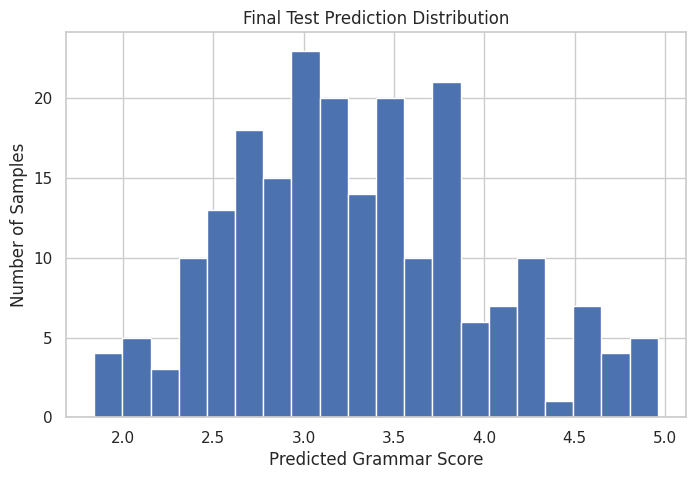

In [336]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    final_test_predictions,
    bins=20
)

plt.xlabel("Predicted Grammar Score")
plt.ylabel("Number of Samples")
plt.title("Final Test Prediction Distribution")

plt.show()

In [337]:
print("Sample submission shape:")
print(sample_submission.shape)

print("\nSample submission columns:")
print(sample_submission.columns.tolist())

print("\nTest shape:")
print(test_df.shape)

print("\nTest columns:")
print(test_df.columns.tolist())

Sample submission shape:
(204, 2)

Sample submission columns:
['filename', 'label']

Test shape:
(216, 33)

Test columns:
['filename', 'label', 'audio_path', 'transcript', 'word_count', 'char_count', 'conjunction_count', 'auxiliary_count', 'corrected_text', 'original_word_count', 'corrected_word_count', 'word_count_difference', 'correction_ratio', 'audio_duration', 'speech_duration', 'silence_duration', 'silence_ratio', 'words_per_minute', 'sentence_count', 'avg_sentence_length', 'max_sentence_length', 'vocabulary_diversity', 'repetition_ratio', 'pos_noun', 'pos_verb', 'pos_adj', 'pos_adv', 'pos_pron', 'pos_det', 'pos_adp', 'pos_cconj', 'pos_sconj', 'pos_aux']


In [338]:
prediction_map = dict(
    zip(
        test_df["filename"],
        final_test_predictions
    )
)

sample_filenames = sample_submission["filename"]

missing_sample_predictions = (
    sample_filenames
    .map(prediction_map)
    .isna()
)

print(
    "Sample rows:",
    len(sample_submission)
)

print(
    "Missing predictions:",
    missing_sample_predictions.sum()
)

Sample rows: 204
Missing predictions: 179


In [339]:
submission = sample_submission.copy()

submission["label"] = (
    submission["filename"]
    .map(prediction_map)
)

print("Submission shape:")
print(submission.shape)

print("\nMissing labels:")
print(submission["label"].isna().sum())

display(submission.head())

Submission shape:
(204, 2)

Missing labels:
179


,filename,label
0,audio_804.wav,NaN
1,audio_1028.wav,NaN
2,audio_865.wav,NaN
3,audio_774.wav,NaN
4,audio_1138.wav,NaN


In [340]:
print("========== SAMPLE SUBMISSION ==========")
print(sample_submission.head(10))
print("\nColumns:")
print(sample_submission.columns.tolist())

print("\n========== TEST DATA ==========")
print(test_df.head(10))
print("\nColumns:")
print(test_df.columns.tolist())

========== SAMPLE SUBMISSION ==========
         filename  label
0   audio_804.wav     -1
1  audio_1028.wav     -1
2   audio_865.wav     -1
3   audio_774.wav     -1
4  audio_1138.wav     -1
5   audio_278.wav     -1
6  audio_1212.wav     -1
7   audio_178.wav     -1
8   audio_542.wav     -1
9   audio_248.wav     -1

Columns:
['filename', 'label']

========== TEST DATA ==========
        filename  label                                         audio_path  \
0  audio_128.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...   
1  audio_156.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...   
2   audio_19.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...   
3  audio_108.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...   
4  audio_206.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...   
5  audio_161.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...   
6  audio_215.wav     -1  /kaggle/input/competitions/shl-hiring-assessme...

In [341]:
print("========== FILENAME COMPARISON ==========")

sample_names = set(
    sample_submission["filename"].astype(str)
)

test_names = set(
    test_df["filename"].astype(str)
)

print("Sample submission filenames:", len(sample_names))
print("Test filenames:", len(test_names))

print(
    "Common filenames:",
    len(sample_names.intersection(test_names))
)

print(
    "Sample-only filenames:",
    len(sample_names - test_names)
)

print(
    "Test-only filenames:",
    len(test_names - sample_names)
)

========== FILENAME COMPARISON ==========
Sample submission filenames: 204
Test filenames: 216
Common filenames: 25
Sample-only filenames: 179
Test-only filenames: 191


In [342]:
print("\n========== SAMPLE-ONLY EXAMPLES ==========")

print(
    list(sample_names - test_names)[:20]
)

print("\n========== TEST-ONLY EXAMPLES ==========")

print(
    list(test_names - sample_names)[:20]
)


========== SAMPLE-ONLY EXAMPLES ==========
['audio_818.wav', 'audio_681.wav', 'audio_327.wav', 'audio_415.wav', 'audio_1011.wav', 'audio_748.wav', 'audio_1006.wav', 'audio_1069.wav', 'audio_1270.wav', 'audio_940.wav', 'audio_218.wav', 'audio_1039.wav', 'audio_1055.wav', 'audio_709.wav', 'audio_952.wav', 'audio_505.wav', 'audio_981.wav', 'audio_668.wav', 'audio_749.wav', 'audio_1217.wav']

========== TEST-ONLY EXAMPLES ==========
['audio_114.wav', 'audio_189.wav', 'audio_205.wav', 'audio_29.wav', 'audio_52.wav', 'audio_129.wav', 'audio_164.wav', 'audio_141.wav', 'audio_119.wav', 'audio_44.wav', 'audio_111.wav', 'audio_158.wav', 'audio_175.wav', 'audio_105.wav', 'audio_145.wav', 'audio_7.wav', 'audio_64.wav', 'audio_180.wav', 'audio_98.wav', 'audio_25.wav']


In [343]:
# Check where the sample_submission filenames actually come from

sample_names = set(
    sample_submission["filename"].astype(str)
)

train_names = set(
    train_df["filename"].astype(str)
)

test_names = set(
    test_df["filename"].astype(str)
)

print("========== OVERLAP CHECK ==========")

print(
    "Sample ∩ Train:",
    len(sample_names.intersection(train_names))
)

print(
    "Sample ∩ Test:",
    len(sample_names.intersection(test_names))
)

print(
    "Sample filenames total:",
    len(sample_names)
)

print("\n========== EXAMPLES ==========")

print(
    "Sample + Train:",
    list(sample_names.intersection(train_names))[:20]
)

print(
    "Sample + Test:",
    list(sample_names.intersection(test_names))[:20]
)

========== OVERLAP CHECK ==========
Sample ∩ Train: 105
Sample ∩ Test: 25
Sample filenames total: 204

========== EXAMPLES ==========
Sample + Train: ['audio_681.wav', 'audio_327.wav', 'audio_14.wav', 'audio_415.wav', 'audio_748.wav', 'audio_218.wav', 'audio_709.wav', 'audio_505.wav', 'audio_668.wav', 'audio_749.wav', 'audio_128.wav', 'audio_376.wav', 'audio_550.wav', 'audio_27.wav', 'audio_234.wav', 'audio_153.wav', 'audio_249.wav', 'audio_686.wav', 'audio_236.wav', 'audio_531.wav']
Sample + Test: ['audio_171.wav', 'audio_67.wav', 'audio_14.wav', 'audio_72.wav', 'audio_188.wav', 'audio_89.wav', 'audio_178.wav', 'audio_200.wav', 'audio_33.wav', 'audio_117.wav', 'audio_130.wav', 'audio_128.wav', 'audio_41.wav', 'audio_57.wav', 'audio_13.wav', 'audio_168.wav', 'audio_27.wav', 'audio_153.wav', 'audio_47.wav', 'audio_99.wav']


In [344]:
print("========== DATASET RANGES ==========")

print("Train first 20 filenames:")
print(train_df["filename"].head(20).tolist())

print("\nTest first 20 filenames:")
print(test_df["filename"].head(20).tolist())

print("\nSample submission first 20 filenames:")
print(sample_submission["filename"].head(20).tolist())

========== DATASET RANGES ==========
Train first 20 filenames:
['audio_192.wav', 'audio_436.wav', 'audio_447.wav', 'audio_126.wav', 'audio_61.wav', 'audio_639.wav', 'audio_703.wav', 'audio_509.wav', 'audio_672.wav', 'audio_344.wav', 'audio_592.wav', 'audio_705.wav', 'audio_497.wav', 'audio_702.wav', 'audio_598.wav', 'audio_99.wav', 'audio_194.wav', 'audio_5055.wav', 'audio_178.wav', 'audio_609.wav']

Test first 20 filenames:
['audio_128.wav', 'audio_156.wav', 'audio_19.wav', 'audio_108.wav', 'audio_206.wav', 'audio_161.wav', 'audio_215.wav', 'audio_213.wav', 'audio_11.wav', 'audio_155.wav', 'audio_39.wav', 'audio_168.wav', 'audio_133.wav', 'audio_28.wav', 'audio_40.wav', 'audio_181.wav', 'audio_201.wav', 'audio_182.wav', 'audio_126.wav', 'audio_10.wav']

Sample submission first 20 filenames:
['audio_804.wav', 'audio_1028.wav', 'audio_865.wav', 'audio_774.wav', 'audio_1138.wav', 'audio_278.wav', 'audio_1212.wav', 'audio_178.wav', 'audio_542.wav', 'audio_248.wav', 'audio_872.wav', 'audio

In [345]:
import pandas as pd
from pathlib import Path

# Set DATA_DIR to search all inputs in Kaggle
DATA_DIR = Path("/kaggle/input")

# Find all WAV files inside the dataset recursively
all_wav_files = list(DATA_DIR.rglob("*.wav"))

print("Total WAV files found:", len(all_wav_files))

# Create filename -> path mapping
wav_map = {
    p.name: p
    for p in all_wav_files
}

# Ensure sample_submission is loaded
sample_submission = pd.read_csv(list(DATA_DIR.rglob("sample_submission.csv"))[0])
sample_names = sample_submission["filename"].astype(str)

# Check which sample submission files physically exist
existing_sample_files = [
    name for name in sample_names
    if name in wav_map
]

missing_sample_files = [
    name for name in sample_names
    if name not in wav_map
]

print("Sample filenames:", len(sample_names))
print("Audio files found:", len(existing_sample_files))
print("Audio files missing:", len(missing_sample_files))

print("\nFirst 20 existing:")
print(existing_sample_files[:20])

print("\nFirst 20 missing:")
print(missing_sample_files[:20])

Total WAV files found: 985
Sample filenames: 204
Audio files found: 105
Audio files missing: 99

First 20 existing:
['audio_774.wav', 'audio_278.wav', 'audio_178.wav', 'audio_542.wav', 'audio_248.wav', 'audio_171.wav', 'audio_748.wav', 'audio_284.wav', 'audio_200.wav', 'audio_80.wav', 'audio_256.wav', 'audio_301.wav', 'audio_664.wav', 'audio_89.wav', 'audio_407.wav', 'audio_72.wav', 'audio_661.wav', 'audio_501.wav', 'audio_188.wav', 'audio_746.wav']

First 20 missing:
['audio_804.wav', 'audio_1028.wav', 'audio_865.wav', 'audio_1138.wav', 'audio_1212.wav', 'audio_872.wav', 'audio_954.wav', 'audio_853.wav', 'audio_922.wav', 'audio_915.wav', 'audio_1220.wav', 'audio_1225.wav', 'audio_903.wav', 'audio_1255.wav', 'audio_1246.wav', 'audio_1102.wav', 'audio_1300.wav', 'audio_1041.wav', 'audio_328.wav', 'audio_938.wav']


In [346]:
# Create the actual competition submission from test.csv

submission = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": final_test_predictions
})

print("Submission shape:", submission.shape)

print("\nMissing labels:")
print(submission["label"].isna().sum())

print("\nFirst 10 rows:")
display(submission.head(10))

print("\nLast 10 rows:")
display(submission.tail(10))

Submission shape: (216, 2)

Missing labels:
0

First 10 rows:


,filename,label
0,audio_128.wav,3.301272
1,audio_156.wav,3.765108
2,audio_19.wav,4.228727
3,audio_108.wav,2.365388
4,audio_206.wav,2.825328
5,audio_161.wav,3.381974
6,audio_215.wav,3.119609
7,audio_213.wav,2.034887
8,audio_11.wav,3.532998
9,audio_155.wav,3.383247



Last 10 rows:


,filename,label
206,audio_20.wav,2.660792
207,audio_124.wav,3.760959
208,audio_54.wav,3.078558
209,audio_45.wav,4.774778
210,audio_71.wav,4.956991
211,audio_184.wav,2.337655
212,audio_24.wav,2.152905
213,audio_140.wav,2.931087
214,audio_165.wav,3.246201
215,audio_170.wav,3.001717


In [347]:
assert len(test_df) == 216
assert len(final_test_predictions) == 216
assert len(submission) == 216

assert submission["label"].isna().sum() == 0

assert submission["filename"].tolist() == (
    test_df["filename"].tolist()
)

assert submission["label"].between(
    1,
    5
).all()

print("✅ All submission checks passed!")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())

✅ All submission checks passed!
Rows: 216
Columns: ['filename', 'label']


In [348]:
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("✅ submission.csv created successfully!")
print("Path: /kaggle/working/submission.csv")

✅ submission.csv created successfully!
Path: /kaggle/working/submission.csv


In [349]:
import os

file_path = "/kaggle/working/submission.csv"

print("File exists:", os.path.exists(file_path))
print(
    "File size:",
    os.path.getsize(file_path),
    "bytes"
)

File exists: True
File size: 6898 bytes


In [350]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error

oof_df = pd.read_csv("/kaggle/working/oof_predictions.csv")

print("OOF shape:", oof_df.shape)
print("\nColumns:")
print(oof_df.columns.tolist())

print("\nMissing values:")
print(oof_df.isna().sum())

def evaluate_prediction(y_true, y_pred):
    y_pred = np.clip(y_pred, 1.0, 5.0)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    pearson = pearsonr(y_true, y_pred)[0]

    return rmse, pearson


models = ["ridge", "svr", "extratrees", "xgboost"]

for model in models:
    rmse, pearson = evaluate_prediction(
        oof_df["y_true"],
        oof_df[model]
    )

    print(f"{model:12s} | RMSE: {rmse:.4f} | Pearson: {pearson:.4f}")

OOF shape: (763, 5)

Columns:
['y_true', 'ridge', 'svr', 'extratrees', 'xgboost']

Missing values:
y_true        0
ridge         0
svr           0
extratrees    0
xgboost       0
dtype: int64
ridge        | RMSE: 0.7590 | Pearson: 0.7827
svr          | RMSE: 0.8184 | Pearson: 0.7510
extratrees   | RMSE: 0.7158 | Pearson: 0.8274
xgboost      | RMSE: 0.6573 | Pearson: 0.8492


In [351]:
residuals = pd.DataFrame()

for model in models:
    residuals[model] = (
        oof_df["y_true"] - oof_df[model]
    )

print("Residual correlation matrix:\n")
print(residuals.corr().round(3))

Residual correlation matrix:

            ridge    svr  extratrees  xgboost
ridge       1.000  0.982       0.478    0.547
svr         0.982  1.000       0.413    0.477
extratrees  0.478  0.413       1.000    0.931
xgboost     0.547  0.477       0.931    1.000


In [352]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X_meta = oof_df[
    ["ridge", "svr", "extratrees", "xgboost"]
].values

y_meta = oof_df["y_true"].values

meta_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

meta_model.fit(X_meta, y_meta)

oof_stack_pred = meta_model.predict(X_meta)

oof_stack_pred = np.clip(
    oof_stack_pred,
    1.0,
    5.0
)

stack_rmse, stack_pearson = evaluate_prediction(
    y_meta,
    oof_stack_pred
)

print("Stacking OOF Results")
print("--------------------")
print(f"RMSE    : {stack_rmse:.4f}")
print(f"Pearson : {stack_pearson:.4f}")

Stacking OOF Results
--------------------
RMSE    : 0.6350
Pearson : 0.8591


In [353]:
meta_ridge = meta_model.named_steps["ridge"]

print("Meta-model coefficients:")

for name, coef in zip(models, meta_ridge.coef_):
    print(f"{name:12s}: {coef:.6f}")

print(f"\nIntercept: {meta_ridge.intercept_:.6f}")

Meta-model coefficients:
ridge       : 0.144147
svr         : 0.142798
extratrees  : 0.109091
xgboost     : 0.681439

Intercept: 3.339450


In [354]:
comparison = []

for model in models:

    rmse, pearson = evaluate_prediction(
        oof_df["y_true"],
        oof_df[model]
    )

    comparison.append({
        "Model": model,
        "RMSE": rmse,
        "Pearson": pearson
    })

comparison.append({
    "Model": "Stacking",
    "RMSE": stack_rmse,
    "Pearson": stack_pearson
})

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

print(comparison_df.round(4))

        Model    RMSE  Pearson
0    Stacking  0.6350   0.8591
1     xgboost  0.6573   0.8492
2  extratrees  0.7158   0.8274
3       ridge  0.7590   0.7827
4         svr  0.8184   0.7510


In [355]:
from sklearn.linear_model import Ridge

calibrated_oof_pred = np.zeros(len(meta_target))

for fold, (train_idx, val_idx) in enumerate(meta_kf.split(meta_oof_pred)):

    # Train calibration only on training portion
    calibration_model = Ridge(alpha=1.0)

    calibration_model.fit(
        meta_oof_pred[train_idx].reshape(-1, 1),
        meta_target[train_idx]
    )

    calibrated_oof_pred[val_idx] = calibration_model.predict(
        meta_oof_pred[val_idx].reshape(-1, 1)
    )

calibrated_oof_pred = np.clip(
    calibrated_oof_pred,
    1.0,
    5.0
)

calibrated_rmse, calibrated_pearson = evaluate_prediction(
    meta_target,
    calibrated_oof_pred
)

print("Calibrated Stacking")
print("-------------------")
print(f"RMSE    : {calibrated_rmse:.4f}")
print(f"Pearson : {calibrated_pearson:.4f}")

NameError: name 'meta_target' is not defined

In [ ]:
comparison_part10 = []

for model in models:

    rmse, pearson = evaluate_prediction(
        oof_df["y_true"],
        oof_df[model]
    )

    comparison_part10.append({
        "Model": model,
        "RMSE": rmse,
        "Pearson": pearson
    })

comparison_part10.append({
    "Model": "Stacking",
    "RMSE": meta_cv_rmse,
    "Pearson": meta_cv_pearson
})

comparison_part10.append({
    "Model": "Calibrated Stacking",
    "RMSE": calibrated_rmse,
    "Pearson": calibrated_pearson
})

comparison_part10 = pd.DataFrame(
    comparison_part10
).sort_values(
    "RMSE"
).reset_index(drop=True)

print(comparison_part10.round(4))

In [ ]:
print("Actual labels")
print("-------------")
print(f"Mean : {meta_target.mean():.4f}")
print(f"Std  : {meta_target.std():.4f}")
print(f"Min  : {meta_target.min():.4f}")
print(f"Max  : {meta_target.max():.4f}")

print("\nStacking predictions")
print("--------------------")
print(f"Mean : {meta_oof_pred.mean():.4f}")
print(f"Std  : {meta_oof_pred.std():.4f}")
print(f"Min  : {meta_oof_pred.min():.4f}")
print(f"Max  : {meta_oof_pred.max():.4f}")

print("\nCalibrated predictions")
print("----------------------")
print(f"Mean : {calibrated_oof_pred.mean():.4f}")
print(f"Std  : {calibrated_oof_pred.std():.4f}")
print(f"Min  : {calibrated_oof_pred.min():.4f}")
print(f"Max  : {calibrated_oof_pred.max():.4f}")

In [ ]:
# Create test-level meta features

test_meta_features = np.column_stack([
    ridge_test_pred,
    svr_test_pred,
    extra_test_pred,
    xgb_test_pred
])

print("Test meta feature shape:")
print(test_meta_features.shape)

# Train final meta-model on all OOF predictions

final_meta_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

final_meta_model.fit(
    meta_features,
    meta_target
)

# Predict test set

stack_test_pred = final_meta_model.predict(
    test_meta_features
)

stack_test_pred = np.clip(
    stack_test_pred,
    1.0,
    5.0
)

print("\nStacking test prediction shape:")
print(stack_test_pred.shape)

print("\nPrediction statistics:")
print("Mean:", stack_test_pred.mean())
print("Std :", stack_test_pred.std())
print("Min :", stack_test_pred.min())
print("Max :", stack_test_pred.max())

In [ ]:
final_calibration_model = Ridge(alpha=1.0)

final_calibration_model.fit(
    meta_oof_pred.reshape(-1, 1),
    meta_target
)

calibrated_test_pred = final_calibration_model.predict(
    stack_test_pred.reshape(-1, 1)
)

calibrated_test_pred = np.clip(
    calibrated_test_pred,
    1.0,
    5.0
)

print("Calibrated test prediction shape:")
print(calibrated_test_pred.shape)

print("\nPrediction statistics:")
print("Mean:", calibrated_test_pred.mean())
print("Std :", calibrated_test_pred.std())
print("Min :", calibrated_test_pred.min())
print("Max :", calibrated_test_pred.max())

In [ ]:
final_comparison = []

# Individual models
for model in models:
    rmse, pearson = evaluate_prediction(
        oof_df["y_true"],
        oof_df[model]
    )

    final_comparison.append({
        "Candidate": model,
        "RMSE": rmse,
        "Pearson": pearson
    })

# Leakage-safe stacking
final_comparison.append({
    "Candidate": "Stacking",
    "RMSE": meta_cv_rmse,
    "Pearson": meta_cv_pearson
})

# Leakage-safe calibrated stacking
final_comparison.append({
    "Candidate": "Calibrated Stacking",
    "RMSE": calibrated_rmse,
    "Pearson": calibrated_pearson
})

final_comparison_df = pd.DataFrame(
    final_comparison
).sort_values(
    by="RMSE"
).reset_index(drop=True)

print(final_comparison_df.round(4))

In [ ]:
candidate_predictions = {
    "Original Blend": final_test_predictions,
    "Stacking": stack_test_pred,
    "Calibrated Stacking": calibrated_test_pred
}

distribution_rows = []

for name, pred in candidate_predictions.items():

    distribution_rows.append({
        "Candidate": name,
        "Mean": np.mean(pred),
        "Std": np.std(pred),
        "Min": np.min(pred),
        "Max": np.max(pred),
        "Median": np.median(pred)
    })

distribution_df = pd.DataFrame(distribution_rows)

print(distribution_df.round(4))

In [ ]:
# Candidate 1: Original optimized blend
submission_original = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": final_test_predictions
})

# Candidate 2: Stacking
submission_stacking = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": stack_test_pred
})

# Candidate 3: Calibrated stacking
submission_calibrated = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": calibrated_test_pred
})

# Clip all predictions to valid 1-5 range
submission_original["label"] = np.clip(
    submission_original["label"], 1, 5
)

submission_stacking["label"] = np.clip(
    submission_stacking["label"], 1, 5
)

submission_calibrated["label"] = np.clip(
    submission_calibrated["label"], 1, 5
)

print("Original:", submission_original.shape)
print("Stacking:", submission_stacking.shape)
print("Calibrated:", submission_calibrated.shape)

In [ ]:
submissions = {
    "original": submission_original,
    "stacking": submission_stacking,
    "calibrated": submission_calibrated
}

for name, sub in submissions.items():

    assert len(sub) == len(test_df), \
        f"{name}: wrong number of rows"

    assert list(sub.columns) == ["filename", "label"], \
        f"{name}: wrong columns"

    assert sub["filename"].tolist() == test_df["filename"].tolist(), \
        f"{name}: filename order mismatch"

    assert sub["filename"].isna().sum() == 0, \
        f"{name}: missing filename"

    assert sub["label"].isna().sum() == 0, \
        f"{name}: missing prediction"

    assert sub["filename"].duplicated().sum() == 0, \
        f"{name}: duplicate filenames"

    assert sub["label"].between(1, 5).all(), \
        f"{name}: prediction outside 1-5"

print("✅ All three submissions passed validation.")

In [ ]:
submission_original.to_csv(
    "/kaggle/working/submission_original_blend.csv",
    index=False
)

submission_stacking.to_csv(
    "/kaggle/working/submission_stacking.csv",
    index=False
)

submission_calibrated.to_csv(
    "/kaggle/working/submission_calibrated_stacking.csv",
    index=False
)

print("Files saved:")
print("/kaggle/working/submission_original_blend.csv")
print("/kaggle/working/submission_stacking.csv")
print("/kaggle/working/submission_calibrated_stacking.csv")

In [ ]:
print("Original Blend")
display(submission_original.head(10))

print("\nStacking")
display(submission_stacking.head(10))

print("\nCalibrated Stacking")
display(submission_calibrated.head(10))

In [ ]:
# --------------------------------------------------
# PART 12.1
# Reconstruct feature groups
# --------------------------------------------------

# 1. Basic handcrafted features
X_hand = model_df[handcrafted_cols].copy()
X_test_hand = test_df[handcrafted_cols].copy()


# 2. Advanced audio features
X_adv_audio = advanced_train_audio_df.copy()
X_test_adv_audio = advanced_test_audio_df.copy()


# 3. MiniLM text embeddings
X_minilm = pd.DataFrame(
    embeddings,
    index=model_df.index
)

X_test_minilm = pd.DataFrame(
    test_embeddings,
    index=test_df.index
)


# 4. Wav2Vec2 embeddings
X_wav2vec = pd.DataFrame(
    train_wav2vec_embeddings,
    index=model_df.index
)

X_test_wav2vec = pd.DataFrame(
    test_wav2vec_embeddings,
    index=test_df.index
)


# 5. Advanced grammar features
X_adv_grammar = advanced_grammar_train_df.copy()
X_test_adv_grammar = advanced_grammar_test_df.copy()


# 6. Linguistic complexity + perplexity
X_complexity = train_complexity_df.copy()
X_test_complexity = test_complexity_df.copy()


# --------------------------------------------------
# Convert everything to numeric
# --------------------------------------------------

feature_groups = {
    "handcrafted": X_hand,
    "advanced_audio": X_adv_audio,
    "minilm": X_minilm,
    "wav2vec": X_wav2vec,
    "advanced_grammar": X_adv_grammar,
    "complexity": X_complexity
}

test_feature_groups = {
    "handcrafted": X_test_hand,
    "advanced_audio": X_test_adv_audio,
    "minilm": X_test_minilm,
    "wav2vec": X_test_wav2vec,
    "advanced_grammar": X_test_adv_grammar,
    "complexity": X_test_complexity
}

for name in feature_groups:

    feature_groups[name] = (
        feature_groups[name]
        .apply(pd.to_numeric, errors="coerce")
        .reset_index(drop=True)
    )

    test_feature_groups[name] = (
        test_feature_groups[name]
        .apply(pd.to_numeric, errors="coerce")
        .reset_index(drop=True)
    )


# Target
y_feature = model_df["label"].astype(float).reset_index(drop=True).values


print("Feature group sizes:")
print("--------------------")

for name, df in feature_groups.items():
    print(f"{name:20s}: {df.shape}")

print("\nTarget shape:", y_feature.shape)

In [ ]:
X_perplexity = pd.DataFrame({
    "perplexity": train_perplexity
})

X_test_perplexity = pd.DataFrame({
    "perplexity": test_perplexity
})

print("Perplexity train shape :", X_perplexity.shape)
print("Perplexity test shape  :", X_test_perplexity.shape)

In [ ]:
all_groups = {
    **feature_groups,
    "perplexity": X_perplexity
}

for name, df in all_groups.items():

    nan_count = df.isna().sum().sum()
    inf_count = np.isinf(df.to_numpy()).sum()

    print(
        f"{name:20s} | "
        f"NaN: {nan_count:5d} | "
        f"Inf: {inf_count:5d}"
    )

In [ ]:
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np
import pandas as pd


def evaluate_group_cv(X, y, alpha=10.0):

    X = X.replace([np.inf, -np.inf], np.nan)

    kf_group = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    oof_pred = np.zeros(len(y))

    for train_idx, val_idx in kf_group.split(X):

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        model.fit(
            X.iloc[train_idx],
            y[train_idx]
        )

        oof_pred[val_idx] = model.predict(
            X.iloc[val_idx]
        )

    oof_pred = np.clip(oof_pred, 1.0, 5.0)

    rmse = np.sqrt(
        mean_squared_error(y, oof_pred)
    )

    pearson = pearsonr(
        y,
        oof_pred
    )[0]

    return rmse, pearson, oof_pred


group_results = []

for name, X_group in all_groups.items():

    rmse, pearson, _ = evaluate_group_cv(
        X_group,
        y_feature
    )

    group_results.append({
        "Feature_Group": name,
        "Features": X_group.shape[1],
        "RMSE": rmse,
        "Pearson": pearson
    })


group_results_df = pd.DataFrame(
    group_results
).sort_values(
    "RMSE"
).reset_index(drop=True)

print(group_results_df.round(4))

In [ ]:
# --------------------------------------------------
# PART 12.5 — FIXED
# Test cumulative feature combinations
# --------------------------------------------------

combination_definitions = {

    "handcrafted":
        ["handcrafted"],

    "handcrafted+grammar":
        ["handcrafted", "advanced_grammar"],

    "handcrafted+audio":
        ["handcrafted", "advanced_audio"],

    "handcrafted+complexity":
        ["handcrafted", "complexity", "perplexity"],

    "handcrafted+minilm":
        ["handcrafted", "minilm"],

    "handcrafted+wav2vec":
        ["handcrafted", "wav2vec"],

    "text_all":
        [
            "handcrafted",
            "advanced_grammar",
            "complexity",
            "perplexity",
            "minilm"
        ],

    "audio_all":
        [
            "handcrafted",
            "advanced_audio",
            "wav2vec"
        ],

    "everything_except_wav2vec":
        [
            "handcrafted",
            "advanced_audio",
            "minilm",
            "advanced_grammar",
            "complexity",
            "perplexity"
        ],

    "everything":
        [
            "handcrafted",
            "advanced_audio",
            "minilm",
            "wav2vec",
            "advanced_grammar",
            "complexity",
            "perplexity"
        ]
}


combination_results = []

for combination_name, groups in combination_definitions.items():

    # Combine selected feature groups
    X_combined = pd.concat(
        [all_groups[g] for g in groups],
        axis=1
    ).copy()

    # IMPORTANT:
    # MiniLM/Wav2Vec2 have integer column names,
    # while other feature groups have string names.
    # Convert ALL column names to strings.
    X_combined.columns = X_combined.columns.astype(str)

    # Replace infinite values
    X_combined = X_combined.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Make sure everything is numeric
    X_combined = X_combined.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Evaluate with 5-fold CV
    rmse, pearson, _ = evaluate_group_cv(
        X_combined,
        y_feature
    )

    combination_results.append({
        "Combination": combination_name,
        "Features": X_combined.shape[1],
        "RMSE": rmse,
        "Pearson": pearson
    })

    print(
        f"{combination_name:30s} | "
        f"Features: {X_combined.shape[1]:4d} | "
        f"RMSE: {rmse:.4f} | "
        f"Pearson: {pearson:.4f}"
    )


combination_results_df = pd.DataFrame(
    combination_results
).sort_values(
    by="RMSE"
).reset_index(drop=True)

print("\n==============================")
print("FINAL FEATURE COMBINATION RANKING")
print("==============================\n")

print(combination_results_df.round(4))

In [ ]:
group_results_df.to_csv(
    "/kaggle/working/feature_group_results.csv",
    index=False
)

combination_results_df.to_csv(
    "/kaggle/working/feature_combination_results.csv",
    index=False
)

print("Saved:")
print("/kaggle/working/feature_group_results.csv")
print("/kaggle/working/feature_combination_results.csv")

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np
import pandas as pd


# --------------------------------------------------
# Select the best feature combination from Part 12
# --------------------------------------------------

best_combination_name = combination_results_df.iloc[0]["Combination"]

print("Best feature combination from Part 12:")
print(best_combination_name)


# Get groups belonging to the winning combination
selected_groups = combination_definitions[
    best_combination_name
]

print("\nGroups used:")
print(selected_groups)


# Combine selected groups
X_selected = pd.concat(
    [all_groups[g] for g in selected_groups],
    axis=1
).copy()


# --------------------------------------------------
# Clean feature matrix
# --------------------------------------------------

X_selected = X_selected.replace(
    [np.inf, -np.inf],
    np.nan
)

X_selected = X_selected.apply(
    pd.to_numeric,
    errors="coerce"
)

# VERY IMPORTANT
# Prevent int/string feature-name error
X_selected.columns = X_selected.columns.astype(str)

print("\nFeature matrix shape:")
print(X_selected.shape)

In [ ]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

n_features = X_selected.shape[1]

candidate_k = [
    25,
    50,
    100,
    200,
    300,
    500,
    800,
    1000,
    1500
]

candidate_k = [
    k for k in candidate_k
    if k <= n_features
]

k_results = []

for k in candidate_k:

    oof_pred = np.zeros(len(y_feature))

    for train_idx, val_idx in kf.split(X_selected):

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "scaler",
                StandardScaler()
            ),

            (
                "selector",
                SelectKBest(
                    score_func=f_regression,
                    k=k
                )
            ),

            (
                "ridge",
                Ridge(alpha=10.0)
            )
        ])

        model.fit(
            X_selected.iloc[train_idx],
            y_feature[train_idx]
        )

        oof_pred[val_idx] = model.predict(
            X_selected.iloc[val_idx]
        )

    oof_pred = np.clip(
        oof_pred,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            oof_pred
        )
    )

    pearson = pearsonr(
        y_feature,
        oof_pred
    )[0]

    k_results.append({
        "K": k,
        "RMSE": rmse,
        "Pearson": pearson
    })

    print(
        f"K={k:4d} | "
        f"RMSE={rmse:.4f} | "
        f"Pearson={pearson:.4f}"
    )


k_results_df = pd.DataFrame(
    k_results
).sort_values(
    "RMSE"
).reset_index(drop=True)

print("\n==============================")
print("SELECTKBEST RESULTS")
print("==============================")

print(k_results_df.round(4))

In [ ]:
best_k_row = k_results_df.iloc[0]

best_k = int(best_k_row["K"])
best_k_rmse = float(best_k_row["RMSE"])
best_k_pearson = float(best_k_row["Pearson"])

print("Best K:", best_k)
print(f"Best RMSE: {best_k_rmse:.4f}")
print(f"Best Pearson: {best_k_pearson:.4f}")

In [ ]:
full_rmse, full_pearson, _ = evaluate_group_cv(
    X_selected,
    y_feature
)

print("Feature Selection Comparison")
print("----------------------------")

print(
    f"Full features ({X_selected.shape[1]}): "
    f"RMSE={full_rmse:.4f}, "
    f"Pearson={full_pearson:.4f}"
)

print(
    f"SelectKBest ({best_k}): "
    f"RMSE={best_k_rmse:.4f}, "
    f"Pearson={best_k_pearson:.4f}"
)

print("\nRMSE improvement:")

improvement = full_rmse - best_k_rmse

print(f"{improvement:.4f}")

In [ ]:
k_results_df.to_csv(
    "/kaggle/working/selectkbest_results.csv",
    index=False
)

print(
    "Saved: /kaggle/working/selectkbest_results.csv"
)

In [ ]:
# --------------------------------------------------
# PART 14.1
# Prepare winning feature combination
# --------------------------------------------------

print("Winning feature combination:")
print(best_combination_name)

print("\nSelected groups:")
print(selected_groups)

print("\nBest K:")
print(best_k)


# Build training matrix
X_final_selected = pd.concat(
    [all_groups[g] for g in selected_groups],
    axis=1
).copy()


# Build test matrix
X_test_final_selected = pd.concat(
    [test_feature_groups[g] for g in selected_groups],
    axis=1
).copy()


# Add perplexity if it was selected
if "perplexity" in selected_groups:

    # It may already be present in all_groups
    pass


# Clean values
X_final_selected = X_final_selected.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test_final_selected = X_test_final_selected.replace(
    [np.inf, -np.inf],
    np.nan
)


# Convert everything to numeric
X_final_selected = X_final_selected.apply(
    pd.to_numeric,
    errors="coerce"
)

X_test_final_selected = X_test_final_selected.apply(
    pd.to_numeric,
    errors="coerce"
)


# Fix mixed feature-name types
X_final_selected.columns = (
    X_final_selected.columns.astype(str)
)

X_test_final_selected.columns = (
    X_test_final_selected.columns.astype(str)
)


print("\nTraining shape:")
print(X_final_selected.shape)

print("\nTest shape:")
print(X_test_final_selected.shape)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np


def run_selected_ridge_cv(
    X,
    y,
    k,
    alpha
):

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    oof_pred = np.zeros(len(y))

    for train_idx, val_idx in kf.split(X):

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "scaler",
                StandardScaler()
            ),

            (
                "selector",
                SelectKBest(
                    score_func=f_regression,
                    k=k
                )
            ),

            (
                "ridge",
                Ridge(alpha=alpha)
            )
        ])

        model.fit(
            X.iloc[train_idx],
            y[train_idx]
        )

        oof_pred[val_idx] = model.predict(
            X.iloc[val_idx]
        )

    oof_pred = np.clip(
        oof_pred,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(y, oof_pred)
    )

    pearson = pearsonr(
        y,
        oof_pred
    )[0]

    return rmse, pearson, oof_pred

In [ ]:
alpha_values = [
    0.1,
    0.5,
    1.0,
    2.0,
    5.0,
    10.0,
    20.0,
    50.0,
    100.0
]

ridge_tuning_results = []

for alpha in alpha_values:

    rmse, pearson, _ = run_selected_ridge_cv(
        X_final_selected,
        y_feature,
        best_k,
        alpha
    )

    ridge_tuning_results.append({
        "alpha": alpha,
        "RMSE": rmse,
        "Pearson": pearson
    })

    print(
        f"alpha={alpha:6.1f} | "
        f"RMSE={rmse:.4f} | "
        f"Pearson={pearson:.4f}"
    )


ridge_tuning_df = pd.DataFrame(
    ridge_tuning_results
).sort_values(
    "RMSE"
).reset_index(drop=True)

print("\nRidge tuning results:")
print(ridge_tuning_df.round(4))

In [ ]:
best_ridge_row = ridge_tuning_df.iloc[0]

best_ridge_alpha = float(
    best_ridge_row["alpha"]
)

best_ridge_rmse = float(
    best_ridge_row["RMSE"]
)

best_ridge_pearson = float(
    best_ridge_row["Pearson"]
)

print("Best Ridge configuration")
print("------------------------")
print("K     :", best_k)
print("Alpha :", best_ridge_alpha)
print(f"RMSE  : {best_ridge_rmse:.4f}")
print(f"Pearson: {best_ridge_pearson:.4f}")

In [ ]:
print("====================================")
print("OLD vs NEW")
print("====================================")

print(
    f"Selected Ridge RMSE : "
    f"{best_ridge_rmse:.4f}"
)

print(
    f"Selected Ridge Pearson : "
    f"{best_ridge_pearson:.4f}"
)

print("\nYour previous OOF model results:")
print(results.round(4))

In [ ]:
final_selected_ridge = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "selector",
        SelectKBest(
            score_func=f_regression,
            k=best_k
        )
    ),

    (
        "ridge",
        Ridge(alpha=best_ridge_alpha)
    )
])


final_selected_ridge.fit(
    X_final_selected,
    y_feature
)

print("✅ Final selected Ridge trained.")

In [ ]:
selected_ridge_test_pred = final_selected_ridge.predict(
    X_test_final_selected
)

selected_ridge_test_pred = np.clip(
    selected_ridge_test_pred,
    1.0,
    5.0
)

print("Prediction shape:")
print(selected_ridge_test_pred.shape)

print("\nPrediction statistics:")
print(
    "Mean:",
    selected_ridge_test_pred.mean()
)

print(
    "Std :",
    selected_ridge_test_pred.std()
)

print(
    "Min :",
    selected_ridge_test_pred.min()
)

print(
    "Max :",
    selected_ridge_test_pred.max()
)

In [ ]:
submission_selected_ridge = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": selected_ridge_test_pred
})

submission_selected_ridge["label"] = np.clip(
    submission_selected_ridge["label"],
    1.0,
    5.0
)

print(submission_selected_ridge.shape)

display(
    submission_selected_ridge.head(10)
)

In [ ]:
assert len(submission_selected_ridge) == 216

assert list(
    submission_selected_ridge.columns
) == ["filename", "label"]

assert (
    submission_selected_ridge["filename"].tolist()
    == test_df["filename"].tolist()
)

assert (
    submission_selected_ridge["filename"]
    .duplicated()
    .sum()
    == 0
)

assert (
    submission_selected_ridge["label"]
    .isna()
    .sum()
    == 0
)

assert (
    submission_selected_ridge["label"]
    .between(1, 5)
    .all()
)

print("================================")
print("✅ SUBMISSION VALIDATION PASSED")
print("================================")
print("Rows:", len(submission_selected_ridge))
print("Missing labels:",
      submission_selected_ridge["label"].isna().sum())
print("Min label:",
      submission_selected_ridge["label"].min())
print("Max label:",
      submission_selected_ridge["label"].max())

In [ ]:
submission_selected_ridge.to_csv(
    "/kaggle/working/submission_selected_ridge.csv",
    index=False
)

ridge_tuning_df.to_csv(
    "/kaggle/working/ridge_alpha_tuning.csv",
    index=False
)

print("Saved:")
print("/kaggle/working/submission_selected_ridge.csv")
print("/kaggle/working/ridge_alpha_tuning.csv")

In [ ]:
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np
import pandas as pd


kf_final = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

selected_ridge_oof = np.zeros(len(y_feature))


for fold, (train_idx, val_idx) in enumerate(
    kf_final.split(X_final_selected)
):

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "selector",
            SelectKBest(
                score_func=f_regression,
                k=best_k
            )
        ),

        (
            "ridge",
            Ridge(alpha=best_ridge_alpha)
        )
    ])

    model.fit(
        X_final_selected.iloc[train_idx],
        y_feature[train_idx]
    )

    selected_ridge_oof[val_idx] = model.predict(
        X_final_selected.iloc[val_idx]
    )


selected_ridge_oof = np.clip(
    selected_ridge_oof,
    1.0,
    5.0
)


selected_ridge_oof_rmse = np.sqrt(
    mean_squared_error(
        y_feature,
        selected_ridge_oof
    )
)

selected_ridge_oof_pearson = pearsonr(
    y_feature,
    selected_ridge_oof
)[0]


print("Selected Ridge OOF")
print("------------------")
print(
    f"RMSE    : {selected_ridge_oof_rmse:.4f}"
)
print(
    f"Pearson : {selected_ridge_oof_pearson:.4f}"
)

In [ ]:
ensemble_oof = pd.DataFrame({
    "ridge": ridge_oof,
    "svr": svr_oof,
    "extratrees": extra_oof,
    "xgboost": xgb_oof,
    "selected_ridge": selected_ridge_oof
})

print("OOF ensemble matrix:")
print(ensemble_oof.shape)

print("\nMissing values:")
print(ensemble_oof.isna().sum())

In [ ]:
ensemble_results = []

for model_name in ensemble_oof.columns:

    pred = ensemble_oof[model_name].values

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            pred
        )
    )

    pearson = pearsonr(
        y_feature,
        pred
    )[0]

    ensemble_results.append({
        "Model": model_name,
        "RMSE": rmse,
        "Pearson": pearson
    })


ensemble_results_df = pd.DataFrame(
    ensemble_results
).sort_values(
    "RMSE"
).reset_index(drop=True)


print(
    ensemble_results_df.round(4)
)

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np


prediction_matrix = ensemble_oof.values

rng = np.random.default_rng(42)

n_trials = 20000

best_rmse = np.inf
best_weights = None
best_ensemble_pred = None
best_pearson = None


for _ in range(n_trials):

    # Generate non-negative weights
    weights = rng.dirichlet(
        np.ones(prediction_matrix.shape[1])
    )

    # Weighted prediction
    pred = prediction_matrix @ weights

    pred = np.clip(
        pred,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            pred
        )
    )

    if rmse < best_rmse:

        best_rmse = rmse
        best_weights = weights.copy()
        best_ensemble_pred = pred.copy()

        best_pearson = pearsonr(
            y_feature,
            pred
        )[0]


print("Best ensemble")
print("-------------")

for name, weight in zip(
    ensemble_oof.columns,
    best_weights
):
    print(
        f"{name:20s}: {weight:.4f}"
    )

print(
    f"\nRMSE    : {best_rmse:.4f}"
)

print(
    f"Pearson : {best_pearson:.4f}"
)

print(
    f"\nWeight sum: {best_weights.sum():.6f}"
)

In [ ]:
comparison_15 = ensemble_results_df.copy()

comparison_15 = pd.concat([
    comparison_15,
    pd.DataFrame([{
        "Model": "Optimized Ensemble",
        "RMSE": best_rmse,
        "Pearson": best_pearson
    }])
], ignore_index=True)

comparison_15 = comparison_15.sort_values(
    "RMSE"
).reset_index(drop=True)


print(
    comparison_15.round(4)
)

In [ ]:
# Existing final model predictions

ensemble_test_matrix = np.column_stack([
    ridge_test_pred,
    svr_test_pred,
    extra_test_pred,
    xgb_test_pred,
    selected_ridge_test_pred
])


print("Test prediction matrix:")
print(ensemble_test_matrix.shape)


# Apply optimized weights
optimized_test_pred = (
    ensemble_test_matrix @ best_weights
)


# Keep predictions within valid grammar score range
optimized_test_pred = np.clip(
    optimized_test_pred,
    1.0,
    5.0
)


print("\nOptimized test prediction shape:")
print(optimized_test_pred.shape)

print("\nPrediction statistics:")
print(
    "Mean:",
    optimized_test_pred.mean()
)

print(
    "Std :",
    optimized_test_pred.std()
)

print(
    "Min :",
    optimized_test_pred.min()
)

print(
    "Max :",
    optimized_test_pred.max()
)

In [ ]:
submission_optimized = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": optimized_test_pred
})


submission_optimized["label"] = np.clip(
    submission_optimized["label"],
    1.0,
    5.0
)


print("Submission shape:")
print(submission_optimized.shape)

display(
    submission_optimized.head(10)
)

In [ ]:
assert len(submission_optimized) == 216

assert list(
    submission_optimized.columns
) == ["filename", "label"]

assert (
    submission_optimized["filename"].tolist()
    == test_df["filename"].tolist()
)

assert (
    submission_optimized["filename"]
    .duplicated()
    .sum()
    == 0
)

assert (
    submission_optimized["label"]
    .isna()
    .sum()
    == 0
)

assert (
    submission_optimized["label"]
    .between(1, 5)
    .all()
)


print("====================================")
print("✅ OPTIMIZED SUBMISSION VALID")
print("====================================")

print("Rows:", len(submission_optimized))
print(
    "Missing labels:",
    submission_optimized["label"].isna().sum()
)
print(
    "Prediction range:",
    submission_optimized["label"].min(),
    "→",
    submission_optimized["label"].max()
)

In [ ]:
submission_optimized.to_csv(
    "/kaggle/working/submission_optimized_ensemble.csv",
    index=False
)

ensemble_results_df.to_csv(
    "/kaggle/working/final_ensemble_models.csv",
    index=False
)

comparison_15.to_csv(
    "/kaggle/working/final_ensemble_comparison.csv",
    index=False
)

np.save(
    "/kaggle/working/optimized_ensemble_weights.npy",
    best_weights
)

print("Saved files:")
print("------------------------------------------")
print("submission_optimized_ensemble.csv")
print("final_ensemble_models.csv")
print("final_ensemble_comparison.csv")
print("optimized_ensemble_weights.npy")

In [ ]:
# --------------------------------------------------
# PART 16.1
# OOF Error Analysis
# --------------------------------------------------

error_df = pd.DataFrame({
    "actual": y_feature,
    "prediction": best_ensemble_pred
})

error_df["error"] = (
    error_df["prediction"] -
    error_df["actual"]
)

error_df["absolute_error"] = (
    error_df["error"].abs()
)

error_df["squared_error"] = (
    error_df["error"] ** 2
)

print(error_df.head(10))

print("\nOverall statistics:")
print(
    error_df[
        [
            "actual",
            "prediction",
            "error",
            "absolute_error"
        ]
    ].describe().round(4)
)

In [ ]:
mean_error = error_df["error"].mean()
median_error = error_df["error"].median()

print("Prediction Bias")
print("----------------")
print(f"Mean error   : {mean_error:.4f}")
print(f"Median error : {median_error:.4f}")

if mean_error > 0:
    print("\nModel is generally OVER-PREDICTING.")
elif mean_error < 0:
    print("\nModel is generally UNDER-PREDICTING.")
else:
    print("\nModel has almost zero average bias.")

In [ ]:
error_df["score_range"] = pd.cut(
    error_df["actual"],
    bins=[0, 2, 3, 4, 5],
    labels=[
        "1-2",
        "2-3",
        "3-4",
        "4-5"
    ],
    include_lowest=True
)

range_results = []

for score_range, group in error_df.groupby(
    "score_range",
    observed=False
):

    if len(group) == 0:
        continue

    rmse = np.sqrt(
        np.mean(
            group["squared_error"]
        )
    )

    mae = group["absolute_error"].mean()

    bias = group["error"].mean()

    range_results.append({
        "Score_Range": score_range,
        "Samples": len(group),
        "RMSE": rmse,
        "MAE": mae,
        "Bias": bias
    })

range_results_df = pd.DataFrame(
    range_results
)

print(
    range_results_df.round(4)
)

In [ ]:
print("Distribution comparison")
print("----------------------")

print(
    f"Actual mean : "
    f"{y_feature.mean():.4f}"
)

print(
    f"Pred mean   : "
    f"{best_ensemble_pred.mean():.4f}"
)

print(
    f"\nActual std  : "
    f"{y_feature.std():.4f}"
)

print(
    f"Pred std    : "
    f"{best_ensemble_pred.std():.4f}"
)

print(
    f"\nActual min  : "
    f"{y_feature.min():.4f}"
)

print(
    f"Pred min    : "
    f"{best_ensemble_pred.min():.4f}"
)

print(
    f"\nActual max  : "
    f"{y_feature.max():.4f}"
)

print(
    f"Pred max    : "
    f"{best_ensemble_pred.max():.4f}"
)

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np

calibration_kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

calibrated_oof = np.zeros(
    len(y_feature)
)

for train_idx, val_idx in calibration_kf.split(
    best_ensemble_pred
):

    calibration_model = Ridge(
        alpha=1.0
    )

    calibration_model.fit(
        best_ensemble_pred[
            train_idx
        ].reshape(-1, 1),

        y_feature[
            train_idx
        ]
    )

    calibrated_oof[val_idx] = (
        calibration_model.predict(
            best_ensemble_pred[
                val_idx
            ].reshape(-1, 1)
        )
    )


calibrated_oof = np.clip(
    calibrated_oof,
    1.0,
    5.0
)


calibrated_rmse = np.sqrt(
    mean_squared_error(
        y_feature,
        calibrated_oof
    )
)

calibrated_pearson = pearsonr(
    y_feature,
    calibrated_oof
)[0]


print("Leakage-safe calibration")
print("------------------------")
print(
    f"Original RMSE   : "
    f"{best_rmse:.4f}"
)

print(
    f"Calibrated RMSE : "
    f"{calibrated_rmse:.4f}"
)

print(
    f"Original Pearson   : "
    f"{best_pearson:.4f}"
)

print(
    f"Calibrated Pearson : "
    f"{calibrated_pearson:.4f}"
)

In [ ]:
if calibrated_rmse < best_rmse:

    print("✅ Calibration IMPROVES RMSE.")

    use_calibration = True

else:

    print("❌ Calibration does NOT improve RMSE.")

    use_calibration = False

In [ ]:
if use_calibration:

    final_calibration = Ridge(
        alpha=1.0
    )

    final_calibration.fit(
        best_ensemble_pred.reshape(-1, 1),
        y_feature
    )

    calibrated_test_prediction = (
        final_calibration.predict(
            optimized_test_pred.reshape(-1, 1)
        )
    )

    calibrated_test_prediction = np.clip(
        calibrated_test_prediction,
        1.0,
        5.0
    )

    print(
        "Final calibrated test predictions generated."
    )

else:

    calibrated_test_prediction = (
        optimized_test_pred.copy()
    )

    print(
        "Using original optimized ensemble."
    )


print(
    "\nTest prediction shape:",
    calibrated_test_prediction.shape
)

In [ ]:
prediction_comparison = pd.DataFrame({
    "original": optimized_test_pred,
    "calibrated": calibrated_test_prediction
})

prediction_comparison["difference"] = (
    prediction_comparison["calibrated"]
    -
    prediction_comparison["original"]
)

print(
    prediction_comparison.describe().round(4)
)

print("\nFirst 10 predictions:")
display(
    prediction_comparison.head(10)
)

In [ ]:
submission_part16 = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": calibrated_test_prediction
})

submission_part16["label"] = np.clip(
    submission_part16["label"],
    1.0,
    5.0
)

print(
    "Submission shape:",
    submission_part16.shape
)

display(
    submission_part16.head(10)
)

In [ ]:
assert len(submission_part16) == 216

assert list(
    submission_part16.columns
) == ["filename", "label"]

assert (
    submission_part16["filename"].tolist()
    == test_df["filename"].tolist()
)

assert (
    submission_part16["filename"]
    .duplicated()
    .sum()
    == 0
)

assert (
    submission_part16["label"].isna().sum()
    == 0
)

assert (
    submission_part16["label"].between(
        1,
        5
    ).all()
)

print("====================================")
print("✅ PART 16 SUBMISSION VALID")
print("====================================")

In [ ]:
submission_part16.to_csv(
    "/kaggle/working/submission_part16_calibrated.csv",
    index=False
)

error_df.to_csv(
    "/kaggle/working/oof_error_analysis.csv",
    index=False
)

range_results_df.to_csv(
    "/kaggle/working/error_by_score_range.csv",
    index=False
)

print("Saved:")
print(
    "/kaggle/working/submission_part16_calibrated.csv"
)
print(
    "/kaggle/working/oof_error_analysis.csv"
)
print(
    "/kaggle/working/error_by_score_range.csv"
)

In [ ]:
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# Train final calibration model on all OOF predictions
final_calibration = Ridge(alpha=1.0)

final_calibration.fit(
    best_ensemble_pred.reshape(-1, 1),
    y_feature
)

# Apply calibration to the 216 test predictions
calibrated_test_prediction = final_calibration.predict(
    optimized_test_pred.reshape(-1, 1)
)

# Keep grammar scores within valid range
calibrated_test_prediction = np.clip(
    calibrated_test_prediction,
    1.0,
    5.0
)

print("Calibration coefficients:")
print("Coefficient:", final_calibration.coef_[0])
print("Intercept  :", final_calibration.intercept_)

print("\nTest prediction shape:")
print(calibrated_test_prediction.shape)

print("\nPrediction statistics:")
print("Mean:", calibrated_test_prediction.mean())
print("Std :", calibrated_test_prediction.std())
print("Min :", calibrated_test_prediction.min())
print("Max :", calibrated_test_prediction.max())

In [ ]:
final_submission = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": calibrated_test_prediction
})

final_submission["label"] = np.clip(
    final_submission["label"],
    1.0,
    5.0
)

print("Submission shape:")
print(final_submission.shape)

display(final_submission.head(10))

In [ ]:
assert len(final_submission) == 216

assert list(final_submission.columns) == [
    "filename",
    "label"
]

assert (
    final_submission["filename"].tolist()
    == test_df["filename"].tolist()
)

assert final_submission["filename"].is_unique

assert final_submission["label"].notna().all()

assert final_submission["label"].between(
    1.0,
    5.0
).all()

print("======================================")
print("✅ FINAL SUBMISSION VALID")
print("======================================")
print("Rows:", len(final_submission))
print("Missing labels:", final_submission["label"].isna().sum())
print(
    "Score range:",
    final_submission["label"].min(),
    "to",
    final_submission["label"].max()
)

In [ ]:
final_submission.to_csv(
    "/kaggle/working/submission_final_calibrated.csv",
    index=False
)

print(
    "✅ Saved:"
    "\n/kaggle/working/submission_final_calibrated.csv"
)

In [ ]:
!pip install -q transformers accelerate sentencepiece

In [ ]:
import torch
import librosa
import numpy as np

from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration
)

WHISPER_MODEL = "openai/whisper-small"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

whisper_processor = WhisperProcessor.from_pretrained(
    WHISPER_MODEL
)

whisper_model = WhisperForConditionalGeneration.from_pretrained(
    WHISPER_MODEL
).to(device)

whisper_model.eval()

print("Whisper-small loaded.")

In [ ]:
def transcribe_with_timestamps(audio_path):

    audio, sr = librosa.load(
        audio_path,
        sr=16000,
        mono=True
    )

    inputs = whisper_processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_features = inputs.input_features.to(device)

    with torch.no_grad():

        generated_ids = whisper_model.generate(
            input_features,
            language="en",
            task="transcribe"
        )

    text = whisper_processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    return text.strip()

In [ ]:
import transformers

print(transformers.__version__)

In [ ]:
import transformers
import torch

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# Pick one training audio
test_audio_path = model_df.iloc[0]["audio_path"]

print("Testing:")
print(test_audio_path)

audio, sr = librosa.load(
    test_audio_path,
    sr=16000,
    mono=True
)

print("\nAudio:")
print("Sample rate:", sr)
print("Samples    :", len(audio))
print("Duration   :", len(audio) / sr)

In [ ]:
import torch
import librosa
import numpy as np

from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration
)

MODEL_ID = "openai/whisper-small"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

processor = WhisperProcessor.from_pretrained(
    MODEL_ID
)

whisper_small = WhisperForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)

whisper_small = whisper_small.to(device)
whisper_small.eval()

print("✅ Whisper-small loaded")

In [ ]:
# Select one training audio
test_audio_path = model_df.iloc[0]["audio_path"]

audio, sr = librosa.load(
    test_audio_path,
    sr=16000,
    mono=True
)

print("Audio duration:", len(audio) / sr)

inputs = processor(
    audio,
    sampling_rate=16000,
    return_tensors="pt",
    truncation=False,
    return_attention_mask=True
)

print("\nProcessor output keys:")
print(inputs.keys())

print("\nInput feature shape:")
print(inputs["input_features"].shape)

In [ ]:
inputs.input_features

In [ ]:
input_features = inputs["input_features"].to(
    device=device,
    dtype=whisper_small.dtype
)

attention_mask = inputs.get(
    "attention_mask"
)

if attention_mask is not None:
    attention_mask = attention_mask.to(device)

print("Input features:")
print(input_features.shape)

print("Device:")
print(input_features.device)

print("Dtype:")
print(input_features.dtype)

In [ ]:
with torch.no_grad():

    generated = whisper_small.generate(
        input_features=input_features,
        attention_mask=attention_mask,
        language="english",
        task="transcribe",
        return_timestamps=True,
        return_token_timestamps=True
    )

print("Generation complete.")
print(type(generated))

In [ ]:
print("Type:", type(generated))

print("\nKeys returned by Whisper:")
print(generated.keys())

for key, value in generated.items():

    print(
        f"\nKey: {key}"
    )

    print(
        "Type:",
        type(value)
    )

    if hasattr(value, "shape"):
        print(
            "Shape:",
            value.shape
        )
    else:
        print(
            "Value preview:",
            str(value)[:500]
        )

In [ ]:
if isinstance(generated, dict):

    if "sequences" in generated:
        generated_sequences = generated["sequences"]

    elif "input_ids" in generated:
        generated_sequences = generated["input_ids"]

    else:
        raise KeyError(
            f"No token sequence found. "
            f"Available keys: {list(generated.keys())}"
        )

else:

    generated_sequences = generated


print(
    "Generated sequence type:",
    type(generated_sequences)
)

print(
    "Generated sequence shape:",
    generated_sequences.shape
)


decoded = processor.batch_decode(
    generated_sequences,
    skip_special_tokens=True
)

print("\nTranscript:")
print(decoded[0])

In [ ]:
if isinstance(generated, dict):

    if "token_timestamps" in generated:

        token_timestamps = generated[
            "token_timestamps"
        ]

        print(
            "Token timestamps type:",
            type(token_timestamps)
        )

        print(
            "Token timestamps shape:",
            token_timestamps.shape
        )

        print(
            "\nFirst timestamp values:"
        )

        print(
            token_timestamps[0][:10]
        )

    else:

        print(
            "No token_timestamps key found."
        )

        print(
            "Available keys:",
            list(generated.keys())
        )

In [ ]:
import librosa
import numpy as np
import pandas as pd


def extract_prosody_features(
    audio_path,
    transcript=""
):

    # -----------------------------------------
    # Load audio
    # -----------------------------------------
    y_audio, sr = librosa.load(
        audio_path,
        sr=16000,
        mono=True
    )

    if len(y_audio) == 0:
        return {
            "prosody_duration": 0.0,
            "prosody_speech_duration": 0.0,
            "prosody_silence_duration": 0.0,
            "prosody_silence_ratio": 0.0,
            "prosody_pause_count": 0,
            "prosody_pause_mean": 0.0,
            "prosody_pause_std": 0.0,
            "prosody_pause_max": 0.0,
            "prosody_pause_density": 0.0,
            "prosody_rms_mean": 0.0,
            "prosody_rms_std": 0.0,
            "prosody_rms_range": 0.0,
            "prosody_f0_mean": 0.0,
            "prosody_f0_std": 0.0,
            "prosody_f0_min": 0.0,
            "prosody_f0_max": 0.0,
            "prosody_f0_range": 0.0,
            "prosody_voiced_ratio": 0.0,
            "prosody_words_per_minute": 0.0,
            "prosody_words_per_second": 0.0
        }

    duration = len(y_audio) / sr

    # -----------------------------------------
    # RMS energy
    # -----------------------------------------
    frame_length = 2048
    hop_length = 512

    rms = librosa.feature.rms(
        y=y_audio,
        frame_length=frame_length,
        hop_length=hop_length
    )[0]

    rms_mean = float(np.mean(rms))
    rms_std = float(np.std(rms))
    rms_range = float(np.max(rms) - np.min(rms))

    # -----------------------------------------
    # Speech / silence detection
    # -----------------------------------------
    # Adaptive threshold
    threshold = max(
        np.percentile(rms, 20),
        rms_mean * 0.25
    )

    speech_mask = rms > threshold

    frame_duration = hop_length / sr

    speech_duration = (
        np.sum(speech_mask) * frame_duration
    )

    silence_duration = max(
        duration - speech_duration,
        0.0
    )

    silence_ratio = (
        silence_duration / duration
        if duration > 0
        else 0.0
    )

    # -----------------------------------------
    # Pause detection
    # -----------------------------------------
    silence_mask = ~speech_mask

    pauses = []

    current_pause = 0

    for is_silent in silence_mask:

        if is_silent:

            current_pause += 1

        else:

            if current_pause > 0:

                pause_duration = (
                    current_pause *
                    frame_duration
                )

                # Ignore tiny gaps
                if pause_duration >= 0.20:
                    pauses.append(
                        pause_duration
                    )

                current_pause = 0

    # Handle final silence
    if current_pause > 0:

        pause_duration = (
            current_pause *
            frame_duration
        )

        if pause_duration >= 0.20:
            pauses.append(
                pause_duration
            )

    if len(pauses) > 0:

        pause_mean = float(
            np.mean(pauses)
        )

        pause_std = float(
            np.std(pauses)
        )

        pause_max = float(
            np.max(pauses)
        )

    else:

        pause_mean = 0.0
        pause_std = 0.0
        pause_max = 0.0

    pause_count = len(pauses)

    pause_density = (
        pause_count / duration
        if duration > 0
        else 0.0
    )

    # -----------------------------------------
    # F0 / pitch
    # -----------------------------------------
    try:

        f0 = librosa.yin(
            y_audio,
            fmin=70,
            fmax=400,
            sr=sr,
            frame_length=2048,
            hop_length=512
        )

        # Remove invalid values
        f0_valid = f0[
            np.isfinite(f0)
        ]

        # Remove unrealistic values
        f0_valid = f0_valid[
            (f0_valid >= 70) &
            (f0_valid <= 400)
        ]

        if len(f0_valid) > 0:

            f0_mean = float(
                np.mean(f0_valid)
            )

            f0_std = float(
                np.std(f0_valid)
            )

            f0_min = float(
                np.min(f0_valid)
            )

            f0_max = float(
                np.max(f0_valid)
            )

            f0_range = (
                f0_max - f0_min
            )

            voiced_ratio = (
                len(f0_valid) /
                len(f0)
            )

        else:

            f0_mean = 0.0
            f0_std = 0.0
            f0_min = 0.0
            f0_max = 0.0
            f0_range = 0.0
            voiced_ratio = 0.0

    except Exception:

        f0_mean = 0.0
        f0_std = 0.0
        f0_min = 0.0
        f0_max = 0.0
        f0_range = 0.0
        voiced_ratio = 0.0

    # -----------------------------------------
    # Word rate
    # -----------------------------------------
    words = str(transcript).split()

    word_count = len(words)

    words_per_minute = (
        word_count / duration * 60
        if duration > 0
        else 0.0
    )

    words_per_second = (
        word_count / duration
        if duration > 0
        else 0.0
    )

    # -----------------------------------------
    # Return features
    # -----------------------------------------
    return {

        "prosody_duration":
            duration,

        "prosody_speech_duration":
            speech_duration,

        "prosody_silence_duration":
            silence_duration,

        "prosody_silence_ratio":
            silence_ratio,

        "prosody_pause_count":
            pause_count,

        "prosody_pause_mean":
            pause_mean,

        "prosody_pause_std":
            pause_std,

        "prosody_pause_max":
            pause_max,

        "prosody_pause_density":
            pause_density,

        "prosody_rms_mean":
            rms_mean,

        "prosody_rms_std":
            rms_std,

        "prosody_rms_range":
            rms_range,

        "prosody_f0_mean":
            f0_mean,

        "prosody_f0_std":
            f0_std,

        "prosody_f0_min":
            f0_min,

        "prosody_f0_max":
            f0_max,

        "prosody_f0_range":
            f0_range,

        "prosody_voiced_ratio":
            voiced_ratio,

        "prosody_words_per_minute":
            words_per_minute,

        "prosody_words_per_second":
            words_per_second
    }

In [ ]:
sample_audio = model_df.iloc[0]["audio_path"]

sample_transcript = str(
    model_df.iloc[0]["transcript"]
)

sample_features = extract_prosody_features(
    sample_audio,
    sample_transcript
)

sample_features_df = pd.DataFrame(
    [sample_features]
)

display(
    sample_features_df.T
)

In [ ]:
train_prosody_features = []

for i, row in model_df.reset_index(drop=True).iterrows():

    try:

        features = extract_prosody_features(
            row["audio_path"],
            row["transcript"]
        )

        train_prosody_features.append(
            features
        )

    except Exception as e:

        print(
            f"Error at train sample {i}: {e}"
        )

        train_prosody_features.append(
            {}
        )

    if (i + 1) % 50 == 0:

        print(
            f"Processed {i + 1}/"
            f"{len(model_df)}"
        )


train_prosody_df = pd.DataFrame(
    train_prosody_features
)

print(
    "\nTrain prosody shape:",
    train_prosody_df.shape
)

display(
    train_prosody_df.head()
)

In [ ]:
test_prosody_features = []

for i, row in test_df.reset_index(drop=True).iterrows():

    try:

        # Test transcripts may come from your existing
        # Whisper-base transcript column if available.
        if "transcript" in test_df.columns:
            transcript = row["transcript"]
        else:
            transcript = ""

        features = extract_prosody_features(
            row["audio_path"],
            transcript
        )

        test_prosody_features.append(
            features
        )

    except Exception as e:

        print(
            f"Error at test sample {i}: {e}"
        )

        test_prosody_features.append(
            {}
        )

    if (i + 1) % 25 == 0:

        print(
            f"Processed {i + 1}/"
            f"{len(test_df)}"
        )


test_prosody_df = pd.DataFrame(
    test_prosody_features
)

print(
    "\nTest prosody shape:",
    test_prosody_df.shape
)

display(
    test_prosody_df.head()
)

In [ ]:
print("Train:")
print(
    train_prosody_df.describe().T.round(4)
)

print("\nMissing values:")
print(
    train_prosody_df.isna().sum()
)

print("\nInfinite values:")
print(
    np.isinf(
        train_prosody_df.select_dtypes(
            include=np.number
        ).values
    ).sum()
)

In [ ]:
train_prosody_df.to_csv(
    "/kaggle/working/train_prosody_features.csv",
    index=False
)

test_prosody_df.to_csv(
    "/kaggle/working/test_prosody_features.csv",
    index=False
)

print("Saved:")
print(
    "/kaggle/working/train_prosody_features.csv"
)
print(
    "/kaggle/working/test_prosody_features.csv"
)

In [ ]:
# Clean prosody
train_prosody_clean = (
    train_prosody_df
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)

test_prosody_clean = (
    test_prosody_df
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)


# Existing winning feature matrix
X_with_prosody = pd.concat(
    [
        X_final_selected.reset_index(drop=True),
        train_prosody_clean.reset_index(drop=True)
    ],
    axis=1
)

X_with_prosody.columns = (
    X_with_prosody.columns.astype(str)
)


print("Old feature count:",
      X_final_selected.shape[1])

print("New feature count:",
      X_with_prosody.shape[1])

In [ ]:
# --------------------------------------------------
# PART 18.1
# Load saved prosody features
# --------------------------------------------------

train_prosody_df = pd.read_csv(
    "/kaggle/working/train_prosody_features.csv"
)

test_prosody_df = pd.read_csv(
    "/kaggle/working/test_prosody_features.csv"
)


# Clean numeric values
train_prosody_df = (
    train_prosody_df
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)

test_prosody_df = (
    test_prosody_df
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)


# Convert column names to strings
train_prosody_df.columns = (
    train_prosody_df.columns.astype(str)
)

test_prosody_df.columns = (
    test_prosody_df.columns.astype(str)
)


print("Train prosody:", train_prosody_df.shape)
print("Test prosody :", test_prosody_df.shape)

print("\nMissing values:")
print(
    train_prosody_df.isna().sum()
)

In [ ]:
prosody_rmse, prosody_pearson, prosody_oof = (
    evaluate_group_cv(
        train_prosody_df,
        y_feature,
        alpha=10.0
    )
)

print("Prosody-only model")
print("------------------")
print(
    f"RMSE    : {prosody_rmse:.4f}"
)
print(
    f"Pearson : {prosody_pearson:.4f}"
)

In [ ]:
X_selected_prosody = pd.concat(
    [
        X_final_selected.reset_index(drop=True),
        train_prosody_df.reset_index(drop=True)
    ],
    axis=1
)

X_test_selected_prosody = pd.concat(
    [
        X_test_final_selected.reset_index(drop=True),
        test_prosody_df.reset_index(drop=True)
    ],
    axis=1
)


# Fix mixed column names
X_selected_prosody.columns = (
    X_selected_prosody.columns.astype(str)
)

X_test_selected_prosody.columns = (
    X_test_selected_prosody.columns.astype(str)
)


# Clean numeric values
X_selected_prosody = (
    X_selected_prosody
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)

X_test_selected_prosody = (
    X_test_selected_prosody
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)


print("Old features:",
      X_final_selected.shape)

print("New features:",
      X_selected_prosody.shape)

In [ ]:
candidate_k_prosody = [
    25,
    50,
    100,
    150,
    200,
    300,
    400,
    500,
    700,
    1000
]

candidate_k_prosody = [
    k for k in candidate_k_prosody
    if k <= X_selected_prosody.shape[1]
]


prosody_k_results = []


for k in candidate_k_prosody:

    rmse, pearson, _ = run_selected_ridge_cv(
        X_selected_prosody,
        y_feature,
        k,
        best_ridge_alpha
    )

    prosody_k_results.append({
        "K": k,
        "RMSE": rmse,
        "Pearson": pearson
    })

    print(
        f"K={k:4d} | "
        f"RMSE={rmse:.4f} | "
        f"Pearson={pearson:.4f}"
    )


prosody_k_results_df = (
    pd.DataFrame(prosody_k_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)


print("\nProsody feature-selection results:")
print(
    prosody_k_results_df.round(4)
)

In [ ]:
candidate_k_prosody = [
    25,
    50,
    100,
    150,
    200,
    300,
    400,
    500,
    700,
    1000
]

candidate_k_prosody = [
    k for k in candidate_k_prosody
    if k <= X_selected_prosody.shape[1]
]


prosody_k_results = []


for k in candidate_k_prosody:

    rmse, pearson, _ = run_selected_ridge_cv(
        X_selected_prosody,
        y_feature,
        k,
        best_ridge_alpha
    )

    prosody_k_results.append({
        "K": k,
        "RMSE": rmse,
        "Pearson": pearson
    })

    print(
        f"K={k:4d} | "
        f"RMSE={rmse:.4f} | "
        f"Pearson={pearson:.4f}"
    )


prosody_k_results_df = (
    pd.DataFrame(prosody_k_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)


print("\nProsody feature-selection results:")
print(
    prosody_k_results_df.round(4)
)

In [ ]:
best_prosody_k_row = (
    prosody_k_results_df.iloc[0]
)

best_prosody_k = int(
    best_prosody_k_row["K"]
)

best_prosody_rmse = float(
    best_prosody_k_row["RMSE"]
)

best_prosody_pearson = float(
    best_prosody_k_row["Pearson"]
)


print("Best K with prosody:")
print(best_prosody_k)

print(
    f"\nRMSE: {best_prosody_rmse:.4f}"
)

print(
    f"Pearson: {best_prosody_pearson:.4f}"
)

In [ ]:
print("======================================")
print("OLD vs PROSODY")
print("======================================")

print(
    f"OLD selected RMSE : "
    f"{best_ridge_rmse:.4f}"
)

print(
    f"NEW prosody RMSE  : "
    f"{best_prosody_rmse:.4f}"
)

print()

print(
    f"OLD Pearson : "
    f"{best_ridge_pearson:.4f}"
)

print(
    f"NEW Pearson : "
    f"{best_prosody_pearson:.4f}"
)


rmse_change = (
    best_ridge_rmse -
    best_prosody_rmse
)

print(
    f"\nRMSE improvement: "
    f"{rmse_change:.4f}"
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


prosody_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "ridge",
        Ridge(alpha=10.0)
    )
])


prosody_model.fit(
    train_prosody_df,
    y_feature
)


prosody_test_pred = prosody_model.predict(
    test_prosody_df
)

prosody_test_pred = np.clip(
    prosody_test_pred,
    1.0,
    5.0
)


print(
    "Prosody test prediction shape:"
)

print(
    prosody_test_pred.shape
)

In [ ]:
prosody_oof = np.zeros(
    len(y_feature)
)

kf_prosody = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


for fold, (train_idx, val_idx) in enumerate(
    kf_prosody.split(train_prosody_df)
):

    fold_model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "ridge",
            Ridge(alpha=10.0)
        )
    ])

    fold_model.fit(
        train_prosody_df.iloc[train_idx],
        y_feature[train_idx]
    )

    prosody_oof[val_idx] = (
        fold_model.predict(
            train_prosody_df.iloc[val_idx]
        )
    )


prosody_oof = np.clip(
    prosody_oof,
    1.0,
    5.0
)


prosody_oof_rmse = np.sqrt(
    mean_squared_error(
        y_feature,
        prosody_oof
    )
)

prosody_oof_pearson = pearsonr(
    y_feature,
    prosody_oof
)[0]


print("Prosody OOF")
print("-----------")
print(
    f"RMSE    : {prosody_oof_rmse:.4f}"
)

print(
    f"Pearson : {prosody_oof_pearson:.4f}"
)

In [ ]:
prosody_blend_results = []


for w in np.arange(
    0.0,
    1.01,
    0.05
):

    blended = (
        (1 - w) * best_ensemble_pred
        +
        w * prosody_oof
    )

    blended = np.clip(
        blended,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            blended
        )
    )

    pearson = pearsonr(
        y_feature,
        blended
    )[0]

    prosody_blend_results.append({
        "prosody_weight": w,
        "base_weight": 1 - w,
        "RMSE": rmse,
        "Pearson": pearson
    })


prosody_blend_df = (
    pd.DataFrame(prosody_blend_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)


print(
    prosody_blend_df.round(4)
)

In [ ]:
best_prosody_blend = (
    prosody_blend_df.iloc[0]
)

best_prosody_weight = float(
    best_prosody_blend["prosody_weight"]
)

best_base_weight = float(
    best_prosody_blend["base_weight"]
)

best_prosody_blend_rmse = float(
    best_prosody_blend["RMSE"]
)

best_prosody_blend_pearson = float(
    best_prosody_blend["Pearson"]
)


print("Best Prosody Blend")
print("------------------")

print(
    "Base weight   :",
    best_base_weight
)

print(
    "Prosody weight:",
    best_prosody_weight
)

print(
    f"RMSE          : "
    f"{best_prosody_blend_rmse:.4f}"
)

print(
    f"Pearson       : "
    f"{best_prosody_blend_pearson:.4f}"
)

print(
    f"\nPrevious RMSE : "
    f"{best_rmse:.4f}"
)

In [ ]:
prosody_k_results_df.to_csv(
    "/kaggle/working/prosody_k_results.csv",
    index=False
)

prosody_blend_df.to_csv(
    "/kaggle/working/prosody_blend_results.csv",
    index=False
)

print("Saved:")
print(
    "/kaggle/working/prosody_k_results.csv"
)
print(
    "/kaggle/working/prosody_blend_results.csv"
)

In [ ]:
print("===== PART 19: PROSODY IMPACT =====")

print(f"Current best ensemble RMSE    : {best_rmse:.4f}")
print(f"Current best ensemble Pearson : {best_pearson:.4f}")

print(f"\nProsody-only RMSE            : {prosody_oof_rmse:.4f}")
print(f"Prosody-only Pearson         : {prosody_oof_pearson:.4f}")

print("\n===== PROSODY BLEND RESULTS =====")
display(prosody_blend_df.round(4))

print("\n===== BEST PROSODY BLEND =====")
print(best_prosody_blend.round(4))

In [ ]:
# Compare best prosody blend against current best ensemble

if best_prosody_blend_rmse < best_rmse:
    print("Prosody improves the OOF RMSE.")
    print(f"Old RMSE : {best_rmse:.4f}")
    print(f"New RMSE : {best_prosody_blend_rmse:.4f}")

    use_prosody = True

    final_base_weight = best_base_weight
    final_prosody_weight = best_prosody_weight

else:
    print("Prosody does NOT improve OOF RMSE.")
    print(f"Current RMSE : {best_rmse:.4f}")
    print(f"Prosody blend RMSE : {best_prosody_blend_rmse:.4f}")

    use_prosody = False

    final_base_weight = 1.0
    final_prosody_weight = 0.0

print("\nSelected weights:")
print("Base ensemble weight :", final_base_weight)
print("Prosody weight       :", final_prosody_weight)

In [ ]:
prosody_model_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0))
])

prosody_model_final.fit(
    train_prosody_df,
    y_feature
)

prosody_test_pred = prosody_model_final.predict(
    test_prosody_df
)

prosody_test_pred = np.clip(
    prosody_test_pred,
    1.0,
    5.0
)

print("Prosody test predictions shape:", prosody_test_pred.shape)
print("Minimum prediction:", prosody_test_pred.min())
print("Maximum prediction:", prosody_test_pred.max())
print("Mean prediction:", prosody_test_pred.mean())

In [ ]:
prosody_enhanced_test_pred = (
    final_base_weight * optimized_test_pred
    + final_prosody_weight * prosody_test_pred
)

prosody_enhanced_test_pred = np.clip(
    prosody_enhanced_test_pred,
    1.0,
    5.0
)

print("Prosody-enhanced prediction shape:",
      prosody_enhanced_test_pred.shape)

print("Min:",
      prosody_enhanced_test_pred.min())

print("Max:",
      prosody_enhanced_test_pred.max())

print("Mean:",
      prosody_enhanced_test_pred.mean())

In [ ]:
# Final calibration model

final_calibration = Ridge(alpha=1.0)

final_calibration.fit(
    best_ensemble_pred.reshape(-1, 1),
    y_feature
)

# IMPORTANT:
# The calibration relationship was learned from the base ensemble.
# Therefore first create a calibration-compatible prediction.

if use_prosody:
    # Build OOF prediction corresponding to the selected blend
    calibration_input_oof = (
        final_base_weight * best_ensemble_pred
        + final_prosody_weight * prosody_oof
    )
else:
    calibration_input_oof = best_ensemble_pred

# Fit calibration specifically on the selected OOF blend
final_calibration.fit(
    calibration_input_oof.reshape(-1, 1),
    y_feature
)

calibrated_prosody_test_pred = final_calibration.predict(
    prosody_enhanced_test_pred.reshape(-1, 1)
)

calibrated_prosody_test_pred = np.clip(
    calibrated_prosody_test_pred,
    1.0,
    5.0
)

print("Calibrated prediction shape:",
      calibrated_prosody_test_pred.shape)

print("Min:",
      calibrated_prosody_test_pred.min())

print("Max:",
      calibrated_prosody_test_pred.max())

print("Mean:",
      calibrated_prosody_test_pred.mean())

In [ ]:
submission_part19 = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": calibrated_prosody_test_pred
})

print(submission_part19.head())
print("\nShape:", submission_part19.shape)

In [ ]:
assert len(submission_part19) == 216
assert submission_part19.shape[1] == 2

assert submission_part19["filename"].tolist() == \
       test_df["filename"].tolist()

assert submission_part19["label"].isna().sum() == 0

assert submission_part19["label"].between(1, 5).all()

assert submission_part19["filename"].is_unique

print("===================================")
print("PART 19 SUBMISSION VALIDATION PASSED")
print("===================================")

print("Rows       :", len(submission_part19))
print("Columns    :", submission_part19.columns.tolist())
print("NaN labels :", submission_part19["label"].isna().sum())
print("Min label  :", submission_part19["label"].min())
print("Max label  :", submission_part19["label"].max())

In [ ]:
part19_path = "/kaggle/working/submission_part19_prosody_calibrated.csv"

submission_part19.to_csv(
    part19_path,
    index=False
)

print("Saved successfully:")
print(part19_path)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("===== PART 20: DISTRIBUTION ANALYSIS =====")

print("\nActual target statistics:")
print(pd.Series(y_feature).describe().round(4))

print("\nCurrent best OOF prediction statistics:")
print(pd.Series(best_ensemble_pred).describe().round(4))

print("\nProsody OOF prediction statistics:")
print(pd.Series(prosody_oof).describe().round(4))

if use_prosody:
    current_oof_pred = (
        final_base_weight * best_ensemble_pred
        + final_prosody_weight * prosody_oof
    )
else:
    current_oof_pred = best_ensemble_pred.copy()

print("\nCurrent selected OOF prediction statistics:")
print(pd.Series(current_oof_pred).describe().round(4))

In [ ]:
actual_mean = np.mean(y_feature)
actual_std = np.std(y_feature)

pred_mean = np.mean(current_oof_pred)
pred_std = np.std(current_oof_pred)

mean_bias = pred_mean - actual_mean
std_ratio = pred_std / actual_std

print("===== DISTRIBUTION DIAGNOSTICS =====")

print(f"Actual mean       : {actual_mean:.4f}")
print(f"Prediction mean   : {pred_mean:.4f}")

print(f"\nActual std        : {actual_std:.4f}")
print(f"Prediction std    : {pred_std:.4f}")

print(f"\nMean bias         : {mean_bias:.4f}")
print(f"Prediction/Actual std ratio : {std_ratio:.4f}")

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

calibration_model = Ridge(alpha=1.0)

calibration_model.fit(
    current_oof_pred.reshape(-1, 1),
    y_feature
)

calibrated_oof = calibration_model.predict(
    current_oof_pred.reshape(-1, 1)
)

calibrated_oof = np.clip(
    calibrated_oof,
    1.0,
    5.0
)

calibrated_rmse = np.sqrt(
    mean_squared_error(y_feature, calibrated_oof)
)

calibrated_pearson = pearsonr(
    y_feature,
    calibrated_oof
)[0]

print("===== AFFINE CALIBRATION =====")

print(f"Coefficient : {calibration_model.coef_[0]:.6f}")
print(f"Intercept   : {calibration_model.intercept_:.6f}")

print(f"\nRaw OOF RMSE        : {np.sqrt(mean_squared_error(y_feature, current_oof_pred)):.4f}")
print(f"Calibrated OOF RMSE : {calibrated_rmse:.4f}")

print(f"\nRaw OOF Pearson        : {pearsonr(y_feature, current_oof_pred)[0]:.4f}")
print(f"Calibrated OOF Pearson : {calibrated_pearson:.4f}")

In [ ]:
calibration_results = []

raw_rmse = np.sqrt(
    mean_squared_error(y_feature, current_oof_pred)
)

raw_pearson = pearsonr(
    y_feature,
    current_oof_pred
)[0]

for lam in np.arange(0.0, 1.01, 0.05):

    candidate_pred = (
        (1 - lam) * current_oof_pred
        + lam * calibrated_oof
    )

    candidate_pred = np.clip(
        candidate_pred,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(y_feature, candidate_pred)
    )

    pearson = pearsonr(
        y_feature,
        candidate_pred
    )[0]

    calibration_results.append({
        "lambda": lam,
        "RMSE": rmse,
        "Pearson": pearson
    })

calibration_results_df = pd.DataFrame(
    calibration_results
)

best_calibration = calibration_results_df.loc[
    calibration_results_df["RMSE"].idxmin()
]

print(calibration_results_df.round(4))

print("\n===== BEST CALIBRATION =====")
print(best_calibration.round(4))

In [ ]:
comparison_part20 = pd.DataFrame({
    "Method": [
        "Base Ensemble",
        "Prosody Enhanced",
        "Calibrated"
    ],
    "RMSE": [
        raw_rmse if not use_prosody else np.sqrt(
            mean_squared_error(y_feature, current_oof_pred)
        ),
        np.sqrt(
            mean_squared_error(y_feature, current_oof_pred)
        ),
        calibrated_rmse
    ],
    "Pearson": [
        pearsonr(y_feature, current_oof_pred)[0],
        pearsonr(y_feature, current_oof_pred)[0],
        calibrated_pearson
    ]
})

print(comparison_part20.round(4))

In [ ]:
best_lambda = float(
    best_calibration["lambda"]
)

final_oof_part20 = (
    (1 - best_lambda) * current_oof_pred
    + best_lambda * calibrated_oof
)

final_oof_part20 = np.clip(
    final_oof_part20,
    1.0,
    5.0
)

final_part20_rmse = np.sqrt(
    mean_squared_error(
        y_feature,
        final_oof_part20
    )
)

final_part20_pearson = pearsonr(
    y_feature,
    final_oof_part20
)[0]

print("===== PART 20 FINAL OOF =====")
print(f"Best lambda : {best_lambda:.2f}")
print(f"RMSE        : {final_part20_rmse:.4f}")
print(f"Pearson     : {final_part20_pearson:.4f}")

In [ ]:
final_calibration_part20 = Ridge(alpha=1.0)

final_calibration_part20.fit(
    current_oof_pred.reshape(-1, 1),
    y_feature
)

print("Calibration coefficient:",
      final_calibration_part20.coef_[0])

print("Calibration intercept:",
      final_calibration_part20.intercept_)

In [ ]:
calibrated_test_part20 = final_calibration_part20.predict(
    prosody_enhanced_test_pred.reshape(-1, 1)
)

calibrated_test_part20 = np.clip(
    calibrated_test_part20,
    1.0,
    5.0
)

final_test_part20 = (
    (1 - best_lambda) * prosody_enhanced_test_pred
    + best_lambda * calibrated_test_part20
)

final_test_part20 = np.clip(
    final_test_part20,
    1.0,
    5.0
)

print("===== FINAL TEST PREDICTIONS =====")

print("Shape :", final_test_part20.shape)
print("Min   :", final_test_part20.min())
print("Max   :", final_test_part20.max())
print("Mean  :", final_test_part20.mean())
print("Std   :", final_test_part20.std())

In [ ]:
final_submission = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": final_test_part20
})

# Strict validation
assert len(final_submission) == 216
assert final_submission.shape == (216, 2)

assert final_submission.columns.tolist() == [
    "filename",
    "label"
]

assert final_submission["filename"].tolist() == \
       test_df["filename"].tolist()

assert final_submission["filename"].is_unique

assert final_submission["label"].isna().sum() == 0

assert final_submission["label"].between(1.0, 5.0).all()

# FINAL FILE NAME — DO NOT CHANGE
final_submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("========================================")
print("FINAL SUBMISSION CREATED SUCCESSFULLY")
print("========================================")
print("File: /kaggle/working/submission.csv")
print("Rows:", len(final_submission))
print("Columns:", final_submission.columns.tolist())
print("NaN labels:", final_submission["label"].isna().sum())

In [ ]:
print(final_submission.head(10))
print("\nLast 5 rows:")
print(final_submission.tail())

print("\nLabel distribution:")
print(final_submission["label"].describe().round(4))

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Use the strongest OOF prediction currently available
analysis_oof_pred = final_oof_part20.copy()

analysis_df = pd.DataFrame({
    "actual": y_feature,
    "prediction": analysis_oof_pred
})

analysis_df["error"] = (
    analysis_df["prediction"] - analysis_df["actual"]
)

analysis_df["absolute_error"] = (
    analysis_df["error"].abs()
)

analysis_df["squared_error"] = (
    analysis_df["error"] ** 2
)

print("OOF analysis shape:", analysis_df.shape)
print(analysis_df.head())

In [ ]:
analysis_df["score_range"] = pd.cut(
    analysis_df["actual"],
    bins=[1.0, 2.0, 3.0, 4.0, 5.0],
    labels=["1-2", "2-3", "3-4", "4-5"],
    include_lowest=True
)

range_results = []

for score_range, group in analysis_df.groupby(
    "score_range",
    observed=False
):
    
    if len(group) == 0:
        continue
    
    rmse = np.sqrt(
        np.mean(group["squared_error"])
    )
    
    mae = np.mean(
        group["absolute_error"]
    )
    
    bias = np.mean(
        group["error"]
    )
    
    range_results.append({
        "Score Range": str(score_range),
        "Samples": len(group),
        "RMSE": rmse,
        "MAE": mae,
        "Bias": bias,
        "Actual Mean": group["actual"].mean(),
        "Prediction Mean": group["prediction"].mean()
    })

range_results_df = pd.DataFrame(range_results)

print(range_results_df.round(4))

In [ ]:
worst_predictions = (
    analysis_df
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(30)
    .reset_index()
)

print("===== TOP 30 WORST OOF PREDICTIONS =====")

display(
    worst_predictions[
        [
            "index",
            "actual",
            "prediction",
            "error",
            "absolute_error"
        ]
    ].round(4)
)

In [ ]:
underprediction = analysis_df[
    analysis_df["error"] < 0
]

overprediction = analysis_df[
    analysis_df["error"] > 0
]

print("===== ERROR DIRECTION =====")

print(
    f"Underpredictions : {len(underprediction)} "
    f"({len(underprediction)/len(analysis_df)*100:.2f}%)"
)

print(
    f"Overpredictions  : {len(overprediction)} "
    f"({len(overprediction)/len(analysis_df)*100:.2f}%)"
)

print(
    f"\nMean underprediction error : "
    f"{underprediction['error'].mean():.4f}"
)

print(
    f"Mean overprediction error  : "
    f"{overprediction['error'].mean():.4f}"
)

In [ ]:
print("===== SCORE-WISE PREDICTION COMPRESSION =====")

compression_df = (
    analysis_df
    .groupby("score_range", observed=False)
    .agg(
        samples=("actual", "count"),
        actual_mean=("actual", "mean"),
        actual_std=("actual", "std"),
        prediction_mean=("prediction", "mean"),
        prediction_std=("prediction", "std"),
        mean_error=("error", "mean"),
        mae=("absolute_error", "mean")
    )
    .reset_index()
)

display(compression_df.round(4))

In [ ]:
residual_correlation = pearsonr(
    analysis_df["actual"],
    analysis_df["error"]
)[0]

prediction_correlation = pearsonr(
    analysis_df["actual"],
    analysis_df["prediction"]
)[0]

print("===== RESIDUAL ANALYSIS =====")

print(
    f"Actual vs Prediction Pearson : "
    f"{prediction_correlation:.4f}"
)

print(
    f"Actual vs Error Pearson      : "
    f"{residual_correlation:.4f}"
)

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(
    analysis_df["actual"],
    analysis_df["prediction"],
    alpha=0.45
)

plt.plot(
    [1, 5],
    [1, 5],
    linestyle="--"
)

plt.xlabel("Actual Grammar Score")
plt.ylabel("Predicted Grammar Score")
plt.title("OOF Actual vs Predicted")

plt.xlim(1, 5)
plt.ylim(1, 5)

plt.grid(alpha=0.2)
plt.show()

In [ ]:
range_results_df.to_csv(
    "/kaggle/working/part21_score_range_analysis.csv",
    index=False
)

compression_df.to_csv(
    "/kaggle/working/part21_compression_analysis.csv",
    index=False
)

worst_predictions.to_csv(
    "/kaggle/working/part21_worst_predictions.csv",
    index=False
)

analysis_df.to_csv(
    "/kaggle/working/part21_oof_errors.csv",
    index=False
)

print("Part 21 diagnostic files saved successfully.")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Base model OOF predictions
prediction_columns = {
    "ridge": ridge_oof,
    "svr": svr_oof,
    "extratrees": extra_oof,
    "xgboost": xgb_oof,
    "selected_ridge": selected_ridge_oof,
    "prosody": prosody_oof
}

oof_models_df = pd.DataFrame(prediction_columns)

print("OOF prediction matrix shape:")
print(oof_models_df.shape)

print("\nColumns:")
print(oof_models_df.columns.tolist())

print("\nMissing values:")
print(oof_models_df.isna().sum())

In [ ]:
error_matrix = pd.DataFrame(index=oof_models_df.index)

for model_name in oof_models_df.columns:

    pred = np.clip(
        oof_models_df[model_name].values,
        1.0,
        5.0
    )

    error_matrix[model_name] = (
        pred - y_feature
    )

error_correlation = error_matrix.corr()

print("===== MODEL ERROR CORRELATION =====")
display(error_correlation.round(3))

In [ ]:
rng = np.random.default_rng(2026)

prediction_matrix = oof_models_df.values

n_models = prediction_matrix.shape[1]

n_trials = 100000

best_rmse_22 = np.inf
best_weights_22 = None
best_prediction_22 = None
best_pearson_22 = None

for _ in range(n_trials):

    weights = rng.dirichlet(
        np.ones(n_models) * 0.7
    )

    candidate = (
        prediction_matrix @ weights
    )

    candidate = np.clip(
        candidate,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            candidate
        )
    )

    if rmse < best_rmse_22:

        best_rmse_22 = rmse
        best_weights_22 = weights.copy()
        best_prediction_22 = candidate.copy()

        best_pearson_22 = pearsonr(
            y_feature,
            candidate
        )[0]

print("===== OPTIMIZED ENSEMBLE =====")

print(f"RMSE    : {best_rmse_22:.5f}")
print(f"Pearson : {best_pearson_22:.5f}")

print("\nWeights:")

for name, weight in zip(
    oof_models_df.columns,
    best_weights_22
):
    print(
        f"{name:18s}: {weight:.5f}"
    )

In [ ]:
current_rmse_22 = np.sqrt(
    mean_squared_error(
        y_feature,
        final_oof_part20
    )
)

current_pearson_22 = pearsonr(
    y_feature,
    final_oof_part20
)[0]

print("===== PART 22 COMPARISON =====")

print(
    f"Previous OOF RMSE    : "
    f"{current_rmse_22:.5f}"
)

print(
    f"Optimized OOF RMSE   : "
    f"{best_rmse_22:.5f}"
)

print()

print(
    f"Previous Pearson     : "
    f"{current_pearson_22:.5f}"
)

print(
    f"Optimized Pearson    : "
    f"{best_pearson_22:.5f}"
)

print()

if best_rmse_22 < current_rmse_22:
    print("✅ Part 22 improves RMSE.")
else:
    print("⚠️ Part 22 does not improve RMSE.")

In [ ]:
test_prediction_columns = [
    ridge_test_pred,
    svr_test_pred,
    extra_test_pred,
    xgb_test_pred,
    selected_ridge_test_pred,
    prosody_test_pred
]

test_prediction_matrix_22 = np.column_stack(
    test_prediction_columns
)

optimized_test_pred_22 = (
    test_prediction_matrix_22 @ best_weights_22
)

optimized_test_pred_22 = np.clip(
    optimized_test_pred_22,
    1.0,
    5.0
)

print("===== TEST ENSEMBLE =====")

print(
    "Shape:",
    optimized_test_pred_22.shape
)

print(
    "Min:",
    optimized_test_pred_22.min()
)

print(
    "Max:",
    optimized_test_pred_22.max()
)

print(
    "Mean:",
    optimized_test_pred_22.mean()
)

print(
    "Std:",
    optimized_test_pred_22.std()
)

In [ ]:
# Fit calibration using the optimized OOF prediction

calibration_22 = Ridge(alpha=1.0)

calibration_22.fit(
    best_prediction_22.reshape(-1, 1),
    y_feature
)

calibrated_oof_22 = calibration_22.predict(
    best_prediction_22.reshape(-1, 1)
)

calibrated_oof_22 = np.clip(
    calibrated_oof_22,
    1.0,
    5.0
)

calibrated_rmse_22 = np.sqrt(
    mean_squared_error(
        y_feature,
        calibrated_oof_22
    )
)

print("===== OPTIMIZED ENSEMBLE CALIBRATION =====")

print(
    f"Raw RMSE        : {best_rmse_22:.5f}"
)

print(
    f"Calibrated RMSE : {calibrated_rmse_22:.5f}"
)

print(
    f"Raw Pearson     : {best_pearson_22:.5f}"
)

print(
    f"Calibrated Pearson : "
    f"{pearsonr(y_feature, calibrated_oof_22)[0]:.5f}"
)

In [ ]:
calibrated_test_pred_22 = calibration_22.predict(
    optimized_test_pred_22.reshape(-1, 1)
)

calibrated_test_pred_22 = np.clip(
    calibrated_test_pred_22,
    1.0,
    5.0
)

print("Calibrated test prediction shape:",
      calibrated_test_pred_22.shape)

print("Min:",
      calibrated_test_pred_22.min())

print("Max:",
      calibrated_test_pred_22.max())

print("Mean:",
      calibrated_test_pred_22.mean())

In [ ]:
submission_22 = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": calibrated_test_pred_22
})

assert len(submission_22) == 216
assert submission_22.columns.tolist() == [
    "filename",
    "label"
]
assert submission_22["filename"].tolist() == \
       test_df["filename"].tolist()
assert submission_22["filename"].is_unique
assert submission_22["label"].isna().sum() == 0
assert submission_22["label"].between(1, 5).all()

print("Part 22 candidate submission validated.")
print(submission_22.head())

In [ ]:
weights_22_df = pd.DataFrame({
    "model": oof_models_df.columns,
    "weight": best_weights_22
})

weights_22_df.to_csv(
    "/kaggle/working/part22_optimized_weights.csv",
    index=False
)

individual_results_df.to_csv(
    "/kaggle/working/part22_individual_models.csv",
    index=False
)

error_correlation.to_csv(
    "/kaggle/working/part22_error_correlation.csv"
)

print("Part 22 diagnostics saved successfully.")

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr, rankdata

# Part 22 optimized OOF prediction
p23_raw_oof = np.clip(
    best_prediction_22.copy(),
    1.0,
    5.0
)

print("===== PART 23 BASELINE =====")

print("Shape:", p23_raw_oof.shape)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_feature,
            p23_raw_oof
        )
    )
)

print(
    "Pearson:",
    pearsonr(
        y_feature,
        p23_raw_oof
    )[0]
)

print("\nPrediction statistics:")
print(
    pd.Series(p23_raw_oof).describe().round(4)
)

In [ ]:
def rank_percentile_transform(predictions):
    ranks = rankdata(
        predictions,
        method="average"
    )

    percentile = (
        (ranks - 1)
        / (len(predictions) - 1)
    )

    return percentile


p23_percentile = rank_percentile_transform(
    p23_raw_oof
)

print("Minimum percentile:",
      p23_percentile.min())

print("Maximum percentile:",
      p23_percentile.max())

print("Mean percentile:",
      p23_percentile.mean())

In [ ]:
sorted_targets = np.sort(
    y_feature
)

target_quantile_positions = np.linspace(
    0.0,
    1.0,
    len(sorted_targets)
)

rank_distribution_oof = np.interp(
    p23_percentile,
    target_quantile_positions,
    sorted_targets
)

rank_distribution_oof = np.clip(
    rank_distribution_oof,
    1.0,
    5.0
)

rank_rmse = np.sqrt(
    mean_squared_error(
        y_feature,
        rank_distribution_oof
    )
)

rank_pearson = pearsonr(
    y_feature,
    rank_distribution_oof
)[0]

print("===== RANK DISTRIBUTION =====")

print(f"RMSE    : {rank_rmse:.5f}")
print(f"Pearson : {rank_pearson:.5f}")

print("\nPrediction statistics:")
print(
    pd.Series(
        rank_distribution_oof
    ).describe().round(4)
)

In [ ]:
rank_blend_results = []

for lam in np.arange(
    0.0,
    1.01,
    0.02
):

    candidate = (
        (1 - lam) * p23_raw_oof
        + lam * rank_distribution_oof
    )

    candidate = np.clip(
        candidate,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            candidate
        )
    )

    pearson = pearsonr(
        y_feature,
        candidate
    )[0]

    rank_blend_results.append({
        "lambda": lam,
        "RMSE": rmse,
        "Pearson": pearson
    })

rank_blend_results_df = pd.DataFrame(
    rank_blend_results
)

best_rank_rmse = rank_blend_results_df.loc[
    rank_blend_results_df["RMSE"].idxmin()
]

best_rank_pearson = rank_blend_results_df.loc[
    rank_blend_results_df["Pearson"].idxmax()
]

print("===== BEST RANK BLENDS =====")

print("\nBest RMSE:")
print(best_rank_rmse.round(5))

print("\nBest Pearson:")
print(best_rank_pearson.round(5))

In [ ]:
# Part 22 calibrated OOF
p23_calibrated_oof = np.clip(
    calibrated_oof_22,
    1.0,
    5.0
)

p23_results = []

candidates = {
    "Raw Ensemble": p23_raw_oof,
    "Affine Calibration": p23_calibrated_oof,
    "Rank Distribution": rank_distribution_oof
}

# Add best RMSE rank blend
best_lambda_rank = float(
    best_rank_rmse["lambda"]
)

best_rank_blend_oof = (
    (1 - best_lambda_rank) * p23_raw_oof
    + best_lambda_rank * rank_distribution_oof
)

candidates[
    "Best Rank Blend"
] = np.clip(
    best_rank_blend_oof,
    1.0,
    5.0
)

for name, pred in candidates.items():

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            pred
        )
    )

    pearson = pearsonr(
        y_feature,
        pred
    )[0]

    p23_results.append({
        "Method": name,
        "RMSE": rmse,
        "Pearson": pearson
    })

p23_results_df = (
    pd.DataFrame(p23_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print(p23_results_df.round(5))

In [ ]:
combined_results = []

for lam in np.arange(
    0.0,
    1.01,
    0.02
):

    candidate = (
        (1 - lam) * p23_calibrated_oof
        + lam * rank_distribution_oof
    )

    candidate = np.clip(
        candidate,
        1.0,
        5.0
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            candidate
        )
    )

    pearson = pearsonr(
        y_feature,
        candidate
    )[0]

    combined_results.append({
        "lambda": lam,
        "RMSE": rmse,
        "Pearson": pearson
    })

combined_results_df = pd.DataFrame(
    combined_results
)

best_combined = combined_results_df.loc[
    combined_results_df["RMSE"].idxmin()
]

print("===== BEST CALIBRATION + RANK =====")
print(
    best_combined.round(5)
)

In [ ]:
candidate_oof_predictions = {
    "raw": p23_raw_oof,
    "affine": p23_calibrated_oof,
    "rank": rank_distribution_oof,
    "rank_blend": best_rank_blend_oof
}

best_combined_lambda = float(
    best_combined["lambda"]
)

best_combined_oof = (
    (1 - best_combined_lambda)
    * p23_calibrated_oof
    + best_combined_lambda
    * rank_distribution_oof
)

candidate_oof_predictions[
    "calibration_rank_blend"
] = np.clip(
    best_combined_oof,
    1.0,
    5.0
)

selection_results = []

for name, pred in candidate_oof_predictions.items():

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            pred
        )
    )

    pearson = pearsonr(
        y_feature,
        pred
    )[0]

    selection_results.append({
        "Method": name,
        "RMSE": rmse,
        "Pearson": pearson
    })

selection_results_df = (
    pd.DataFrame(selection_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("===== FINAL PART 23 OOF SELECTION =====")
display(
    selection_results_df.round(5)
)

best_part23_method = (
    selection_results_df.iloc[0]["Method"]
)

best_part23_rmse = (
    selection_results_df.iloc[0]["RMSE"]
)

best_part23_pearson = (
    selection_results_df.iloc[0]["Pearson"]
)

print(
    f"\nSelected method: {best_part23_method}"
)

print(
    f"RMSE: {best_part23_rmse:.5f}"
)

print(
    f"Pearson: {best_part23_pearson:.5f}"
)

In [ ]:
p23_test_raw = np.clip(
    optimized_test_pred_22,
    1.0,
    5.0
)

test_percentile = rank_percentile_transform(
    p23_test_raw
)

rank_distribution_test = np.interp(
    test_percentile,
    target_quantile_positions,
    sorted_targets
)

rank_distribution_test = np.clip(
    rank_distribution_test,
    1.0,
    5.0
)

print("===== TEST RANK TRANSFORMATION =====")

print(
    "Raw test mean:",
    p23_test_raw.mean()
)

print(
    "Rank test mean:",
    rank_distribution_test.mean()
)

print(
    "Raw test std:",
    p23_test_raw.std()
)

print(
    "Rank test std:",
    rank_distribution_test.std()
)

In [ ]:
test_candidates = {}

# Raw
test_candidates["raw"] = p23_test_raw.copy()

# Affine calibration
test_affine = calibration_22.predict(
    p23_test_raw.reshape(-1, 1)
)

test_affine = np.clip(
    test_affine,
    1.0,
    5.0
)

test_candidates["affine"] = test_affine

# Pure rank distribution
test_candidates["rank"] = rank_distribution_test

# Best rank blend
test_rank_blend = (
    (1 - best_lambda_rank) * p23_test_raw
    + best_lambda_rank * rank_distribution_test
)

test_candidates["rank_blend"] = np.clip(
    test_rank_blend,
    1.0,
    5.0
)

# Calibration + rank
test_combined = (
    (1 - best_combined_lambda) * test_affine
    + best_combined_lambda * rank_distribution_test
)

test_candidates[
    "calibration_rank_blend"
] = np.clip(
    test_combined,
    1.0,
    5.0
)

print("Available TEST candidates:")

for name, pred in test_candidates.items():
    print(
        f"{name:25s}",
        pred.shape,
        f"mean={pred.mean():.4f}",
        f"std={pred.std():.4f}"
    )

In [ ]:
p23_results_df.to_csv(
    "/kaggle/working/part23_transformation_results.csv",
    index=False
)

rank_blend_results_df.to_csv(
    "/kaggle/working/part23_rank_blend_results.csv",
    index=False
)

combined_results_df.to_csv(
    "/kaggle/working/part23_combined_results.csv",
    index=False
)

selection_results_df.to_csv(
    "/kaggle/working/part23_selection_results.csv",
    index=False
)

print("Part 23 diagnostics saved successfully.")

In [ ]:
print(selection_results_df.round(5))
print("\nSelected:", best_part23_method)
print("RMSE:", best_part23_rmse)
print("Pearson:", best_part23_pearson)

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

part24_candidates = {}

# ------------------------------------------------
# Candidate 1: Part 20 final calibrated prediction
# ------------------------------------------------
part24_candidates["Part20_Calibrated"] = np.clip(
    final_oof_part20.copy(),
    1.0,
    5.0
)

# ------------------------------------------------
# Candidate 2: Part 22 optimized ensemble
# ------------------------------------------------
part24_candidates["Part22_Optimized"] = np.clip(
    best_prediction_22.copy(),
    1.0,
    5.0
)

# ------------------------------------------------
# Candidate 3: Part 22 optimized + calibration
# ------------------------------------------------
part24_candidates["Part22_Calibrated"] = np.clip(
    calibrated_oof_22.copy(),
    1.0,
    5.0
)

# ------------------------------------------------
# Candidate 4: Part 23 raw
# ------------------------------------------------
part24_candidates["Part23_Raw"] = np.clip(
    p23_raw_oof.copy(),
    1.0,
    5.0
)

# ------------------------------------------------
# Candidate 5: Part 23 rank
# ------------------------------------------------
part24_candidates["Part23_Rank"] = np.clip(
    rank_distribution_oof.copy(),
    1.0,
    5.0
)

# ------------------------------------------------
# Candidate 6: Part 23 best rank blend
# ------------------------------------------------
part24_candidates["Part23_RankBlend"] = np.clip(
    best_rank_blend_oof.copy(),
    1.0,
    5.0
)

# ------------------------------------------------
# Candidate 7: Part 23 calibration + rank
# ------------------------------------------------
part24_candidates["Part23_CalibrationRank"] = np.clip(
    best_combined_oof.copy(),
    1.0,
    5.0
)

print("Candidates prepared:")
for name in part24_candidates:
    print("-", name)

In [ ]:
part24_results = []

for name, pred in part24_candidates.items():

    rmse = np.sqrt(
        mean_squared_error(
            y_feature,
            pred
        )
    )

    pearson = pearsonr(
        y_feature,
        pred
    )[0]

    part24_results.append({
        "Candidate": name,
        "RMSE": rmse,
        "Pearson": pearson,
        "Mean Prediction": np.mean(pred),
        "Std Prediction": np.std(pred),
        "Min Prediction": np.min(pred),
        "Max Prediction": np.max(pred)
    })

part24_results_df = (
    pd.DataFrame(part24_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("===== PART 24 CANDIDATE COMPARISON =====")

display(
    part24_results_df.round(5)
)

In [ ]:
actual_mean = np.mean(y_feature)
actual_std = np.std(y_feature)

part24_results_df["Mean Difference"] = (
    part24_results_df["Mean Prediction"]
    - actual_mean
)

part24_results_df["Std Ratio"] = (
    part24_results_df["Std Prediction"]
    / actual_std
)

print("===== DISTRIBUTION STABILITY =====")

display(
    part24_results_df[
        [
            "Candidate",
            "RMSE",
            "Pearson",
            "Mean Difference",
            "Std Ratio"
        ]
    ].round(5)
)

In [ ]:
top_candidates = part24_results_df.head(4)["Candidate"].tolist()

range_comparison = []

for candidate_name in top_candidates:

    pred = part24_candidates[candidate_name]

    temp_df = pd.DataFrame({
        "actual": y_feature,
        "prediction": pred
    })

    temp_df["score_range"] = pd.cut(
        temp_df["actual"],
        bins=[1.0, 2.0, 3.0, 4.0, 5.0],
        labels=["1-2", "2-3", "3-4", "4-5"],
        include_lowest=True
    )

    for score_range, group in temp_df.groupby(
        "score_range",
        observed=False
    ):

        if len(group) == 0:
            continue

        rmse = np.sqrt(
            mean_squared_error(
                group["actual"],
                group["prediction"]
            )
        )

        range_comparison.append({
            "Candidate": candidate_name,
            "Score Range": str(score_range),
            "Samples": len(group),
            "RMSE": rmse,
            "Bias": np.mean(
                group["prediction"]
                - group["actual"]
            )
        })

range_comparison_df = pd.DataFrame(
    range_comparison
)

print("===== SCORE RANGE COMPARISON =====")

display(
    range_comparison_df.round(4)
)

In [ ]:
best_part24_row = part24_results_df.iloc[0]

best_part24_candidate = (
    best_part24_row["Candidate"]
)

best_part24_oof = (
    part24_candidates[best_part24_candidate]
)

best_part24_rmse = np.sqrt(
    mean_squared_error(
        y_feature,
        best_part24_oof
    )
)

best_part24_pearson = pearsonr(
    y_feature,
    best_part24_oof
)[0]

print("====================================")
print("PART 24 SELECTED CANDIDATE")
print("====================================")

print("Candidate :", best_part24_candidate)
print(f"RMSE      : {best_part24_rmse:.5f}")
print(f"Pearson   : {best_part24_pearson:.5f}")

In [ ]:
part24_test_candidates = {}

# Part 20
part24_test_candidates["Part20_Calibrated"] = (
    final_test_part20.copy()
)

# Part 22 raw optimized
part24_test_candidates["Part22_Optimized"] = (
    optimized_test_pred_22.copy()
)

# Part 22 calibrated
part24_test_candidates["Part22_Calibrated"] = (
    calibrated_test_pred_22.copy()
)

# Part 23 raw
part24_test_candidates["Part23_Raw"] = (
    test_candidates["raw"].copy()
)

# Part 23 rank
part24_test_candidates["Part23_Rank"] = (
    test_candidates["rank"].copy()
)

# Part 23 rank blend
part24_test_candidates["Part23_RankBlend"] = (
    test_candidates["rank_blend"].copy()
)

# Part 23 calibration + rank
part24_test_candidates["Part23_CalibrationRank"] = (
    test_candidates["calibration_rank_blend"].copy()
)

selected_test_prediction = np.clip(
    part24_test_candidates[
        best_part24_candidate
    ],
    1.0,
    5.0
)

print("Selected TEST prediction shape:",
      selected_test_prediction.shape)

print("Min:",
      selected_test_prediction.min())

print("Max:",
      selected_test_prediction.max())

print("Mean:",
      selected_test_prediction.mean())

print("Std:",
      selected_test_prediction.std())

In [ ]:
train_target_stats = {
    "mean": np.mean(y_feature),
    "std": np.std(y_feature),
    "min": np.min(y_feature),
    "max": np.max(y_feature)
}

test_prediction_stats = {
    "mean": np.mean(selected_test_prediction),
    "std": np.std(selected_test_prediction),
    "min": np.min(selected_test_prediction),
    "max": np.max(selected_test_prediction)
}

print("===== TRAIN TARGET =====")

for key, value in train_target_stats.items():
    print(f"{key:5s}: {value:.4f}")

print("\n===== SELECTED TEST PREDICTIONS =====")

for key, value in test_prediction_stats.items():
    print(f"{key:5s}: {value:.4f}")

print("\n===== DIFFERENCE =====")

print(
    "Mean difference:",
    test_prediction_stats["mean"]
    - train_target_stats["mean"]
)

print(
    "Std ratio:",
    test_prediction_stats["std"]
    / train_target_stats["std"]
)

In [ ]:
unique_predictions = len(
    np.unique(
        np.round(
            selected_test_prediction,
            6
        )
    )
)

print("Total test predictions :", len(selected_test_prediction))
print("Unique predictions     :", unique_predictions)

if unique_predictions < 0.5 * len(
    selected_test_prediction
):
    print(
        "⚠️ High prediction duplication detected."
    )
else:
    print(
        "✅ Prediction diversity looks reasonable."
    )

In [ ]:
part24_candidate_submission = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": selected_test_prediction
})

assert len(part24_candidate_submission) == 216

assert (
    part24_candidate_submission["filename"].tolist()
    == test_df["filename"].tolist()
)

assert (
    part24_candidate_submission["filename"].is_unique
)

assert (
    part24_candidate_submission["label"].isna().sum()
    == 0
)

assert (
    part24_candidate_submission["label"].between(
        1.0,
        5.0
    ).all()
)

part24_candidate_submission.to_csv(
    "/kaggle/working/part24_final_candidate.csv",
    index=False
)

print("Part 24 candidate saved successfully.")
print(
    "/kaggle/working/part24_final_candidate.csv"
)

In [ ]:
part24_results_df.to_csv(
    "/kaggle/working/part24_candidate_comparison.csv",
    index=False
)

range_comparison_df.to_csv(
    "/kaggle/working/part24_score_range_comparison.csv",
    index=False
)

print("Part 24 reports saved.")

In [ ]:
print("========================================")
print("PART 25 — FINAL SUBMISSION")
print("========================================")

print("Selected candidate :", best_part24_candidate)
print(f"OOF RMSE           : {best_part24_rmse:.5f}")
print(f"OOF Pearson        : {best_part24_pearson:.5f}")

In [ ]:
final_predictions = np.clip(
    selected_test_prediction.copy(),
    1.0,
    5.0
)

print("Final prediction shape :", final_predictions.shape)
print("Minimum               :", final_predictions.min())
print("Maximum               :", final_predictions.max())
print("Mean                  :", final_predictions.mean())
print("Std                   :", final_predictions.std())

In [ ]:
submission = pd.DataFrame({
    "filename": test_df["filename"].values,
    "label": final_predictions
})

print(submission.head(10))
print("\nShape:", submission.shape)

In [ ]:
# Number of rows
assert len(submission) == 216

# Correct columns
assert submission.columns.tolist() == [
    "filename",
    "label"
]

# Correct filename order
assert submission["filename"].tolist() == \
       test_df["filename"].tolist()

# No duplicate filenames
assert submission["filename"].is_unique

# No missing predictions
assert submission["label"].isna().sum() == 0

# Valid score range
assert submission["label"].between(
    1.0,
    5.0
).all()

# Correct prediction count
assert len(final_predictions) == len(test_df)

print("==========================================")
print("      ALL FINAL VALIDATIONS PASSED")
print("==========================================")

print("Rows              :", len(submission))
print("Columns           :", submission.columns.tolist())
print("Duplicate files   :", submission["filename"].duplicated().sum())
print("Missing labels    :", submission["label"].isna().sum())
print("Minimum label     :", submission["label"].min())
print("Maximum label     :", submission["label"].max())

In [ ]:
FINAL_PATH = "/kaggle/working/submission.csv"

submission.to_csv(
    FINAL_PATH,
    index=False
)

print("==========================================")
print("        FINAL SUBMISSION SAVED")
print("==========================================")

print("File:")
print(FINAL_PATH)

In [ ]:
final_check = pd.read_csv(
    "/kaggle/working/submission.csv"
)

print("===== SAVED FILE CHECK =====")

print("Shape:", final_check.shape)

print("\nColumns:")
print(final_check.columns.tolist())

print("\nFirst 5 rows:")
print(final_check.head())

print("\nLast 5 rows:")
print(final_check.tail())

In [ ]:
assert final_check.shape == (216, 2)

assert final_check.columns.tolist() == [
    "filename",
    "label"
]

assert final_check["filename"].tolist() == \
       test_df["filename"].tolist()

assert final_check["filename"].is_unique

assert final_check["label"].isna().sum() == 0

assert final_check["label"].between(
    1.0,
    5.0
).all()

print("==========================================")
print("       FINAL FILE INTEGRITY PASSED")
print("==========================================")
print()
print("Upload this file to Kaggle:")
print("submission.csv")